# Modelos TVAR y VLSTAR con impp_usa, **sin cappeo** (1950–2023)

- Variable de control: índice de precios de importación de EE.UU. (`impp_usa`).
- Datos originales (`df_ERPT_Arg`), sin acotar extremos. Los archivos de salida llevan el sufijo `_sincap`.
- **Especificación principal: TVAR, 2 regímenes, p = 2** (HQ en el VAR lineal y en el no lineal; Portmanteau con 12 rezagos no rechaza). Umbral: 12,5% trimestral.
- **Robustez: TVAR, 2 regímenes, p = 3** (lo elige AIC).
- VLSTAR: por ahora descartado (soluciones válidas con peor ajuste; las mejores tienen covarianza casi singular en el régimen de hiperinflación).

In [1]:
source("preparar_dataframes.r")
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v38.R")


[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 


Attaching package: ‘sstvars’


The following object is masked from ‘package:tsDyn’:

    GIRF




>>> erpt_historia v38 cargada (datos trimestrales o anuales; usar_frecuencia("anual") en notebooks anuales)



Attaching package: ‘plotly’


The following object is masked from ‘package:httr’:

    config


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




In [2]:
str(df_ERPT_Arg)
head(rownames(df_ERPT_Arg))

'data.frame':	295 obs. of  11 variables:
 $ año       : num  1950 1950 1950 1951 1951 ...
 $ trimestre : chr  "2ºTr" "3ºTr" "4ºTr" "1ºTr" ...
 $ ipc       : num  0.071 0.0485 0.0686 0.0228 0.1579 ...
 $ E         : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ Ebc       : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ pbird     : num  -0.0164 0.0377 -0.013 0.0271 0.0121 ...
 $ impp_usa  : num  0.0248 0.082 0.084 0.0861 0.0595 ...
 $ Psoja_USA : num  0.2095 -0.0487 -0.0457 0.2223 0.0164 ...
 $ Pmaíz_USA : num  0.1235 0.087 -0.0306 0.1233 0.0291 ...
 $ Ptrigo_USA: num  0.0583 -0.0464 -0.0068 0.0913 -0.0141 ...
 $ TOTfmi    : num  NA NA NA NA NA NA NA NA NA NA ...


[1] "2" "3" "4" "5" "6" "7"

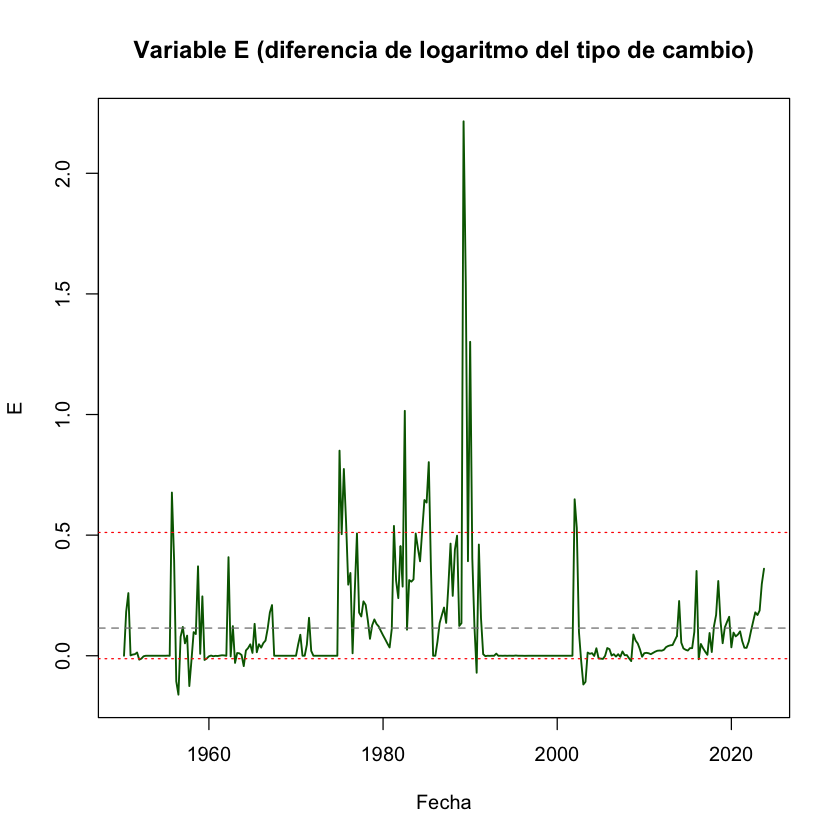

In [3]:
# Armar una fecha aproximada a partir de año + trimestre
trim_to_month <- c("1ºTr" = 1, "2ºTr" = 4, "3ºTr" = 7, "4ºTr" = 10)
fechas <- as.Date(paste(df_ERPT_Arg$año, trim_to_month[df_ERPT_Arg$trimestre], "01", sep = "-"))

plot(fechas, df_ERPT_Arg$E, type = "l", col = "darkgreen", lwd = 1.5,
     main = "Variable E (diferencia de logaritmo del tipo de cambio)",
     xlab = "Fecha", ylab = "E")
abline(h = mean(df_ERPT_Arg$E, na.rm = TRUE), col = "grey50", lty = 2)
abline(h = quantile(df_ERPT_Arg$E, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)

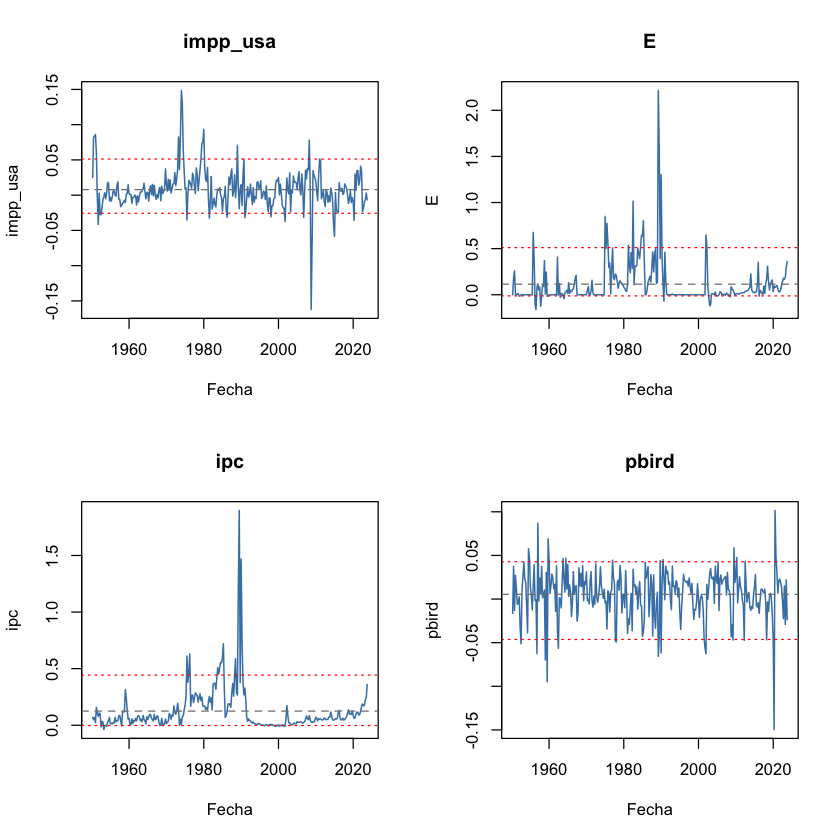

In [4]:
par(mfrow = c(2, 2))
for (v in c("impp_usa", "E", "ipc", "pbird")) {
  serie <- df_ERPT_Arg[[v]]
  plot(fechas, serie, type = "l", col = "steelblue", lwd = 1.2,
       main = v, xlab = "Fecha", ylab = v)
  abline(h = mean(serie, na.rm = TRUE), col = "grey50", lty = 2)
  abline(h = quantile(serie, c(0.05, 0.95), na.rm = TRUE), col = "red", lty = 3)
}
par(mfrow = c(1, 1))

In [6]:
# SIN CAPPEO: se usan los datos originales (df_ERPT_Arg), incluidos los valores extremos
vars_modelo <- c("impp_usa", "E", "ipc", "pbird")

cat("Desvíos estándar (datos sin cappear):\n")
print(sapply(df_ERPT_Arg[, vars_modelo], sd, na.rm = TRUE))

# Los 5 trimestres más extremos de E e ipc (los que antes quedaban recortados)
for (v in c("E", "ipc")) {
  o <- order(abs(df_ERPT_Arg[[v]]), decreasing = TRUE)[1:5]
  cat("\nTrimestres más extremos de", v, ":\n")
  print(data.frame(año = df_ERPT_Arg$año[o], trimestre = df_ERPT_Arg$trimestre[o],
                   valor = round(df_ERPT_Arg[[v]][o], 3)), row.names = FALSE)
}


Desvíos estándar (datos sin cappear):
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 



Trimestres más extremos de E :
  año trimestre valor
 1989      2ºTr 2.215
 1989      3ºTr 1.547
 1990      1ºTr 1.301
 1982      3ºTr 1.015
 1975      1ºTr 0.850

Trimestres más extremos de ipc :
  año trimestre valor
 1989      3ºTr 1.898
 1990      1ºTr 1.468
 1989      2ºTr 1.208
 1990      2ºTr 0.737
 1985      2ºTr 0.721


## Selección de rezagos con criterios de información (VAR lineal)

Antes de estimar los modelos no lineales: criterios AIC, HQ, SC (= BIC) y FPE para un VAR lineal con las mismas cuatro variables, de 1 a 8 rezagos, todos sobre la misma muestra. Además, el test de Portmanteau ajustado de los residuos del VAR lineal para cada número de rezagos (orientativo).

In [36]:
if (!requireNamespace("vars", quietly = TRUE)) install.packages("vars")
library(vars)

vars_modelo <- c("impp_usa", "E", "ipc", "pbird")
Y <- na.omit(df_ERPT_Arg[, vars_modelo])
cat("Observaciones:", nrow(Y), "\n\n")

sel <- VARselect(Y, lag.max = 8, type = "const")
cat("Rezagos elegidos por cada criterio (SC = BIC):\n")
print(sel$selection)
cat("\nValores de los criterios (menor = mejor):\n")
print(round(sel$criteria, 4))

# Portmanteau ajustado de los residuos del VAR lineal, para cada p (orientativo).
# El test necesita más rezagos que el VAR: si no, queda NA.
p_port <- function(v, L) if (L > v$p) round(unname(serial.test(v, lags.pt = L, type = "PT.adjusted")$serial$p.value), 3) else NA
port_lineal <- do.call(rbind, lapply(1:8, function(p) {
  v <- VAR(Y, p = p, type = "const")
  data.frame(rezagos = p,
             p_autocorr_8  = p_port(v, 8), p_autocorr_12 = p_port(v, 12))
}))
cat("\nPortmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):\n")
print(port_lineal, row.names = FALSE)


Observaciones: 295 

Rezagos elegidos por cada criterio (SC = BIC):
AIC(n)  HQ(n)  SC(n) FPE(n) 
     3      2      1      3 

Valores de los criterios (menor = mejor):
              1        2        3        4        5        6        7        8
AIC(n) -22.9630 -23.1669 -23.2285 -23.1974 -23.1955 -23.1449 -23.0632 -23.0267
HQ(n)  -22.8608 -22.9829 -22.9627 -22.8499 -22.7663 -22.6339 -22.4704 -22.3521
SC(n)  -22.7080 -22.7078 -22.5654 -22.3303 -22.1245 -21.8699 -21.5841 -21.3436
FPE(n)   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000

Portmanteau ajustado, VAR lineal (p-valor; < 0.05 = autocorrelación):
 rezagos p_autocorr_8 p_autocorr_12
       1        0.000         0.000
       2        0.000         0.011
       3        0.048         0.538
       4        0.049         0.568
       5        0.228         0.800
       6        0.386         0.863
       7        0.034         0.672
       8           NA         0.821


## TVAR p = 2 (especificación principal)

Se cargó exitosamente modelos preguardados  threshold_tvar_2_2_500_e9f2aea132c2dbca88b543e2af97bbb8.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


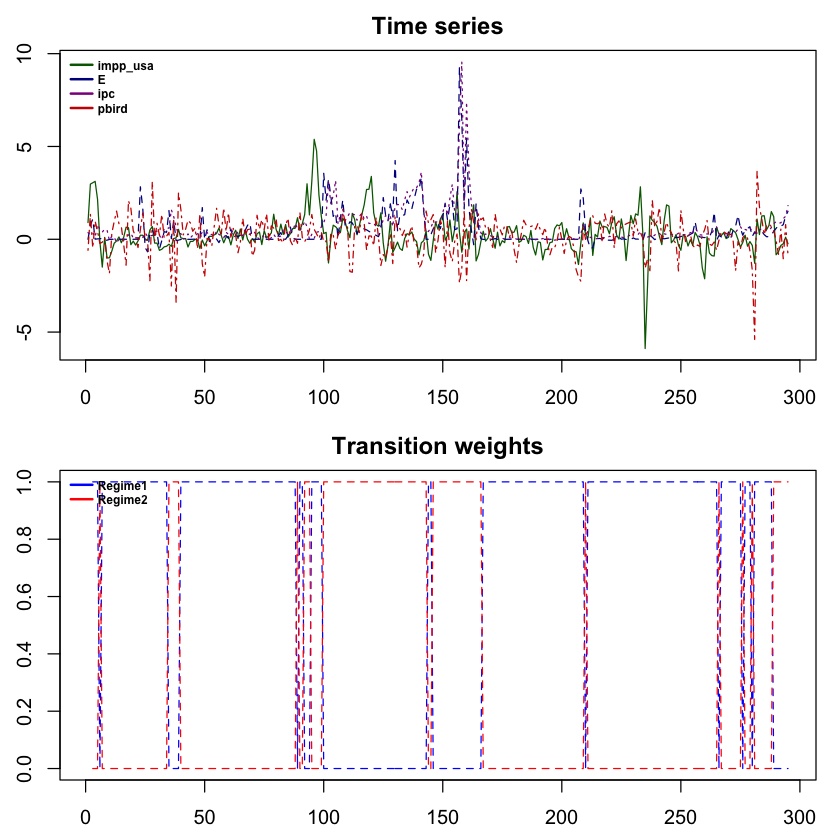

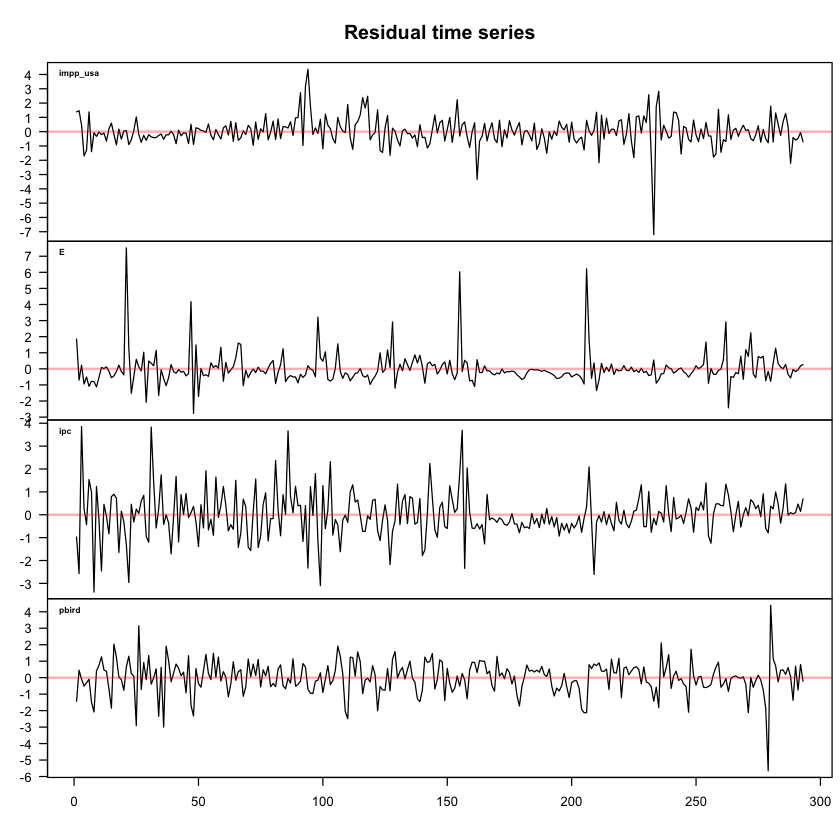

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



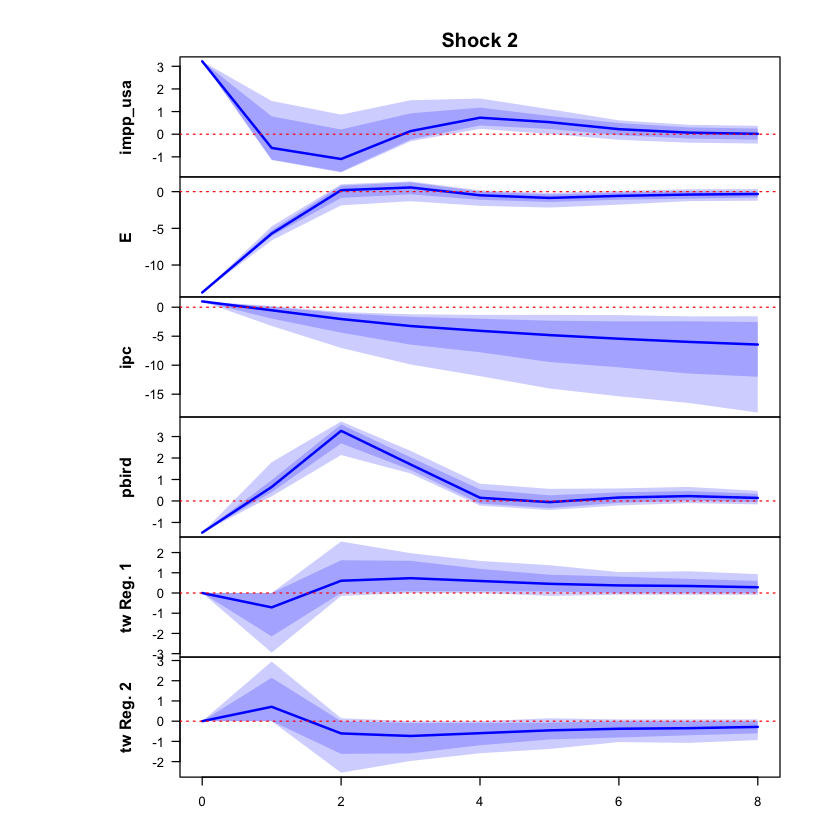

 >>> Linear IRF ( 1  shock units)


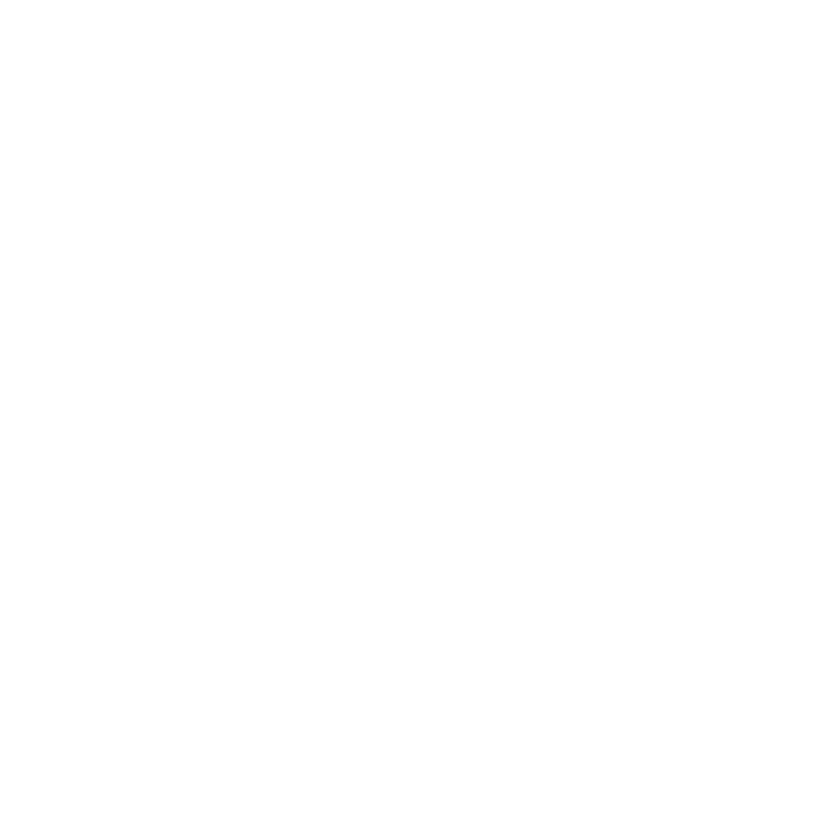

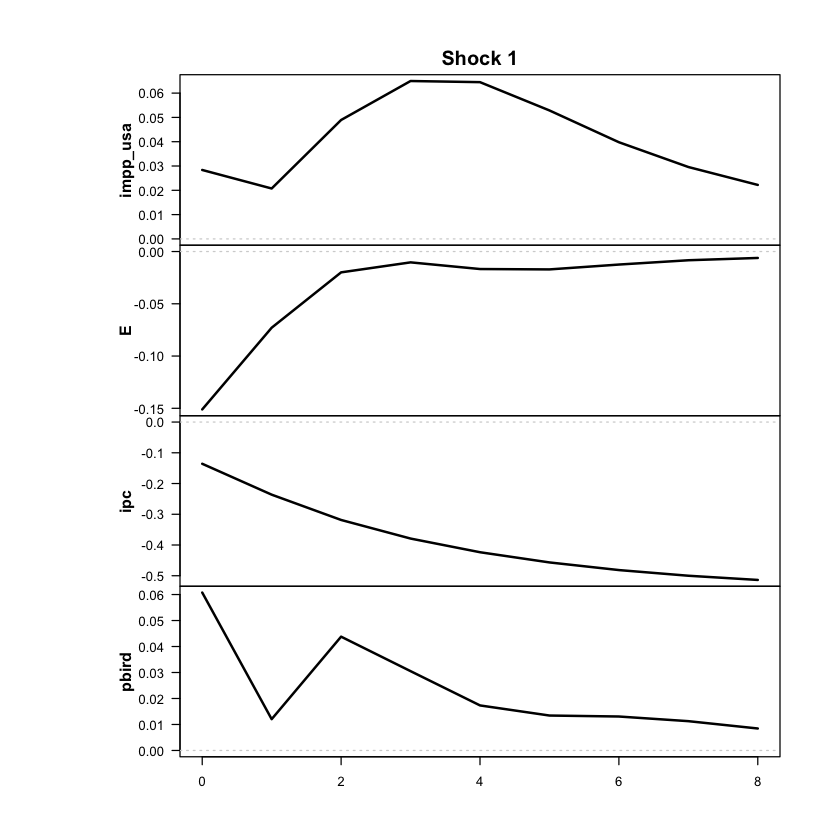

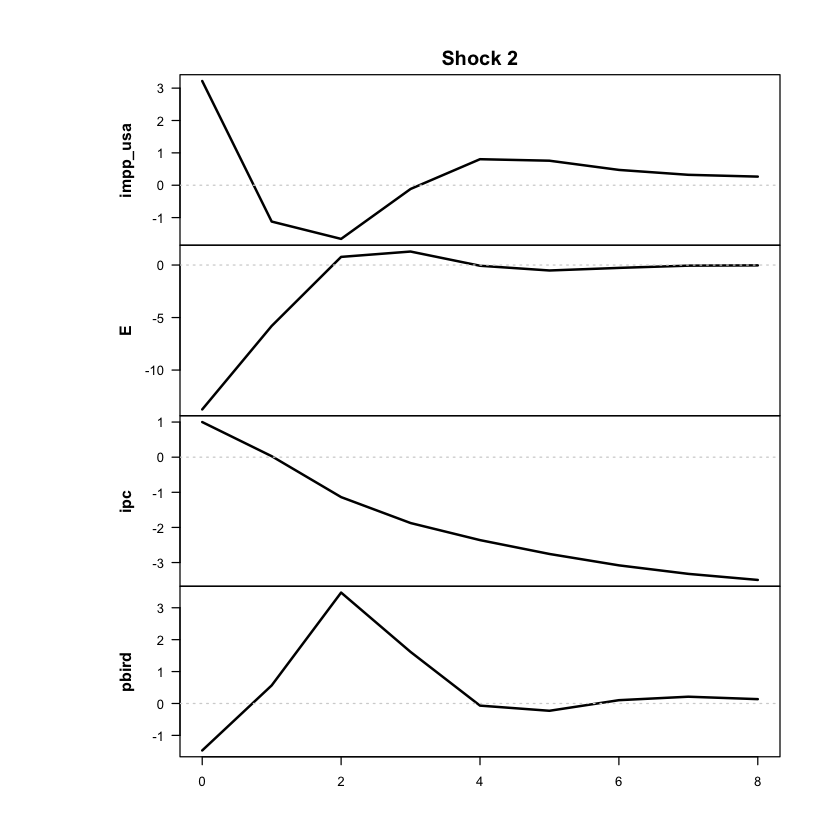

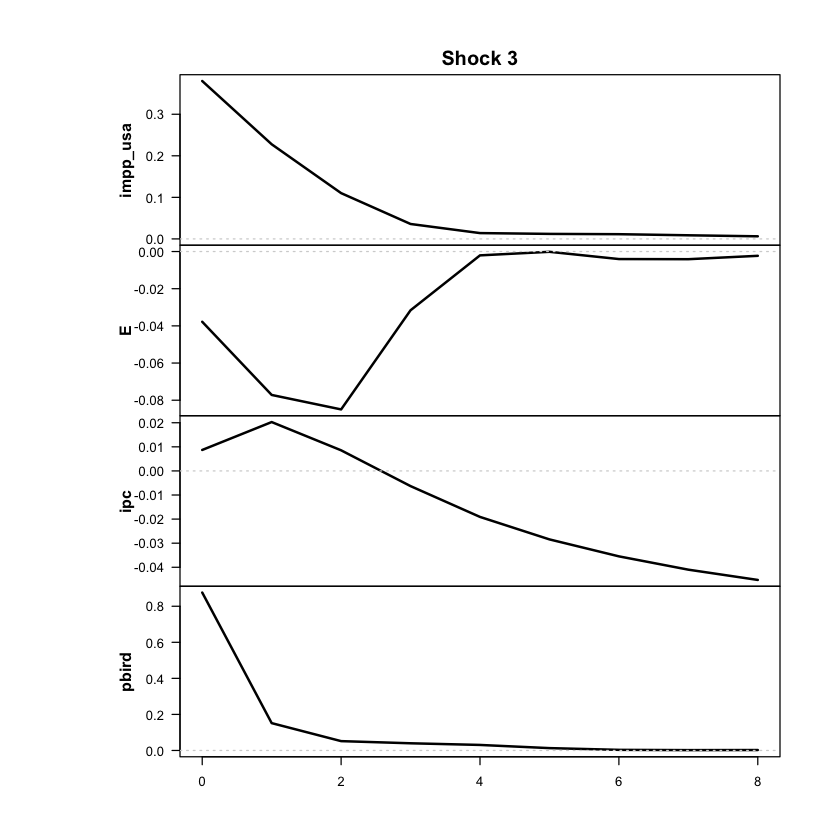

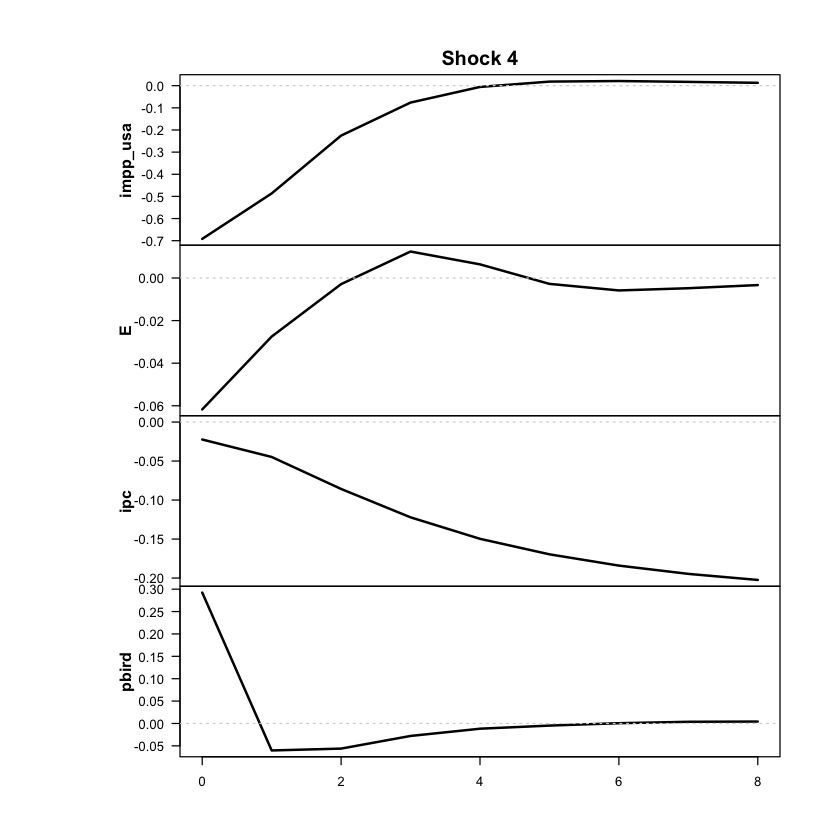

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



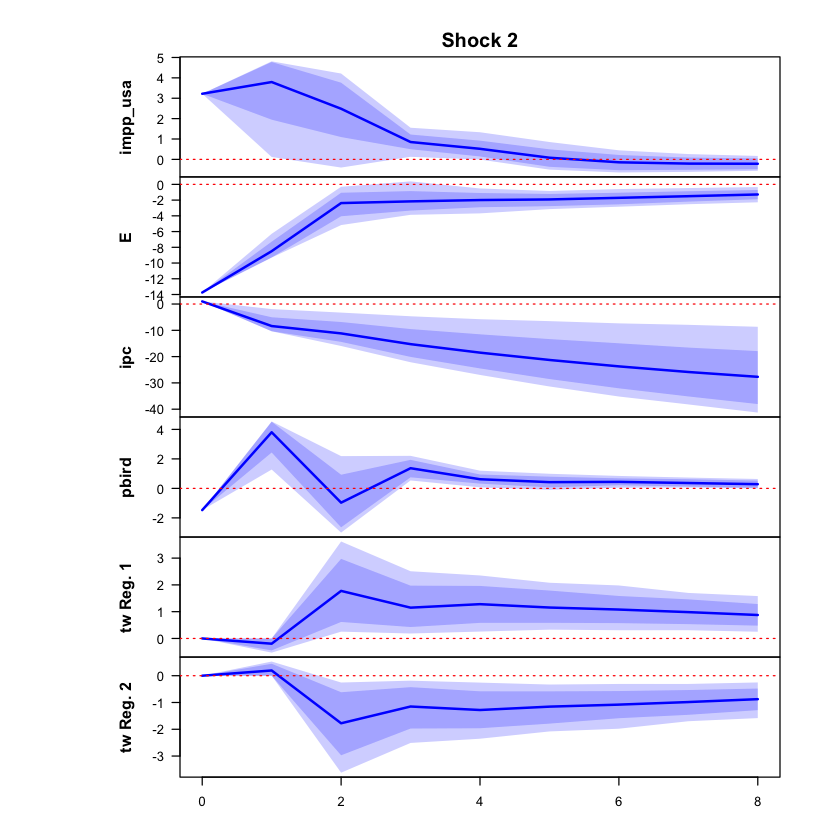

 >>> Linear IRF ( 1  shock units)


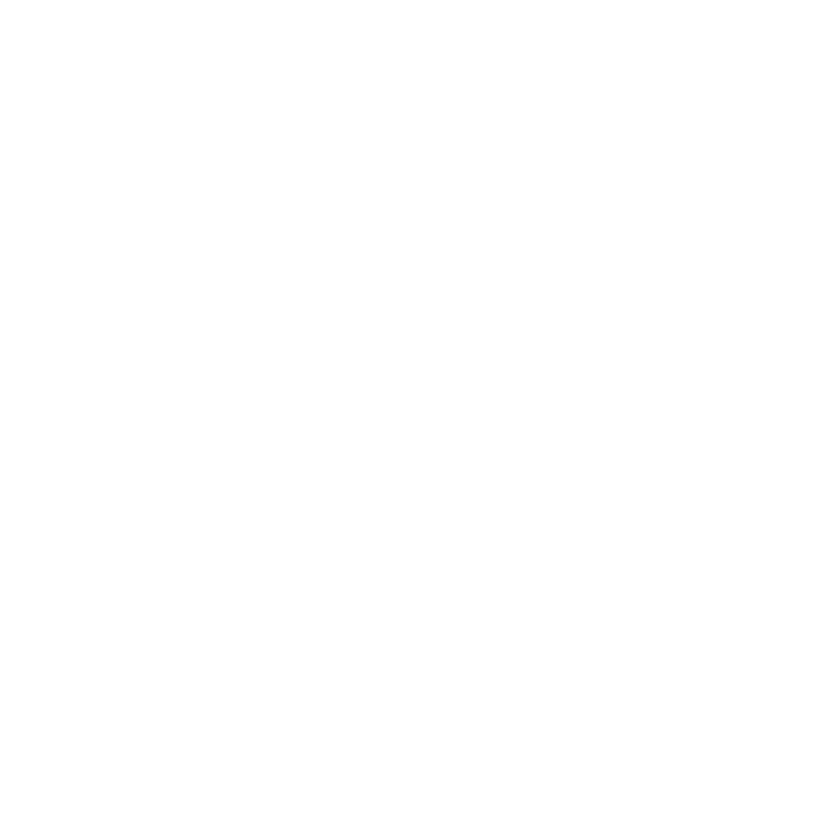

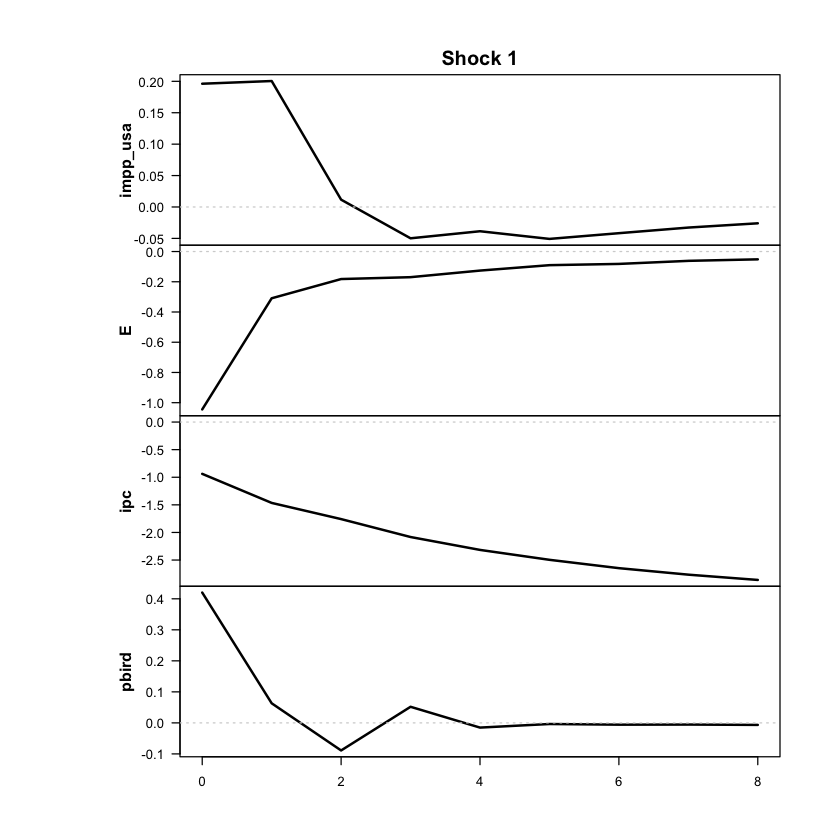

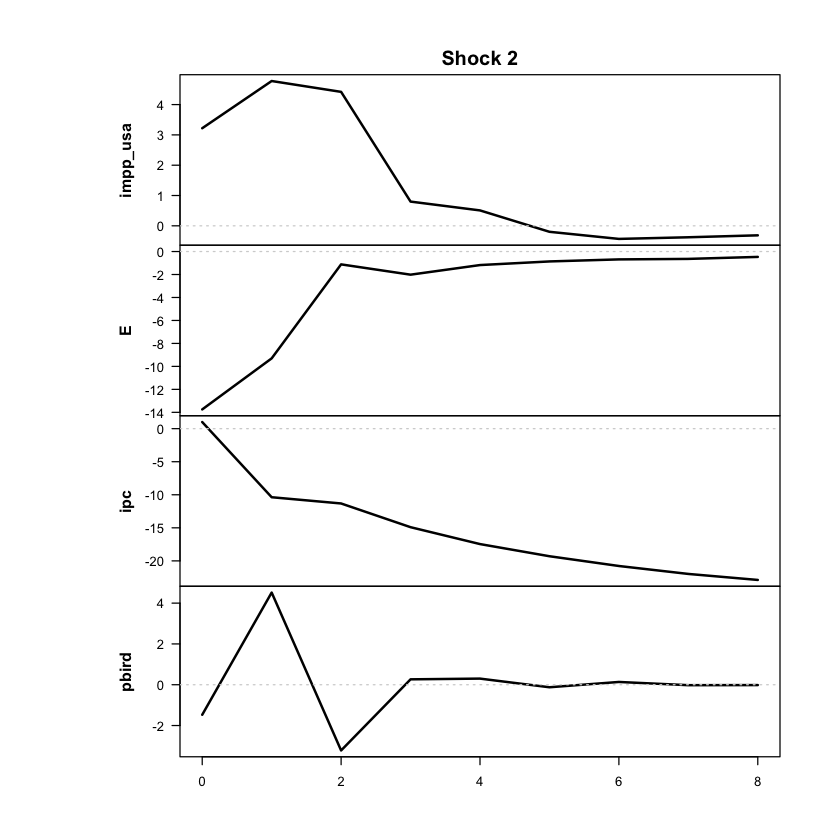

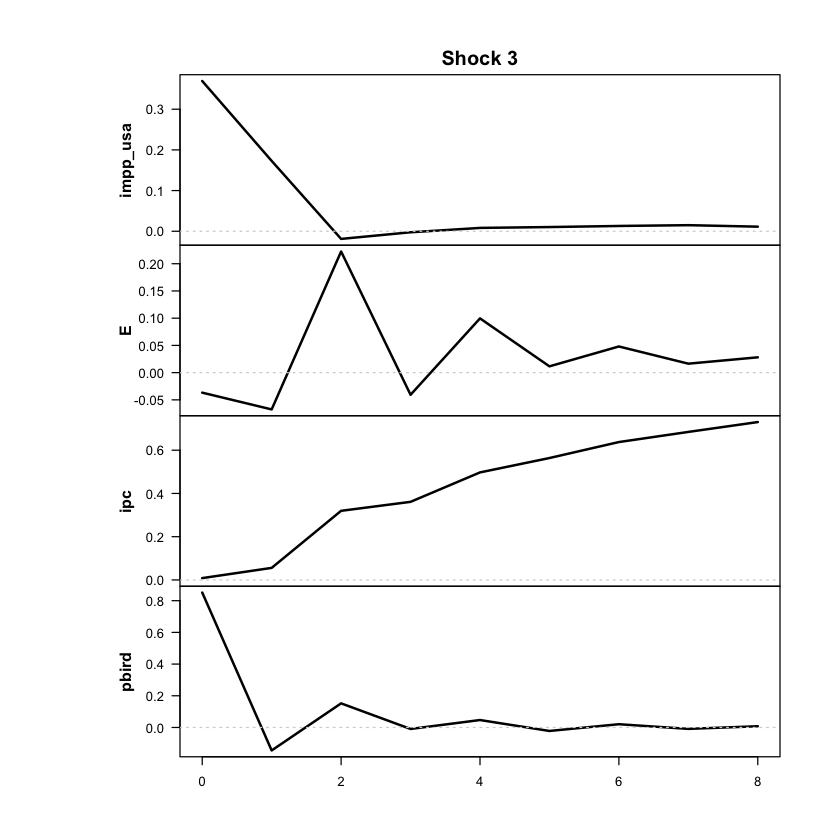

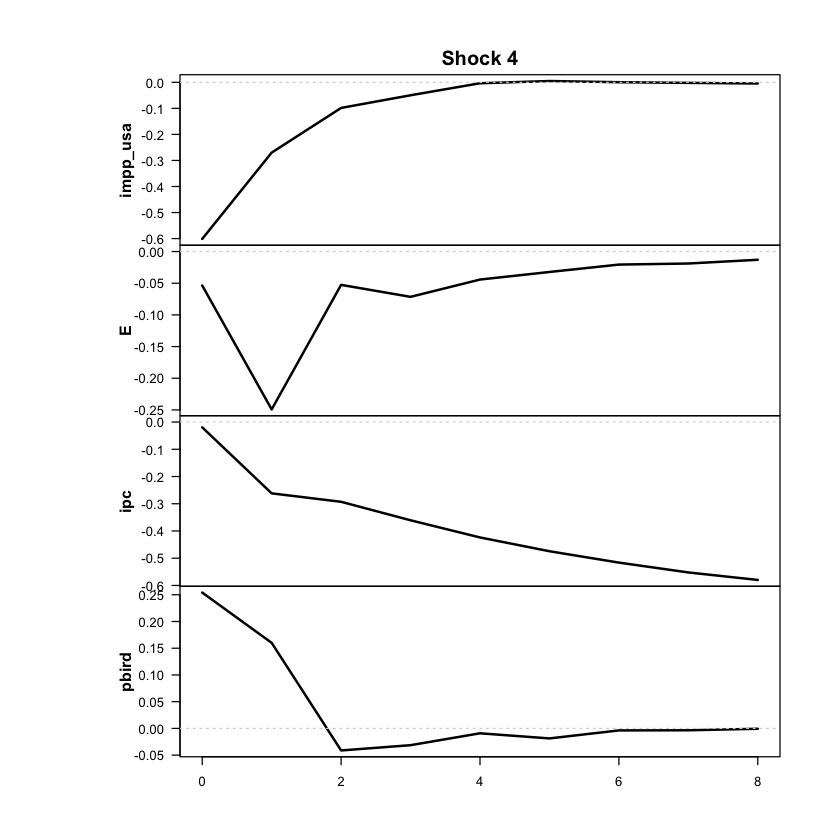

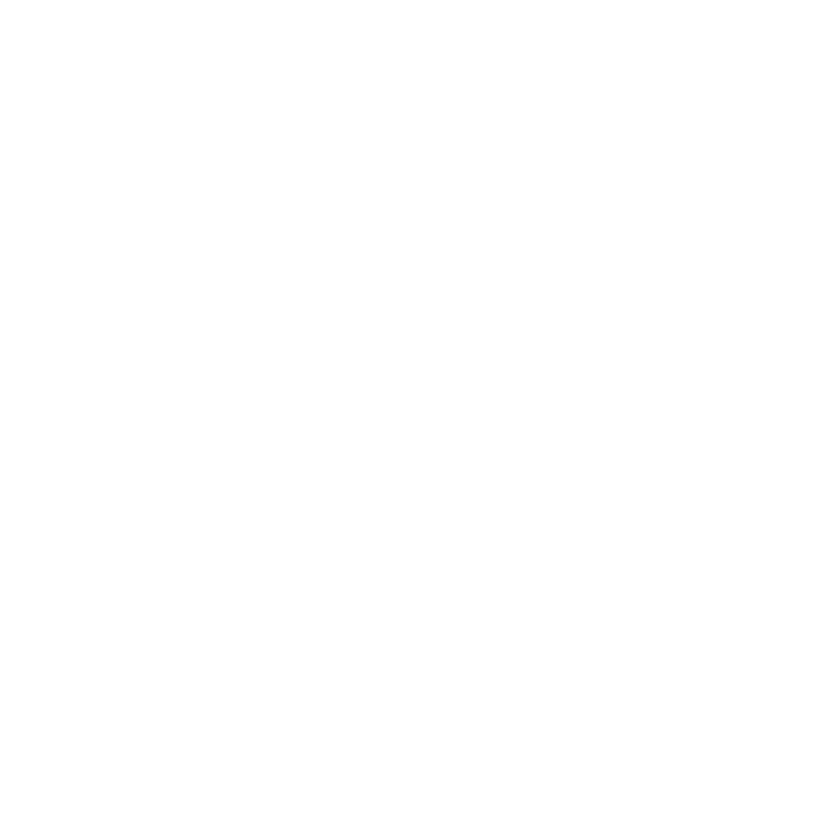

In [3]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [11]:
ic_tvar_p2 <- criterios_info(res, "TVAR p=2")
print(ic_tvar_p2)

    modelo regimenes parametros  loglik    AIC     HQ    BIC
1 TVAR p=2         2         93 -896.09 1978.2 2115.3 2320.4


In [12]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbrales: 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 207 | régimen 2 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.59      1.15
E             3.81     35.18
ipc           4.72     37.22
pbird         0.82     -0.12


In [13]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0008 -0.0021  0.0105 -0.0191
  E        -0.0362  0.0777 -0.0090 -0.0148
  ipc      -0.0269 -0.0047  0.0017 -0.0044
  pbird     0.0017  0.0010  0.0243  0.0081

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.71    0.97    0.04    0.08 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.745  -0.060  -0.191   0.301 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


In [14]:
print_passthrough(res, endog = c("impp_usa","E","ipc","pbird"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0604
1         1       0.0229
2         2       0.1121
3         3       0.1807
4         4       0.2278
5         5       0.2692
6         6       0.3081
7         7       0.3400
8         8       0.3669

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0      -0.0604
2         1      -0.0017
3         2       0.0686
4         3       0.1132
5         4       0.1425
6         5       0.1664
7         6       0.1859
8         7       0.2006
9         8       0.2110

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0604
1         1       0.4820
2         2       0.6374
3         3       0.8726
4         4       1.0596
5         5       1.2185
6         6       1.3577
7         7 

### ERPT y gráficos — TVAR p = 2

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.1%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0604  0.0124
         1  0.0220  0.0072
         2  0.1088 -0.0208
         3  0.1768 -0.0349
         4  0.2229 -0.0358
         5  0.2644 -0.0352
         6  0.3006 -0.0364
         7  0.3322 -0.0382
         8  0.3600 -0.0394

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0604  0.0124
         1  0.4620 -0.0170
         2  0.6218 -0.0114
         3  0.8542 -0.0234
         4  1.0392 -0.0283
         5  1.1978 -0.0316
         6  1.3350 -0.0350
         7  1.4548 -0.0380
         8  1.5592 -0.0404


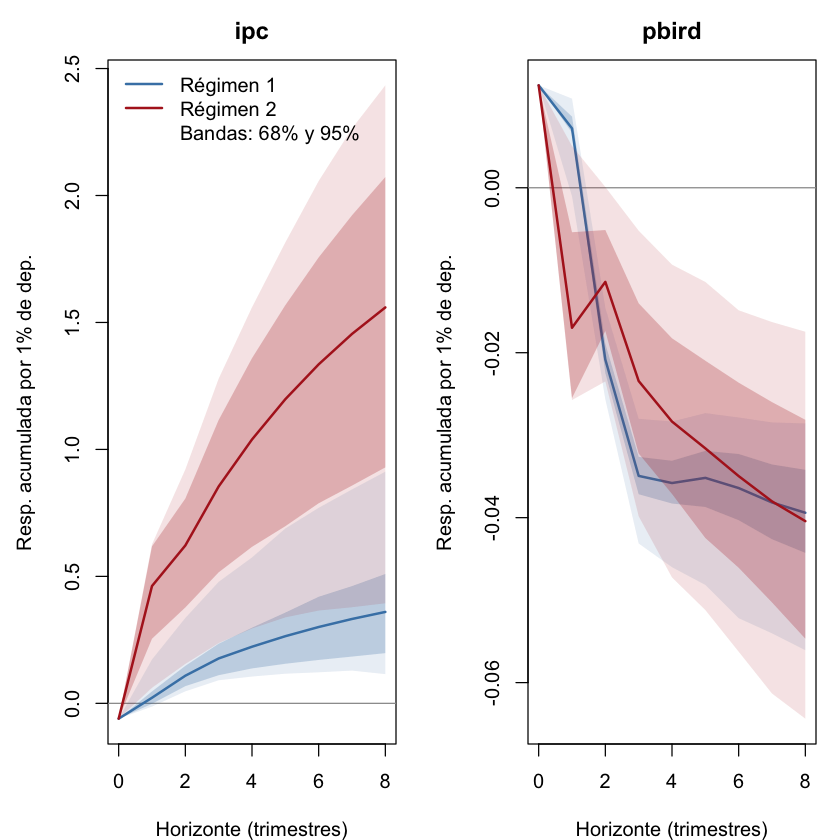


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0604  0.0124
         1 -0.0017  0.0076
         2  0.0686 -0.0217
         3  0.1132 -0.0353
         4  0.1425 -0.0347
         5  0.1664 -0.0328
         6  0.1859 -0.0337
         7  0.2006 -0.0355
         8  0.2110 -0.0366

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0604  0.0124
         1  0.6261 -0.0257
         2  0.6831  0.0015
         3  0.8997 -0.0007
         4  1.0539 -0.0033
         5  1.1649 -0.0022
         6  1.2540 -0.0034
         7  1.3265 -0.0032
         8  1.3814 -0.0030


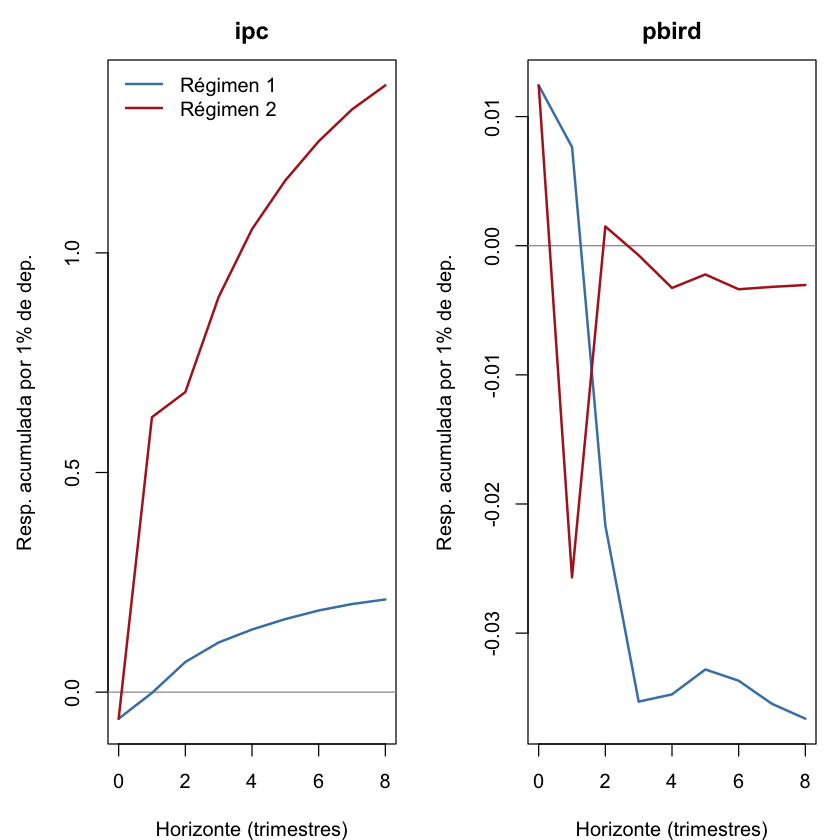

In [15]:
girf_impp_usa_tvar_p2 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                                        archivo = "girf_original_impp_usa_tvar_p2_sincap")
irf_impp_usa_tvar_p2  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                                       archivo = "irf_original_impp_usa_tvar_p2_sincap")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.1%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   pbird
         0 1.0000 -0.0604  0.0124
         1 1.4183  0.0220  0.0072
         2 1.3973  0.1088 -0.0208
         3 1.3515  0.1768 -0.0349
         4 1.3843  0.2229 -0.0358
         5 1.4436  0.2644 -0.0352
         6 1.4845  0.3006 -0.0364
         7 1.5123  0.3322 -0.0382
         8 1.5344  0.3600 -0.0394

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   pbird
         0 1.0000 -0.0604  0.0124
         1 1.6004  0.4620 -0.0170
         2 1.7605  0.6218 -0.0114
         3 1.9021  0.8542 -0.0234
         4 2.0409  1.0392 -0.0283
         5 2.1736  1.1978 -0.0316
         6 2.2892  1.3350 -0.0350
         7 2.3892  1.4548 -0.0380
         8 2.4770  1.5592 -0.0404


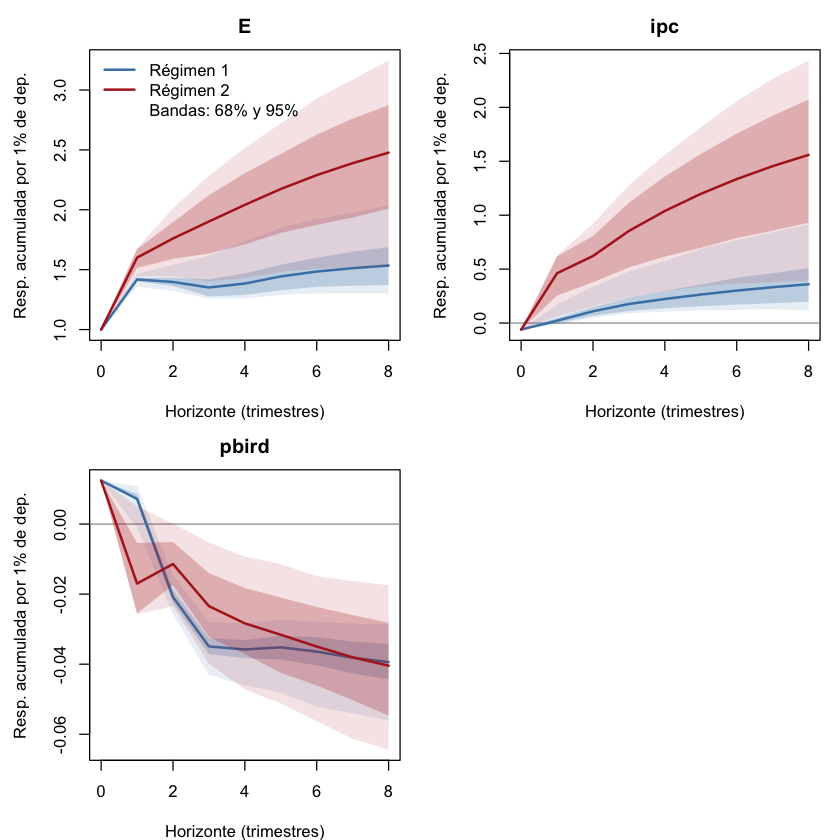

In [16]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                       variables = c("E", "ipc", "pbird"),
                       archivo = "girf_original_impp_usa_tvar_p2_con_E_sincap")

In [4]:
out_impp_usa_tvar_p2 <- erpt_historia(res, data = df_ERPT_Arg,
                             endog = c("impp_usa", "E", "ipc", "pbird"))

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.1%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 207 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0604           -0.0604
2         1            0.0180            0.4752
3         2            0.1018            0.6330
4         3            0.1630            0.8691
5         4            0.2095            1.0618
6         5            0.2482            1.2278
7         6            0.2877            1.3778
8         7            0.3238            1.5048
9         8            0.3537            1.6233

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0604          -0.0604
2         1          -0.0004           0.4904
3         2           0.0788           0.6478
4         3           0.1308           0.8907
5         4        

In [5]:
out_impp_usa_tvar_p2_acum <- erpt_historia(res, data = df_ERPT_Arg,
                                  endog = c("impp_usa", "E", "ipc", "pbird"),
                                  definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.1%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 207 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0604           -0.0604
2         1            0.0126            0.2935
3         2            0.0719            0.3543
4         3            0.1182            0.4473
5         4            0.1472            0.5068
6         5            0.1665            0.5494
7         6            0.1867            0.5804
8         7            0.2053            0.6059
9         8            0.2196            0.6254

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0604          -0.0604
2         1          -0.0003           0.3044
3         2           0.0572           0.3667
4         3           0.0987           0.4567
5         4        

In [6]:
saveRDS(out_impp_usa_tvar_p2,      "out_impp_usa_tvar_p2.rds")
saveRDS(out_impp_usa_tvar_p2_acum, "out_impp_usa_tvar_p2_acum.rds")

HTML widgets cannot be represented in plain text (need html)

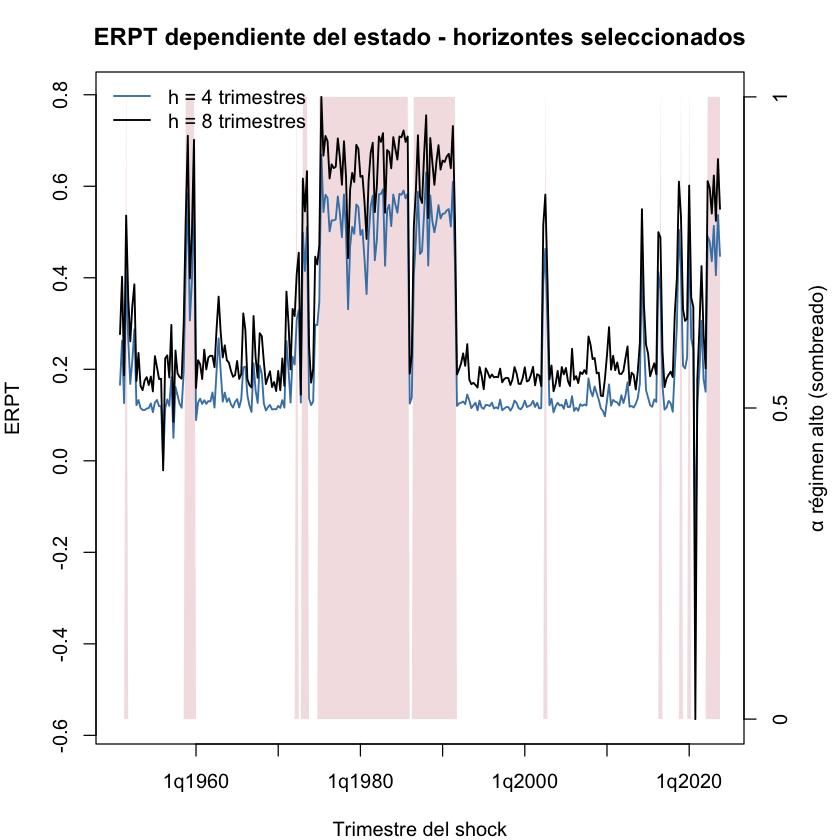

In [46]:
graficar_erpt(out_impp_usa_tvar_p2_acum, archivo = "erpt_impp_usa_tvar_p2_acum_sincap")

In [108]:
#Lo comento porque es feo, es de puntos (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_3d(out_impp_usa_tvar_p2_acum,
                         archivo = "erpt_regimen_3d_impp_usa_tvar_p2_acum_sincap")

ERROR: Error in parse(text = input): <text>:3:82: unexpected ')'
2: #graficar_erpt_regimen_3d(out_impp_usa_tvar_p2_acum,
3:                          archivo = "erpt_regimen_3d_impp_usa_tvar_p2_acum_sincap")
                                                                                    ^


In [109]:
#Lo comento porque es feo, es de rayas verticales (para bajar el tamaño de la notebook)
#graficar_erpt_regimen_red(out_impp_usa_tvar_p2_acum, h = 8,
                          archivo = "erpt_red_impp_usa_tvar_p2_acum_h8_sincap")

ERROR: Error in parse(text = input): <text>:3:79: unexpected ')'
2: #graficar_erpt_regimen_red(out_impp_usa_tvar_p2_acum, h = 8,
3:                           archivo = "erpt_red_impp_usa_tvar_p2_acum_h8_sincap")
                                                                                 ^


Promedio de ERPT por régimen (trimestres con peso > 0.9):
 horizonte reg_bajo_original reg_alto_original
         8              0.22             0.625


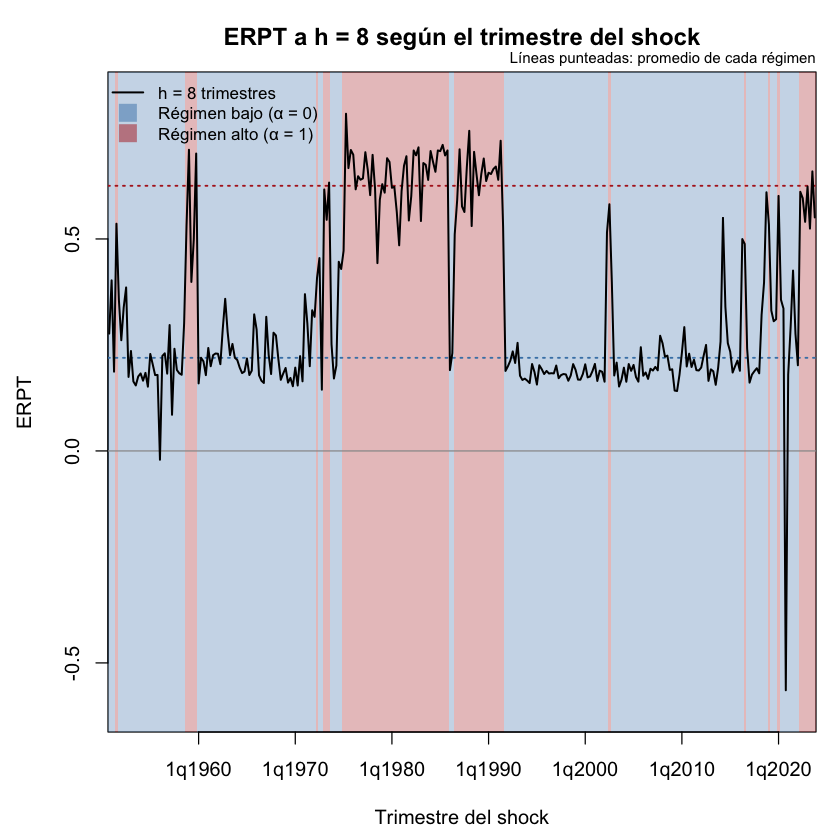

In [49]:
graficar_erpt_2d_bandas(out_impp_usa_tvar_p2_acum, horizontes = 8,
                        archivo = "erpt_2d_bandas_impp_usa_tvar_p2_acum_sincap")

HTML widgets cannot be represented in plain text (need html)

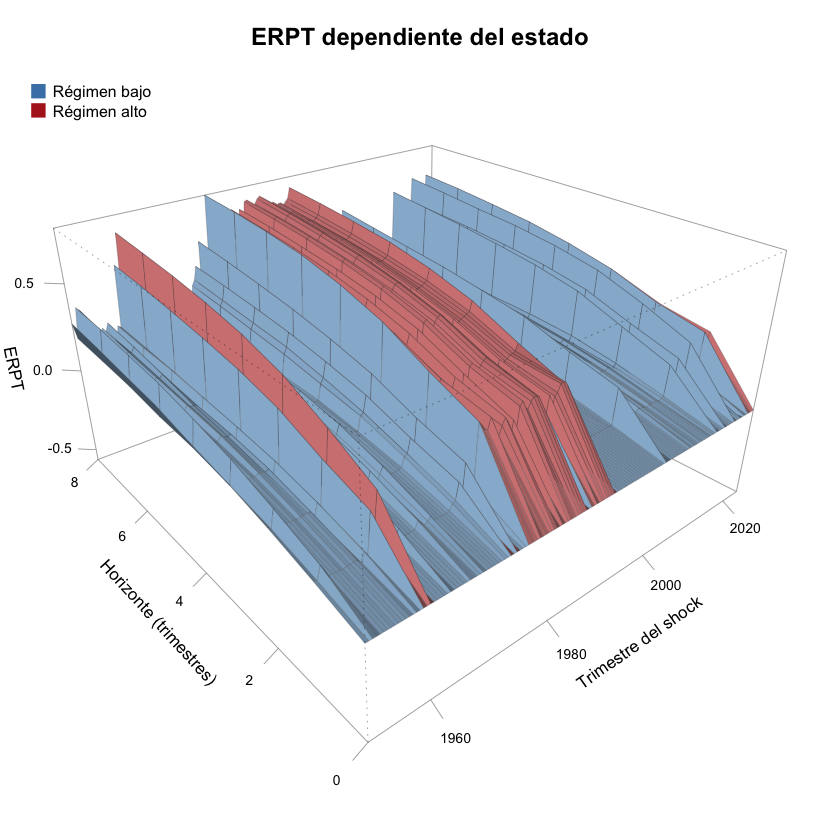

In [50]:
graficar_erpt_manta(out_impp_usa_tvar_p2_acum, cada = 2,
                    archivo = "erpt_manta_impp_usa_tvar_p2_acum_c2_sincap")

In [110]:
#Lo comenté porque es muy parecido al anterior, así achico la notebook
#graficar_erpt_manta(out_impp_usa_tvar_p2_acum, archivo = "erpt_manta_impp_usa_tvar_p2_acum_c1_sincap")

In [111]:
#Lo comenté para achicar la notebook, total es muy parecido a los anteriores.
#graficar_erpt_manta(out_impp_usa_tvar_p2_acum, cada = 2, theta = -25, phi = 30,
                    archivo = "erpt_manta_impp_usa_tvar_p2_acum_c2_theta25_sincap")

ERROR: Error in parse(text = input): <text>:3:83: unexpected ')'
2: #graficar_erpt_manta(out_impp_usa_tvar_p2_acum, cada = 2, theta = -25, phi = 30,
3:                     archivo = "erpt_manta_impp_usa_tvar_p2_acum_c2_theta25_sincap")
                                                                                     ^


El gif a continuación es muy, muy claro. USAR esta versión

In [53]:
guardar_gif_erpt_h(out_impp_usa_tvar_p2_acum, h = 8,
                   archivo = "gif_erpt_h8_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_erpt_h8_impp_usa_tvar_p2_acum_sincap.gif



In [54]:
guardar_gif_erpt_h(out_impp_usa_tvar_p2_acum, h = 8,
                   marcas = c("3q1975", "3q1989", "1q2002", "2q2018"),
                   archivo = "gif_erpt_h8_marcas_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_erpt_h8_marcas_impp_usa_tvar_p2_acum_sincap.gif



GIF 3d modo "construir"

In [55]:
guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = "construir",
                  archivo = "gif_manta_construir_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_manta_construir_impp_usa_tvar_p2_acum_sincap.gif



In [56]:
guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = "construir",
                  marcas = c("3q1975", "3q1989", "1q2002", "2q2018"),
                  archivo = "gif_manta_construir_marcas_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_manta_construir_marcas_impp_usa_tvar_p2_acum_sincap.gif



GIF 3d modo "rotar"

In [57]:
guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = "rotar",
                  archivo = "gif_manta_rotar_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_manta_rotar_impp_usa_tvar_p2_acum_sincap.gif



In [58]:
guardar_gif_manta(out_impp_usa_tvar_p2_acum, modo = "rotar",
                  marcas = c("3q1975", "3q1989", "1q2002", "2q2018"),
                  archivo = "gif_manta_rotar_marcas_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_manta_rotar_marcas_impp_usa_tvar_p2_acum_sincap.gif



In [59]:
graficar_slider(out_impp_usa_tvar_p2_acum, archivo = "slider_impp_usa_tvar_p2_acum_sincap")

HTML widgets cannot be represented in plain text (need html)

 horizonte  1q1988  2q1988  3q1988  4q1988
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.3542  0.2495  0.3649  0.3219
         2  0.4499  0.2922  0.4205  0.3710
         3  0.5578  0.3743  0.5186  0.4603
         4  0.6303  0.4268  0.5800  0.5241
         5  0.6806  0.4636  0.6266  0.5723
         6  0.7101  0.4884  0.6595  0.6075
         7  0.7372  0.5135  0.6853  0.6327
         8  0.7551  0.5305  0.7054  0.6528


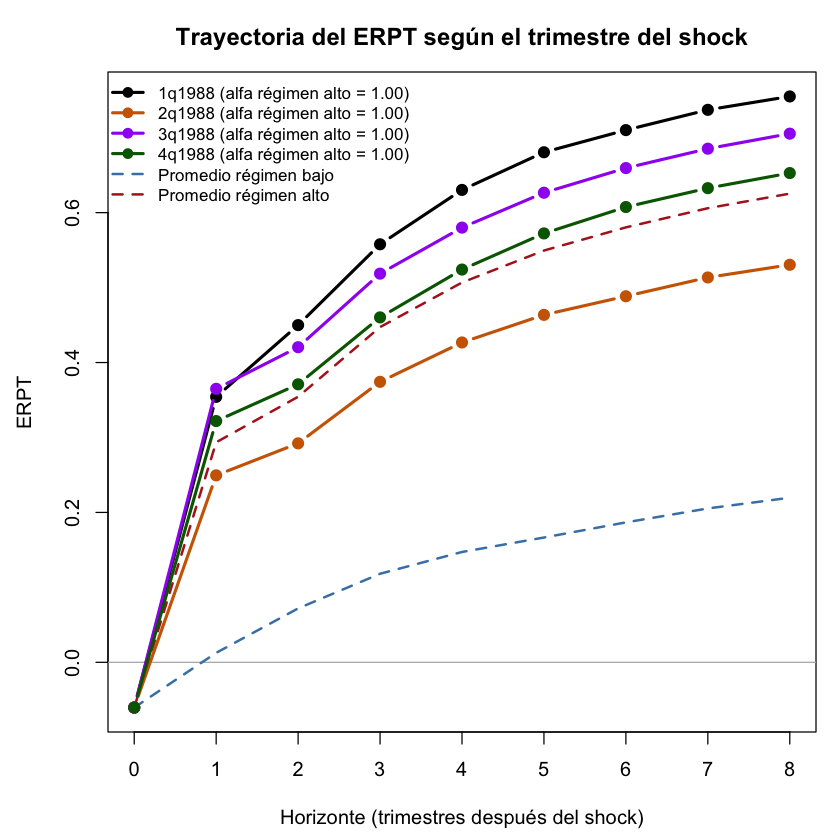

In [75]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("1q1988", "2q1988", "3q1988", "4q1988"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

 horizonte  4q1974  1q1975  2q1975  3q1975
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.0614  0.1482  0.3734  0.3294
         2  0.1472  0.2121  0.4761  0.3853
         3  0.2344  0.2950  0.5936  0.4802
         4  0.2966  0.3477  0.6692  0.5436
         5  0.3466  0.3886  0.7237  0.5922
         6  0.3841  0.4184  0.7559  0.6254
         7  0.4080  0.4488  0.7790  0.6487
         8  0.4291  0.4721  0.7953  0.6671


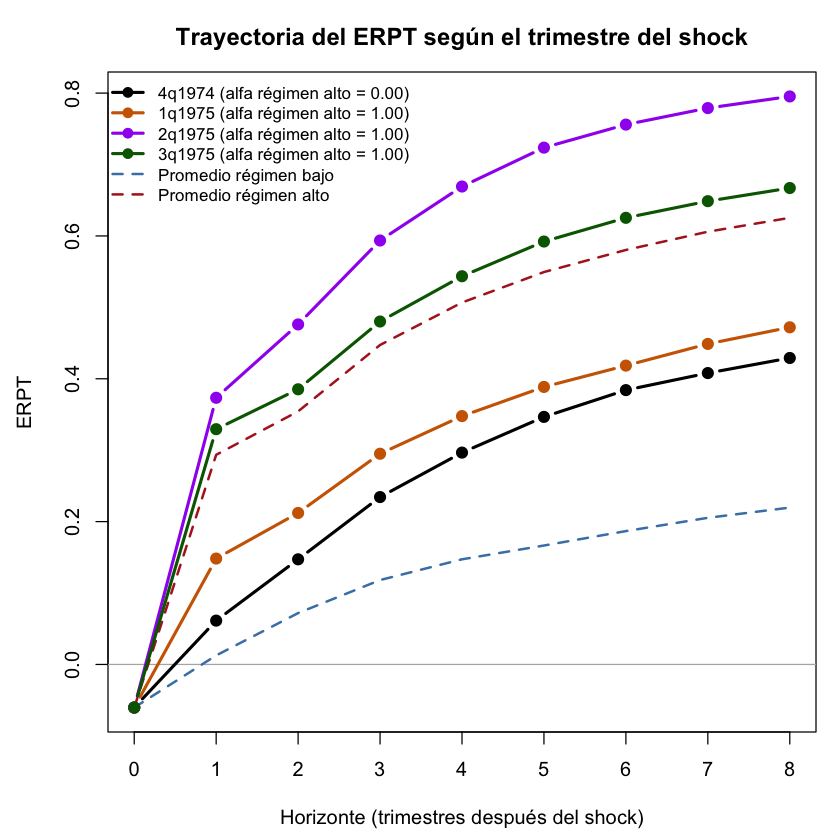

In [73]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("4q1974", "1q1975", "2q1975", "3q1975"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

 horizonte  1q1989  2q1989  3q1989  4q1989
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.3035  0.3343  0.3734  0.3734
         2  0.3519  0.3772  0.4024  0.3894
         3  0.4397  0.4640  0.4971  0.4736
         4  0.4994  0.5236  0.5587  0.5295
         5  0.5382  0.5716  0.6028  0.5685
         6  0.5680  0.6065  0.6379  0.5980
         7  0.5851  0.6302  0.6670  0.6203
         8  0.6031  0.6538  0.6897  0.6366


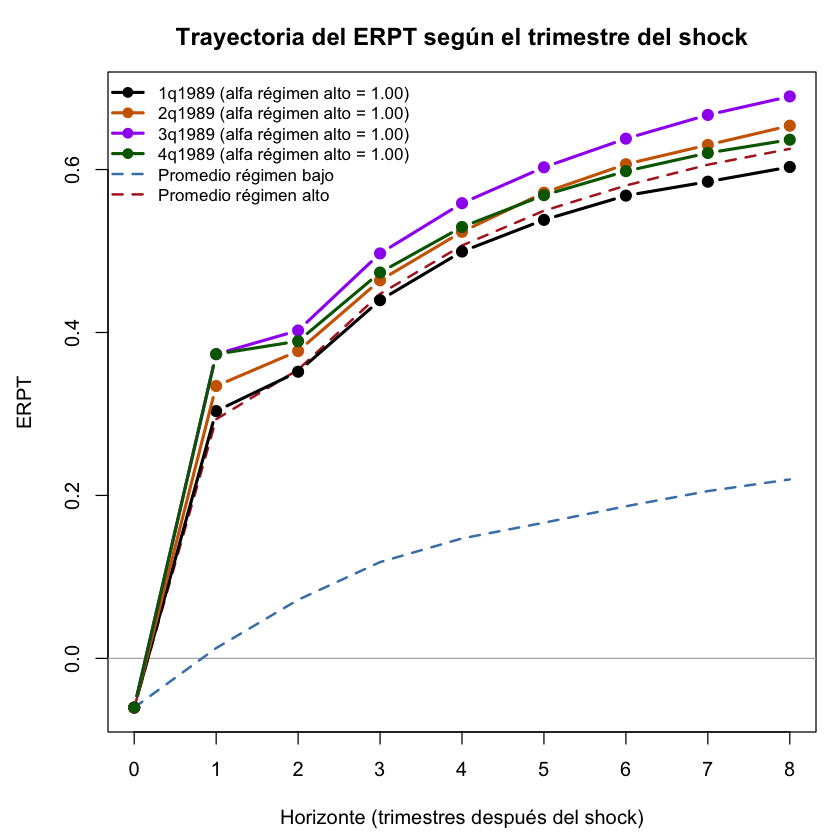

In [76]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("1q1989", "2q1989", "3q1989", "4q1989"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

 horizonte  1q1990  2q1990  3q1990  4q1990
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.3734  0.3734  0.3726  0.3678
         2  0.3910  0.3929  0.3940  0.3997
         3  0.4803  0.4810  0.4840  0.4900
         4  0.5399  0.5403  0.5471  0.5501
         5  0.5822  0.5808  0.5891  0.5910
         6  0.6147  0.6110  0.6206  0.6251
         7  0.6383  0.6356  0.6468  0.6496
         8  0.6562  0.6531  0.6650  0.6708


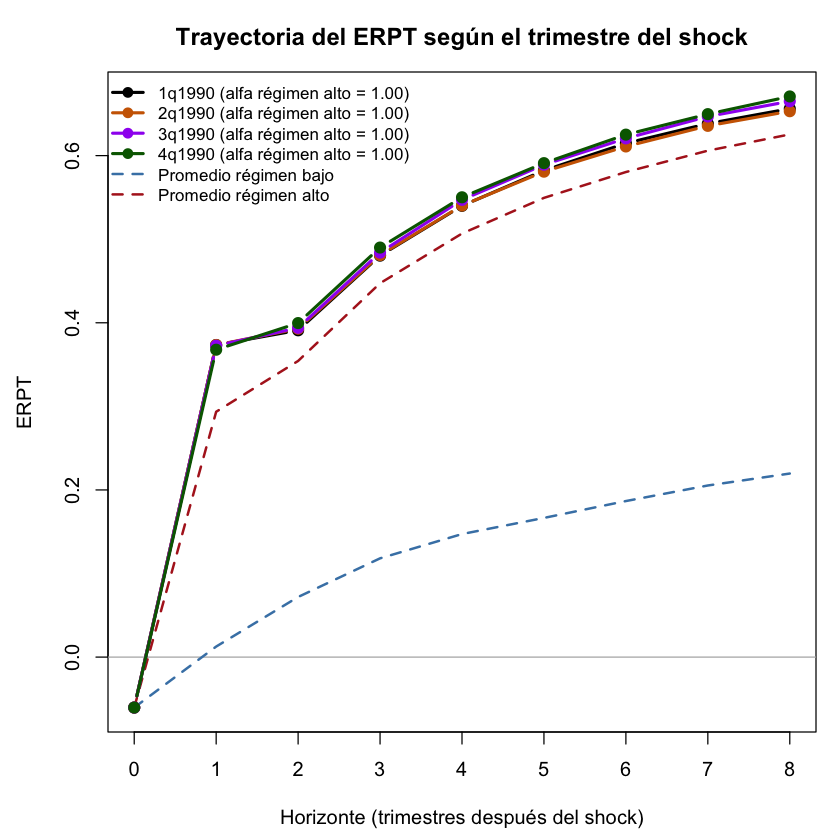

In [78]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("1q1990", "2q1990", "3q1990", "4q1990"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

 horizonte  1q1991  2q1991  3q1991  4q1991
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.3176  0.3411  0.2539 -0.0020
         2  0.3618  0.4345  0.3003  0.0534
         3  0.4510  0.5405  0.3805  0.0905
         4  0.5121  0.6098  0.4320  0.1200
         5  0.5573  0.6589  0.4664  0.1320
         6  0.5907  0.6881  0.4891  0.1548
         7  0.6172  0.7125  0.5132  0.1734
         8  0.6395  0.7316  0.5310  0.1887


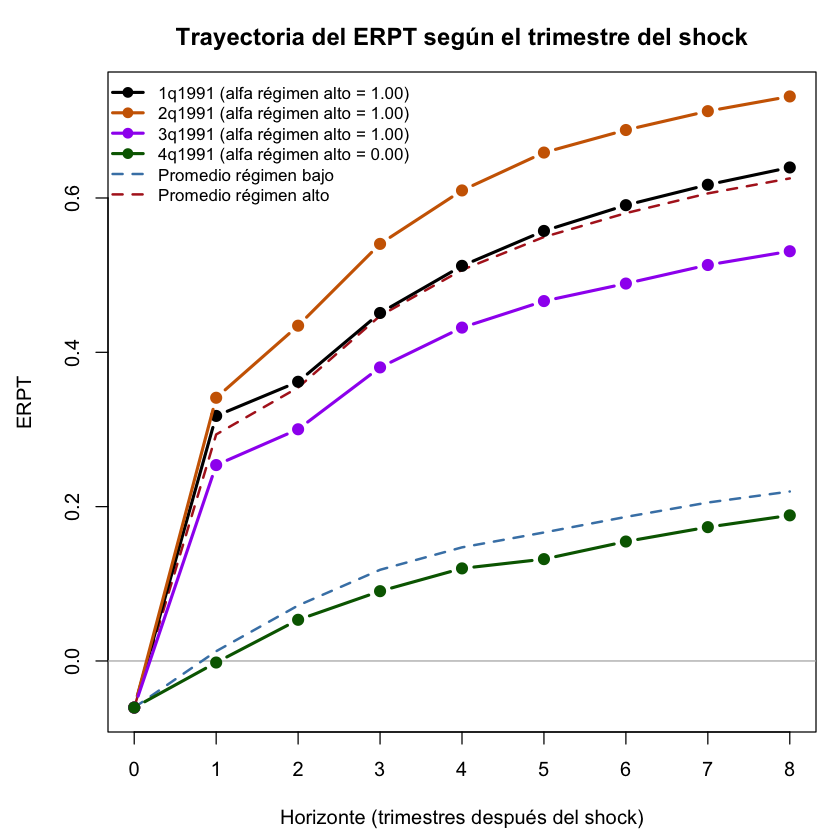

In [79]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("1q1991", "2q1991", "3q1991", "4q1991"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

 horizonte  4q1950  1q1983  3q1988  3q2002
         0 -0.0604 -0.0604 -0.0604 -0.0604
         1  0.0111  0.2407  0.3649  0.2653
         2  0.0745  0.2844  0.4205  0.3189
         3  0.1272  0.3693  0.5186  0.4065
         4  0.1662  0.4264  0.5800  0.4632
         5  0.2108  0.4695  0.6266  0.5083
         6  0.2329  0.5009  0.6595  0.5396
         7  0.2576  0.5232  0.6853  0.5632
         8  0.2767  0.5423  0.7054  0.5818


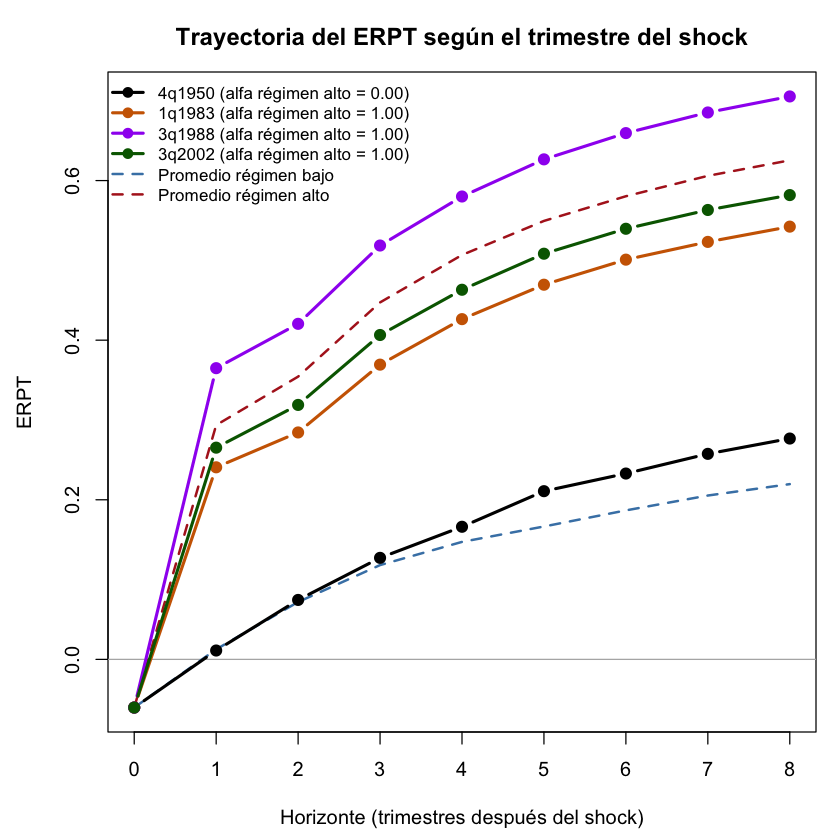

In [21]:
graficar_trayectorias(out_impp_usa_tvar_p2_acum,
                      trimestres = c("4q1950", "1q1983", "3q1988", "3q2002"),
                      archivo = "trayectorias_impp_usa_tvar_p2_acum_sincap")

In [61]:
guardar_gif(out_impp_usa_tvar_p2_acum, archivo = "gif_impp_usa_tvar_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_impp_usa_tvar_p2_acum_sincap.gif



In [62]:
guardar_gif(out_impp_usa_tvar_p2_acum, archivo = "gif_impp_usa_tvar_p2_acum_lento_sincap",
            segundos_por_cuadro = 0.5, cada = 2)

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_impp_usa_tvar_p2_acum_lento_sincap.gif



  horizonte reg_bajo_original reg_alto_original
1         0           -0.0604           -0.0604
2         1            0.0730            0.3539
3         2            0.0593            0.0608
4         3            0.0462            0.0930
5         4            0.0291            0.0595
6         5            0.0193            0.0427
7         6            0.0202            0.0309
8         7            0.0186            0.0256
9         8            0.0143            0.0195


HTML widgets cannot be represented in plain text (need html)

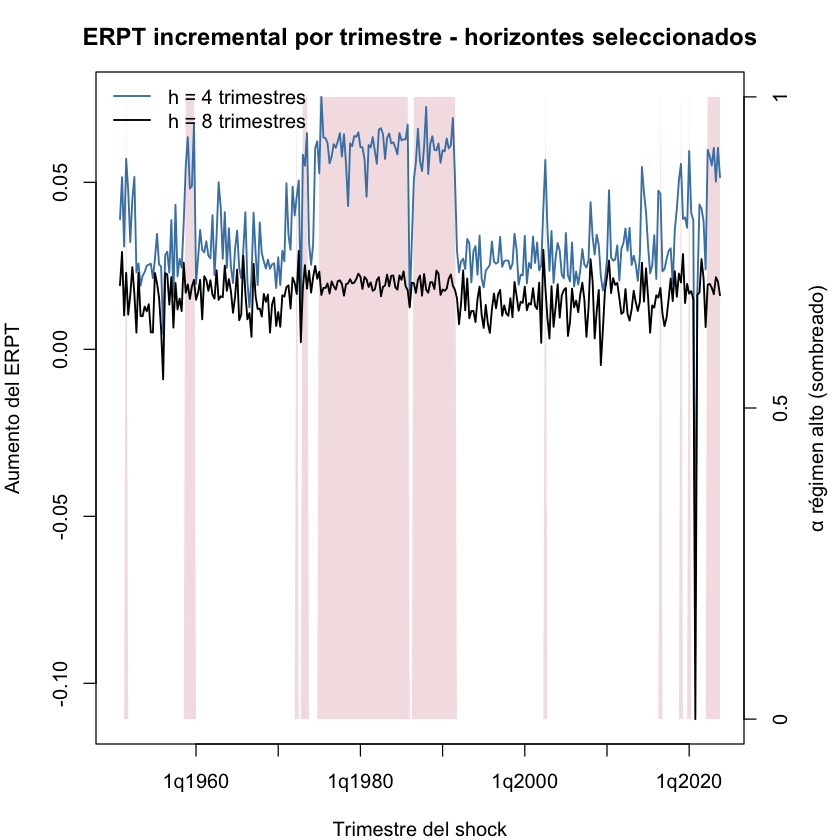

In [63]:
inc_impp_usa_tvar_p2_acum <- erpt_incremental(out_impp_usa_tvar_p2_acum)
graficar_erpt(inc_impp_usa_tvar_p2_acum, archivo = "erpt_impp_usa_tvar_p2_acum_incremental_sincap",
              titulo = "ERPT incremental por trimestre", eje_z = "Aumento del ERPT")

HTML widgets cannot be represented in plain text (need html)

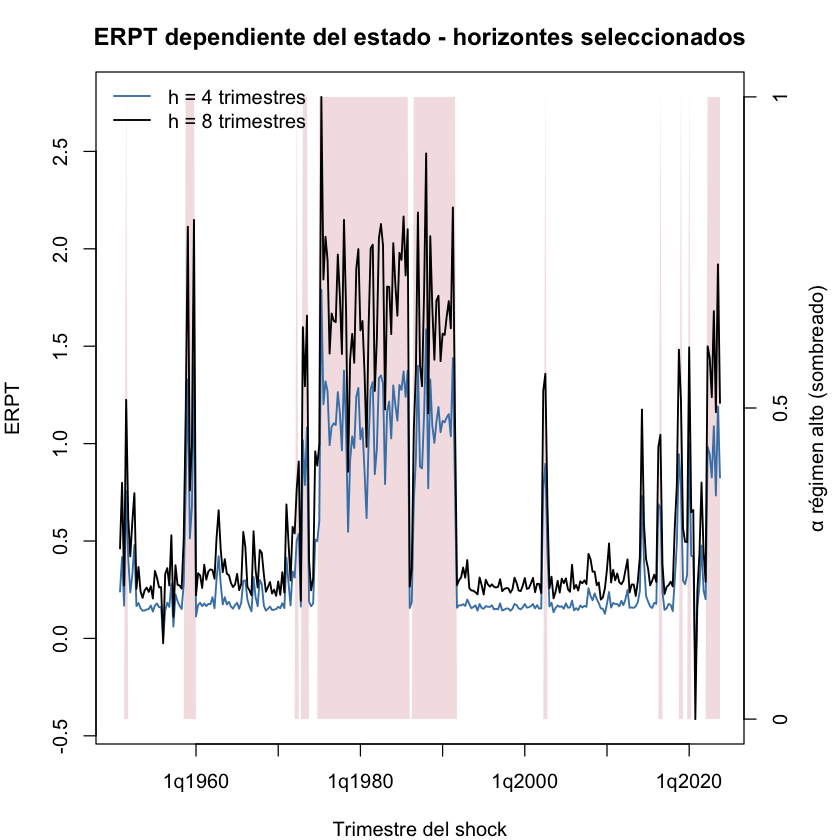

In [64]:
graficar_erpt(out_impp_usa_tvar_p2, archivo = "erpt_impp_usa_tvar_p2_sincap")

In [65]:
graficar_slider(out_impp_usa_tvar_p2, archivo = "slider_impp_usa_tvar_p2_sincap")

HTML widgets cannot be represented in plain text (need html)

 horizonte  2q1975  3q1975  1q2014
         0 -0.0604 -0.0604 -0.0604
         1  0.6261  0.5357  0.0179
         2  0.9843  0.7035  0.1165
         3  1.4192  0.9694  0.1964
         4  1.7897  1.2019  0.2434
         5  2.0993  1.3890  0.2944
         6  2.3598  1.5619  0.3518
         7  2.5736  1.6966  0.3917
         8  2.7799  1.8428  0.4188


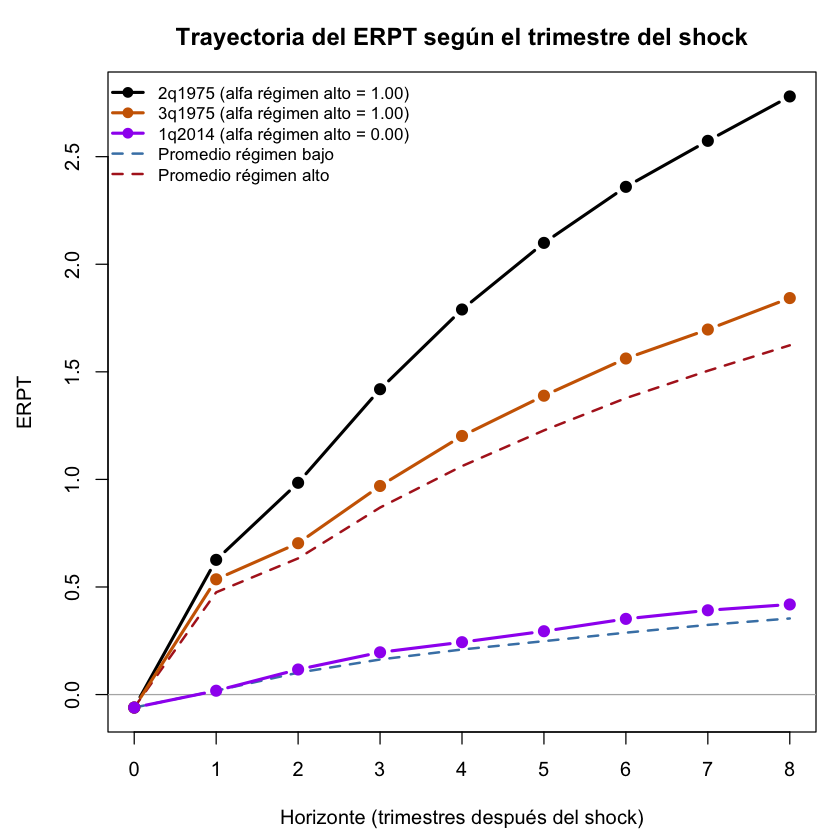

In [70]:
graficar_trayectorias(out_impp_usa_tvar_p2,
                      trimestres = c("2q1975", "3q1975", "1q2014"),
                      archivo = "trayectorias_impp_usa_tvar_p2_sincap")

 horizonte  1q1995  1q1985  2q2021
         0 -0.0604 -0.0604 -0.0604
         1 -0.0025  0.6219  0.0728
         2  0.0666  0.7736  0.1559
         3  0.1262  1.0601  0.2003
         4  0.1523  1.2758  0.2703
         5  0.1618  1.4688  0.3271
         6  0.1860  1.6527  0.3682
         7  0.2146  1.8043  0.4032
         8  0.2253  1.9432  0.4342


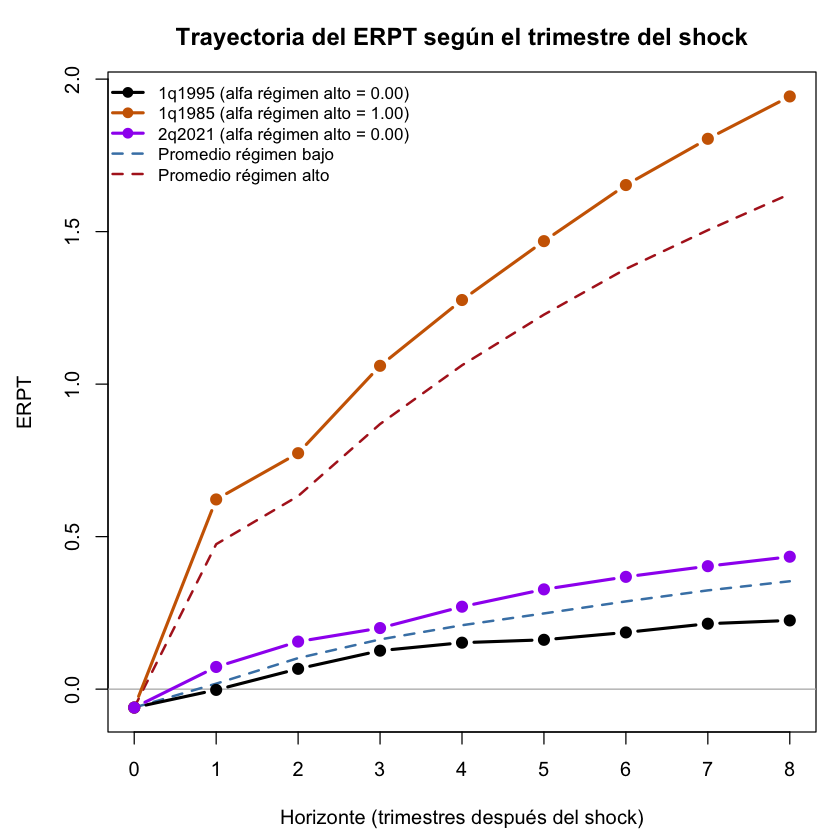

In [66]:
graficar_trayectorias(out_impp_usa_tvar_p2,
                      trimestres = c("1q1995", "1q1985", "2q2021"),
                      archivo = "trayectorias_impp_usa_tvar_p2_sincap")

In [67]:
guardar_gif(out_impp_usa_tvar_p2, archivo = "gif_impp_usa_tvar_p2_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_impp_usa_tvar_p2_sincap.gif



  horizonte reg_bajo_original reg_alto_original
1         0           -0.0604           -0.0604
2         1            0.0783            0.5356
3         2            0.0838            0.1578
4         3            0.0612            0.2361
5         4            0.0465            0.1927
6         5            0.0387            0.1659
7         6            0.0395            0.1500
8         7            0.0362            0.1270
9         8            0.0299            0.1185


HTML widgets cannot be represented in plain text (need html)

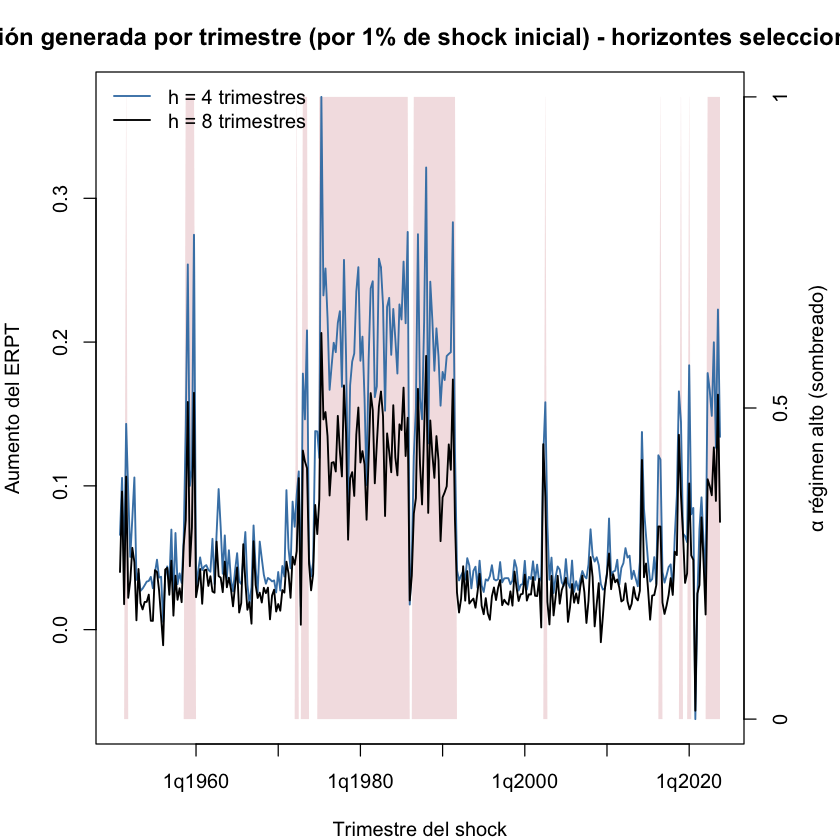

In [68]:
inc_impp_usa_tvar_p2 <- erpt_incremental(out_impp_usa_tvar_p2)
graficar_erpt(inc_impp_usa_tvar_p2, archivo = "erpt_impp_usa_tvar_p2_incremental_sincap",
              titulo = "Inflación generada por trimestre (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")

Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 207 | régimen 2 = 86 


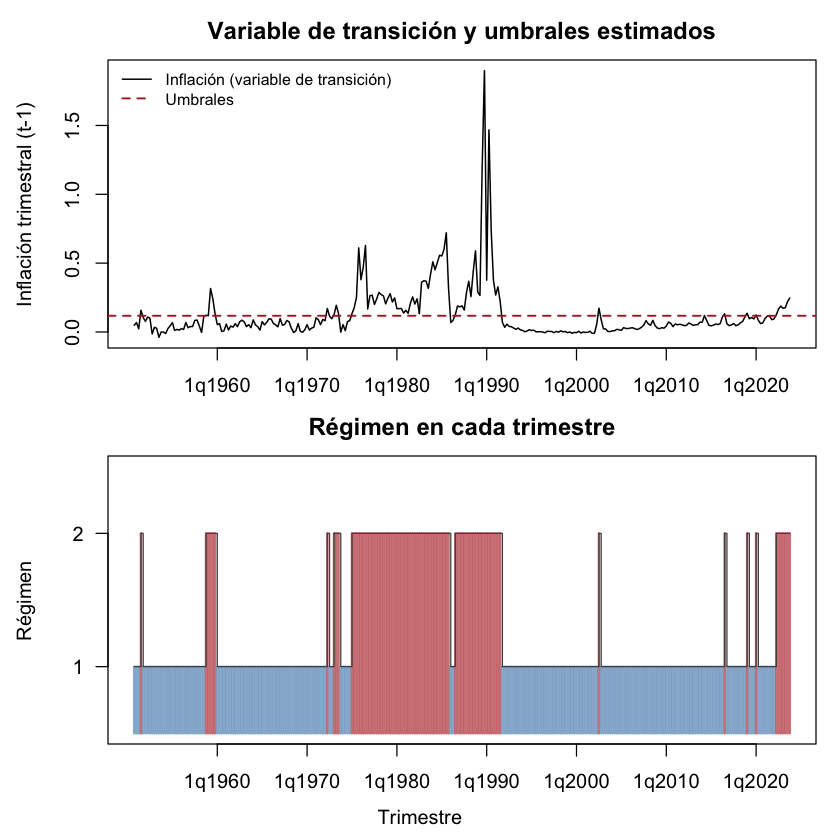

In [69]:
graficar_transicion(res, data = df_ERPT_Arg,
                    endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_p2_sincap")

## TVAR p = 3 (robustez)

Se cargó exitosamente modelos preguardados  threshold_tvar_3_2_500_d2defb6df84d4112af7e9b5364146217.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


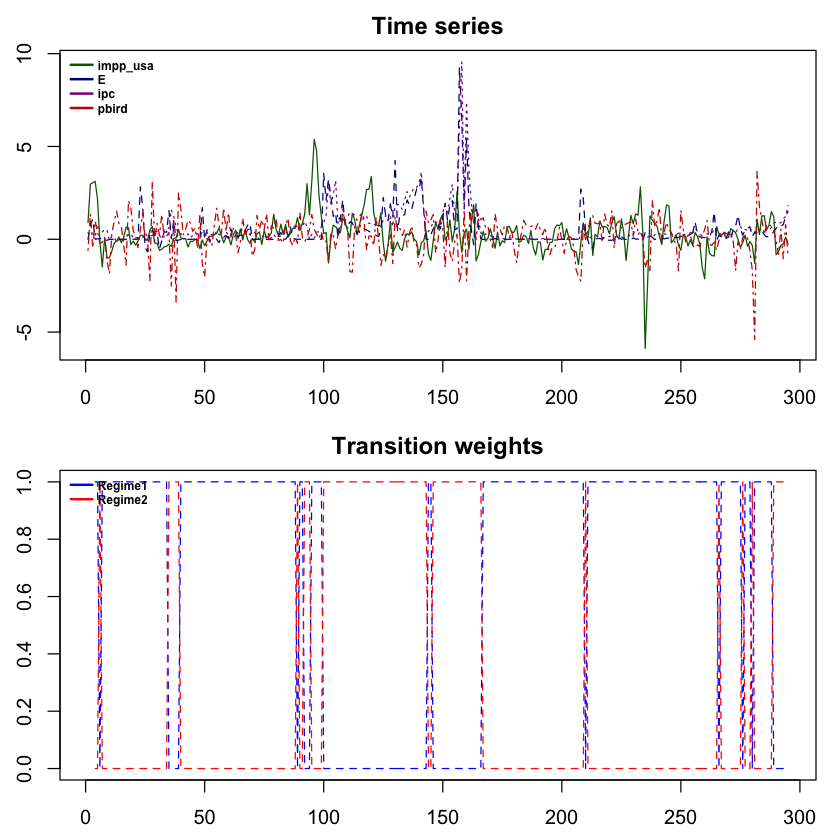

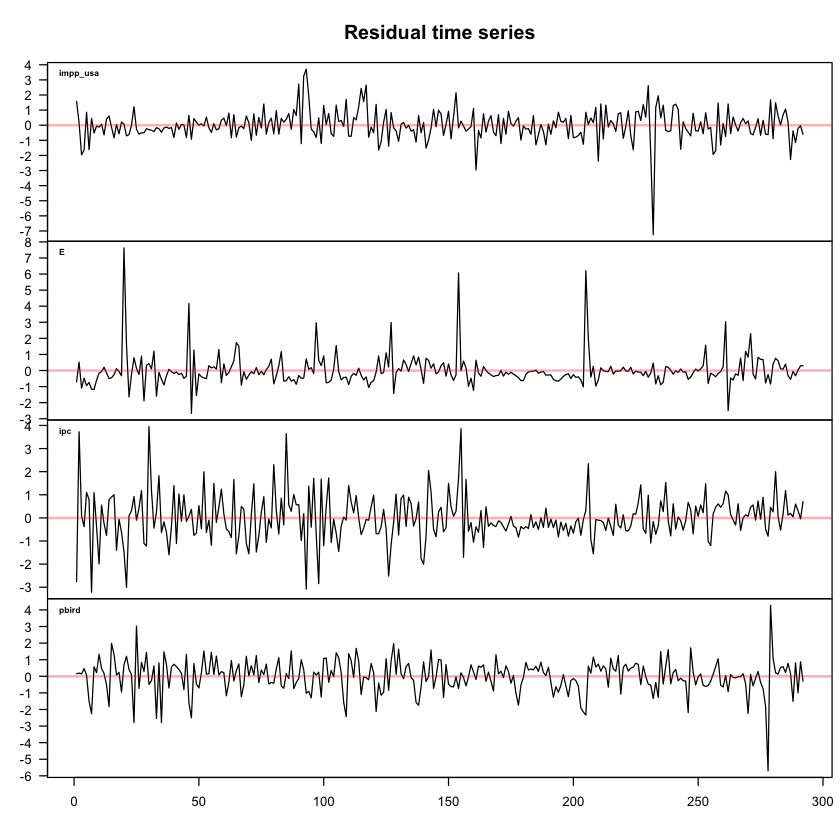

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



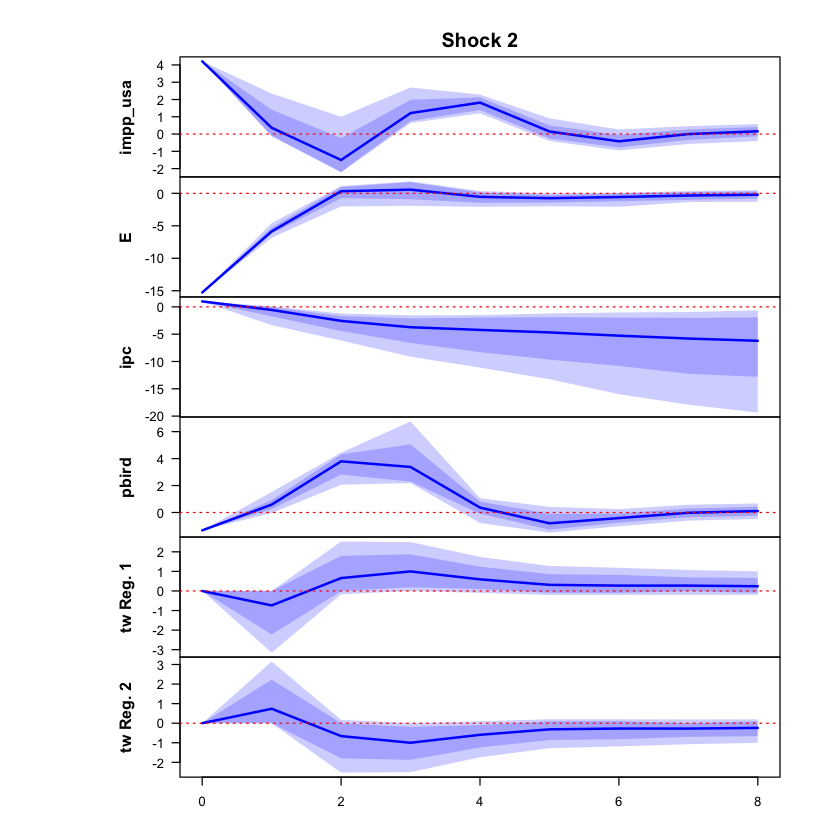

 >>> Linear IRF ( 1  shock units)


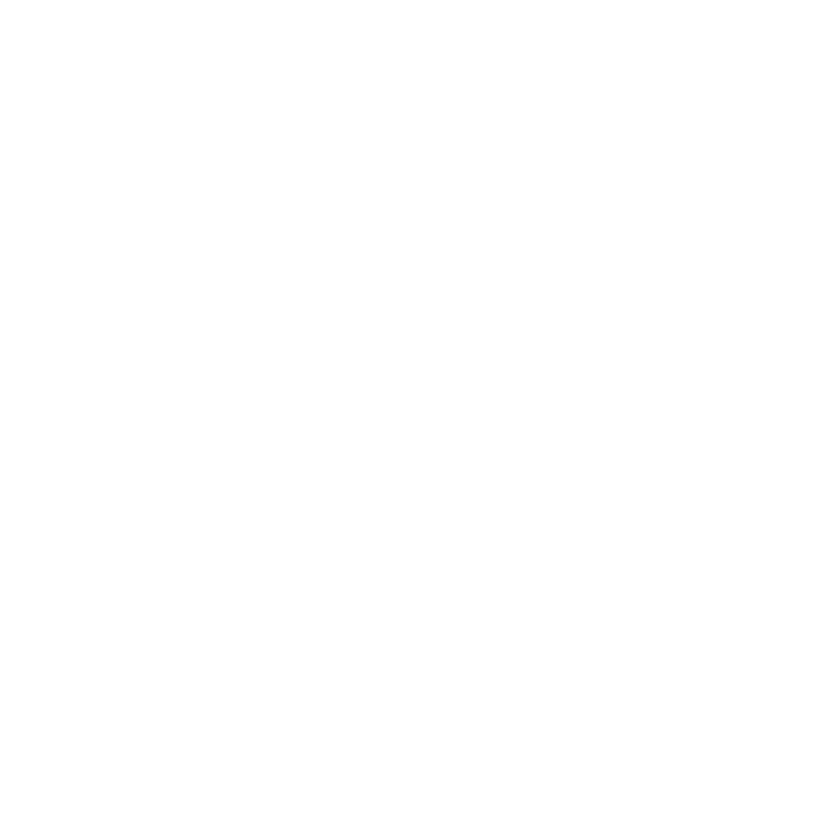

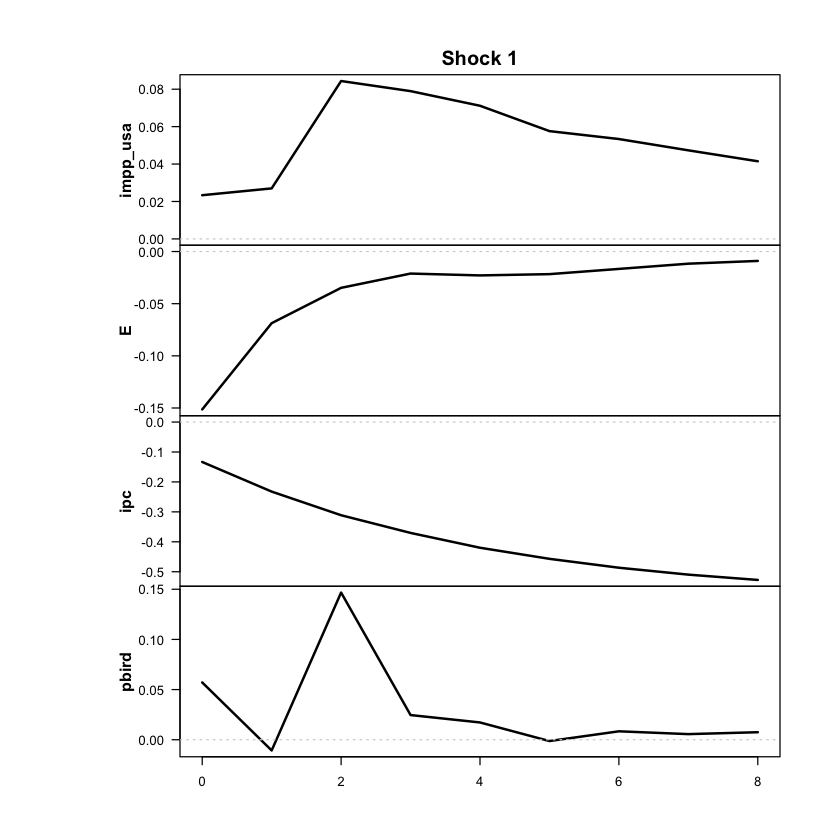

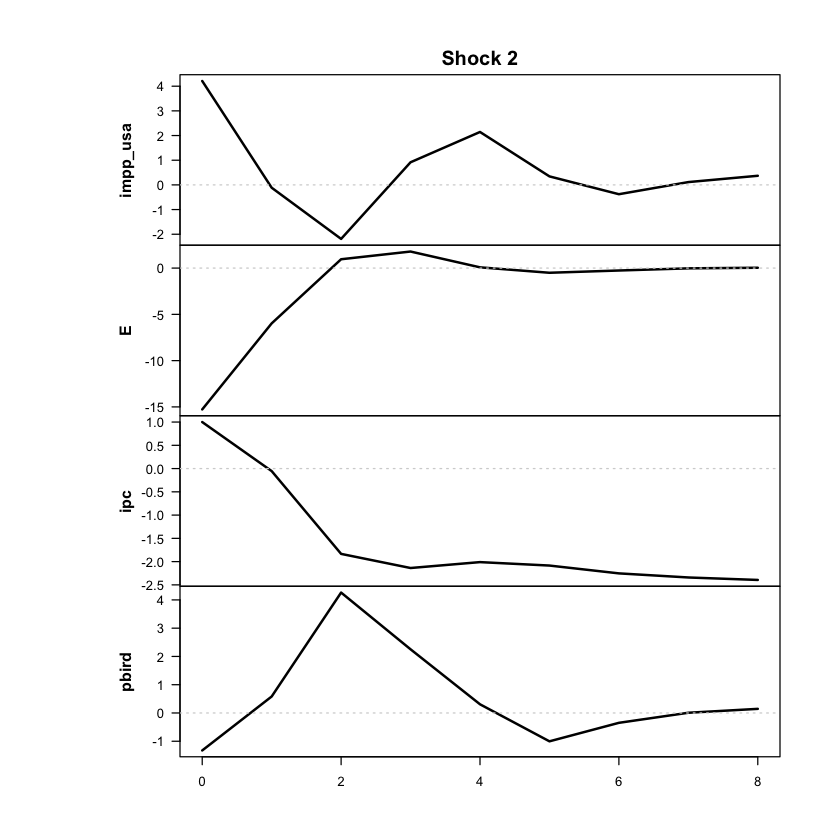

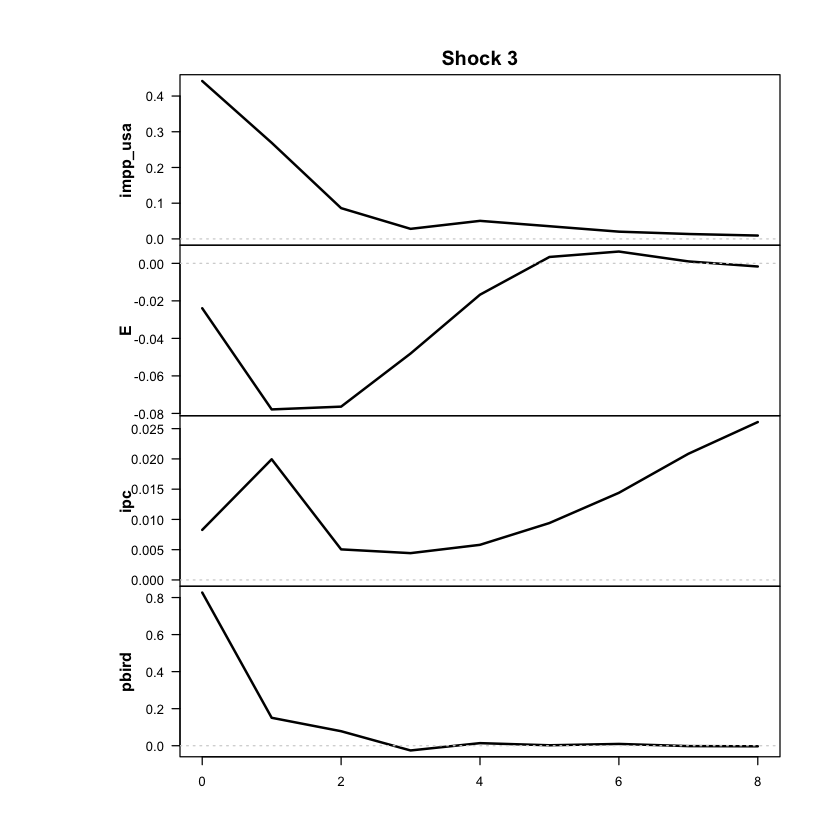

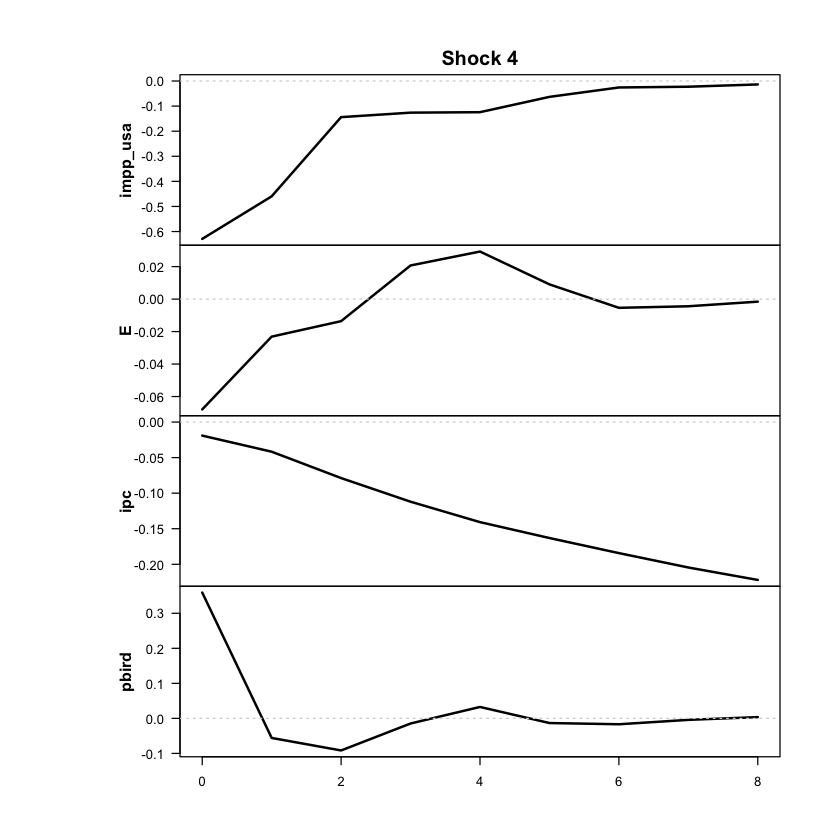

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



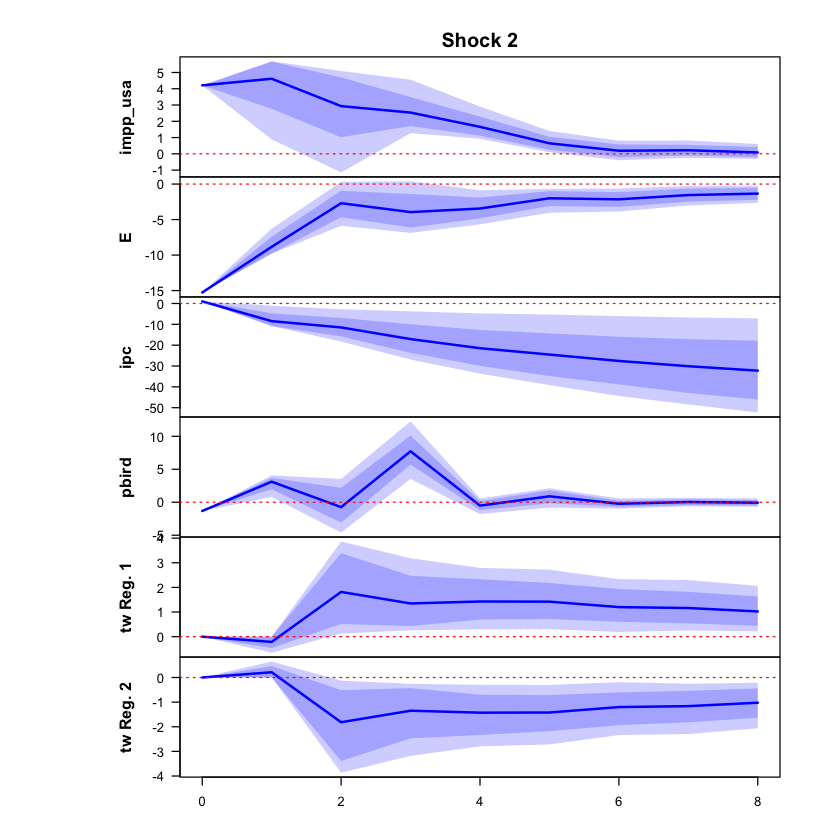

 >>> Linear IRF ( 1  shock units)


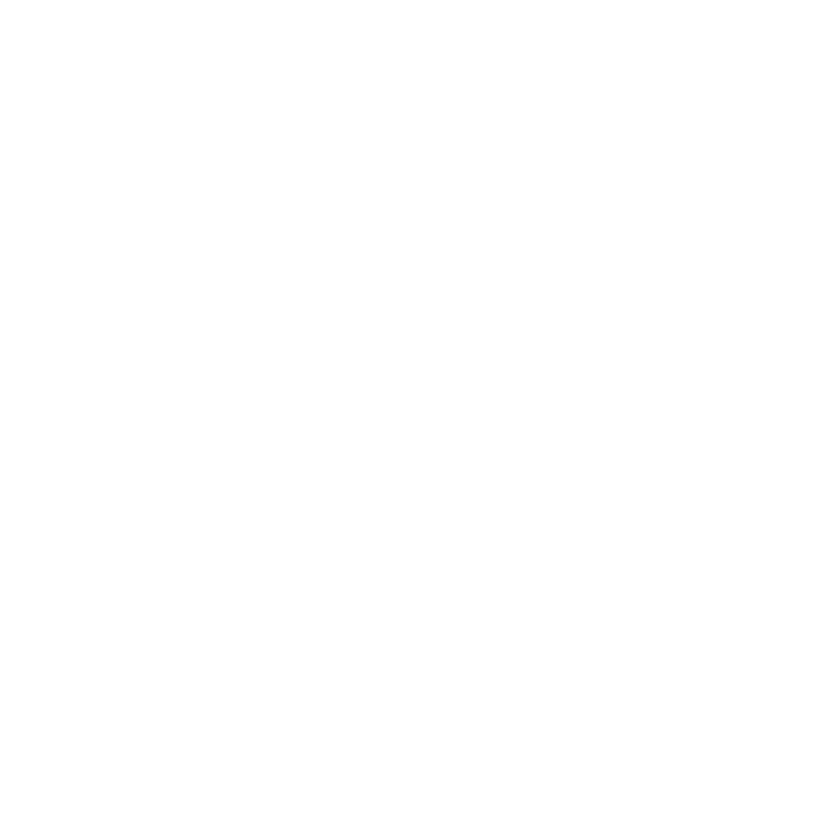

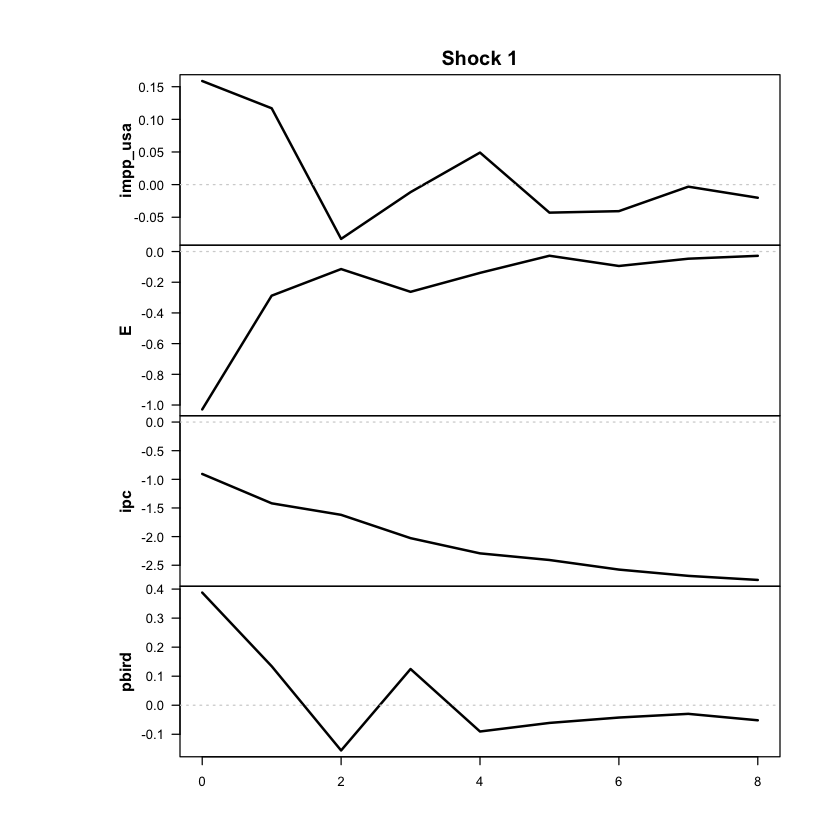

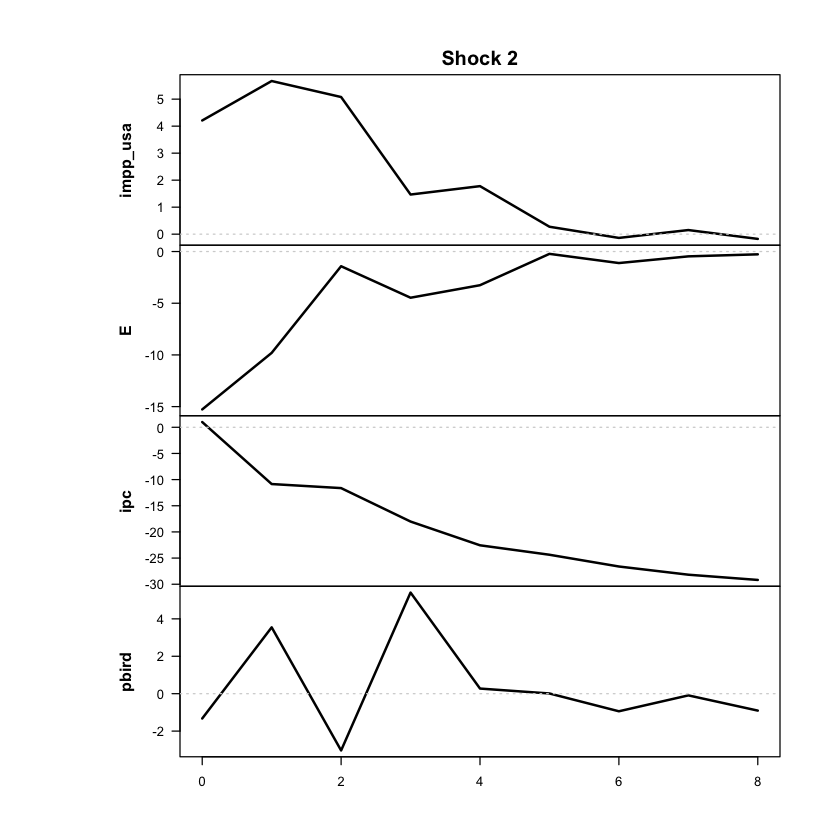

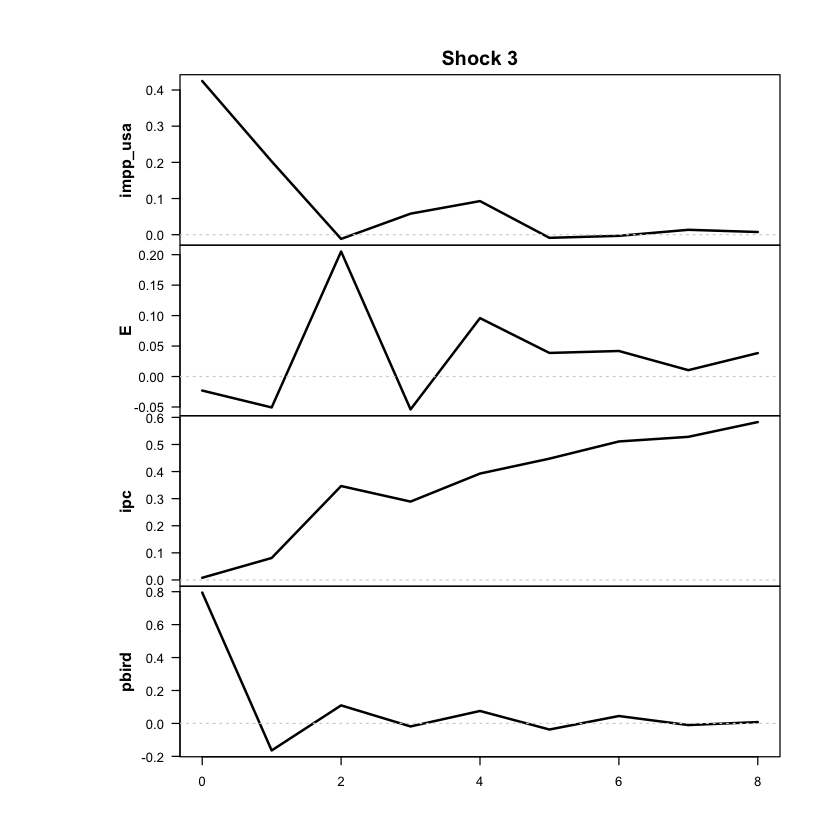

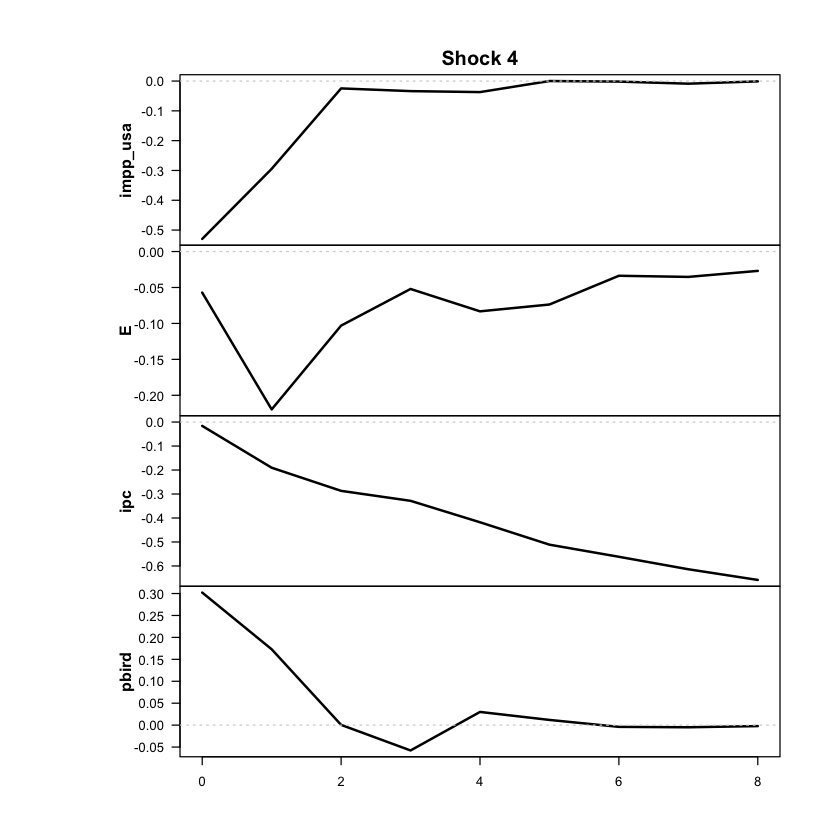

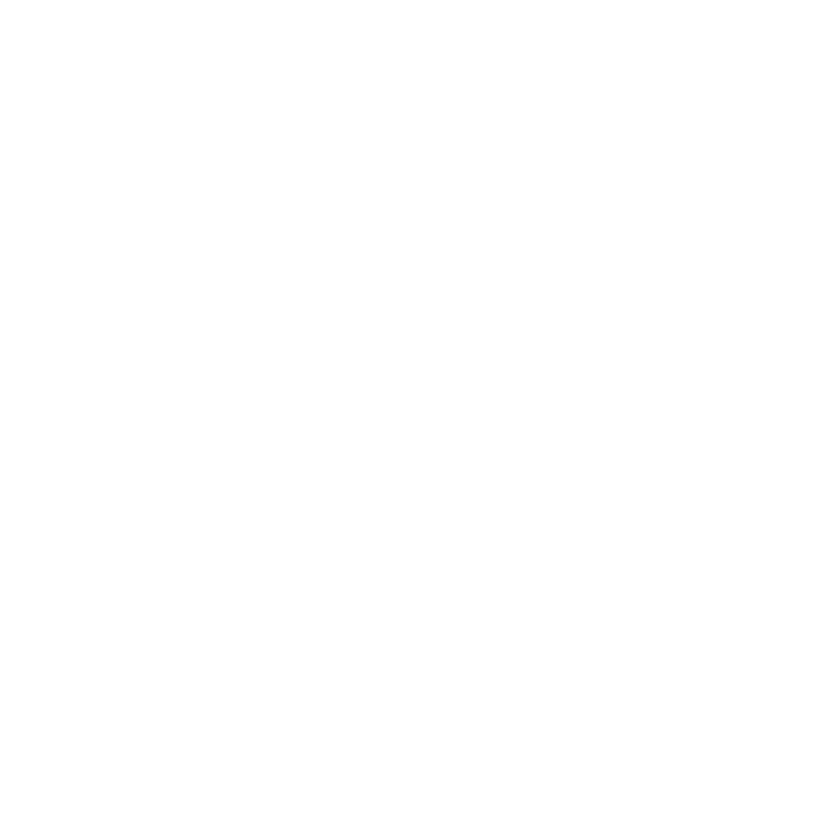

In [7]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 3,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [81]:
ic_tvar_p3 <- criterios_info(res, "TVAR p=3")
print(ic_tvar_p3)

    modelo regimenes parametros  loglik    AIC     HQ  BIC
1 TVAR p=3         2        125 -861.69 1973.4 2157.5 2433


In [82]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 3 
Umbrales: 12.5% trimestral (60% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 206 | régimen 2 = 86 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.55      1.15
E             3.69     35.18
ipc           4.71     37.22
pbird         0.83     -0.12


In [83]:
identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Debe sugerir el shock 2 (= posición de E). Si sugiere otro, avisar antes de seguir.

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0006 -0.0024  0.0122 -0.0174
  E        -0.0362  0.0762 -0.0057 -0.0163
  ipc      -0.0265 -0.0041  0.0016 -0.0038
  pbird     0.0016  0.0008  0.0229  0.0100

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.72    0.96    0.03    0.09 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.731  -0.054  -0.287   0.233 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


In [84]:
print_passthrough(res, endog = c("impp_usa","E","ipc","pbird"))

+++++++++ RÉGIMEN  1 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0543
1         1       0.0317
2         2       0.1442
3         3       0.2108
4         4       0.2420
5         5       0.2704
6         6       0.3050
7         7       0.3336
8         8       0.3574

>>> IRF lineal normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
1         0      -0.0543
2         1       0.0029
3         2       0.0996
4         3       0.1162
5         4       0.1093
6         5       0.1133
7         6       0.1224
8         7       0.1272
9         8       0.1301

+++++++++ RÉGIMEN  2 +++++++++

>>> GIRF normalizada ( ipc / shock inicial de E ) - unidades originales
  horizonte pass_through
0         0      -0.0543
1         1       0.4644
2         2       0.6366
3         3       0.9451
4         4       1.1865
5         5       1.3568
6         6       1.5272
7         7 

### ERPT y gráficos — TVAR p = 3

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0543  0.0101
         1  0.0294  0.0056
         2  0.1411 -0.0243
         3  0.2051 -0.0493
         4  0.2364 -0.0527
         5  0.2636 -0.0467
         6  0.2987 -0.0438
         7  0.3318 -0.0439
         8  0.3571 -0.0450

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0543  0.0101
         1  0.4467 -0.0129
         2  0.6170 -0.0075
         3  0.9162 -0.0657
         4  1.1519 -0.0618
         5  1.3180 -0.0688
         6  1.4862 -0.0663
         7  1.6216 -0.0666
         8  1.7410 -0.0660


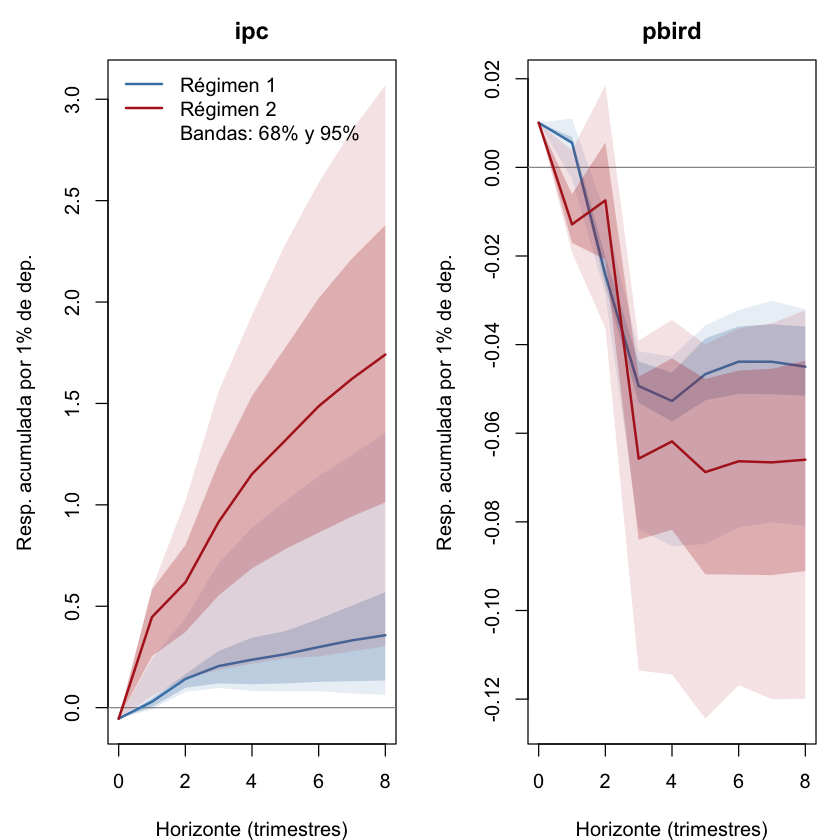


+++ Régimen 1 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0543  0.0101
         1  0.0029  0.0056
         2  0.0996 -0.0267
         3  0.1162 -0.0438
         4  0.1093 -0.0461
         5  0.1133 -0.0385
         6  0.1224 -0.0359
         7  0.1272 -0.0359
         8  0.1301 -0.0370

+++ Régimen 2 - IRF lineal acumulada por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0543  0.0101
         1  0.5895 -0.0169
         2  0.6317  0.0062
         3  0.9791 -0.0348
         4  1.2258 -0.0369
         5  1.3239 -0.0370
         6  1.4460 -0.0299
         7  1.5312 -0.0292
         8  1.5857 -0.0223


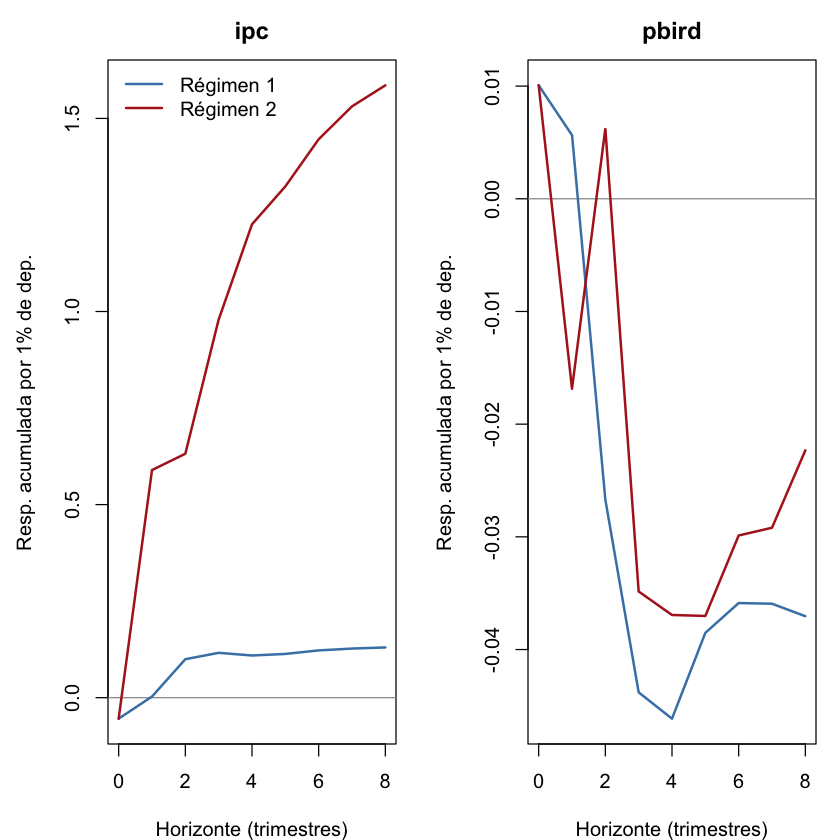

In [85]:
girf_impp_usa_tvar_p3 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                                        archivo = "girf_original_impp_usa_tvar_p3_sincap")
irf_impp_usa_tvar_p3  <- graficar_irf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                                       archivo = "irf_original_impp_usa_tvar_p3_sincap")

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   pbird
         0 1.0000 -0.0543  0.0101
         1 1.3888  0.0294  0.0056
         2 1.3661  0.1411 -0.0243
         3 1.3283  0.2051 -0.0493
         4 1.3682  0.2364 -0.0527
         5 1.4186  0.2636 -0.0467
         6 1.4583  0.2987 -0.0438
         7 1.4852  0.3318 -0.0439
         8 1.5025  0.3571 -0.0450

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte      E     ipc   pbird
         0 1.0000 -0.0543  0.0101
         1 1.5739  0.4467 -0.0129
         2 1.7492  0.6170 -0.0075
         3 1.9998  0.9162 -0.0657
         4 2.2219  1.1519 -0.0618
         5 2.3558  1.3180 -0.0688
         6 2.4987  1.4862 -0.0663
         7 2.5988  1.6216 -0.0666
         8 2.6904  1.7410 -0.0660


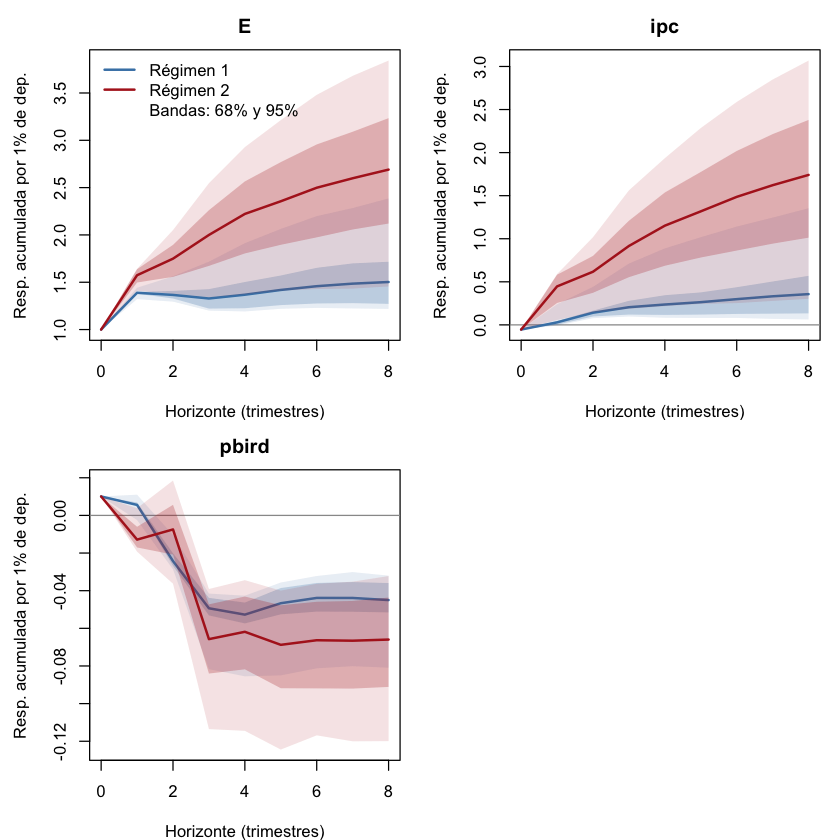

In [86]:
graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                       variables = c("E", "ipc", "pbird"),
                       archivo = "girf_original_impp_usa_tvar_p3_con_E_sincap")

In [8]:
out_impp_usa_tvar_p3 <- erpt_historia(res, data = df_ERPT_Arg,
                             endog = c("impp_usa", "E", "ipc", "pbird"))


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 7.9%.

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...



Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0543           -0.0543
2         1            0.0209            0.4495
3         2            0.1289            0.6017
4         3            0.1821            0.8891
5         4            0.2111            1.1240
6         5            0.2367            1.2898
7         6            0.2764            1.4623
8         7            0.3110            1.5978
9         8            0.3370            1.7221

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0543          -0.0543
2         1           0.0042           0.4613
3         2           0.1065           0.5936
4         3           0.1441           0.8580
5         4        

HTML widgets cannot be represented in plain text (need html)

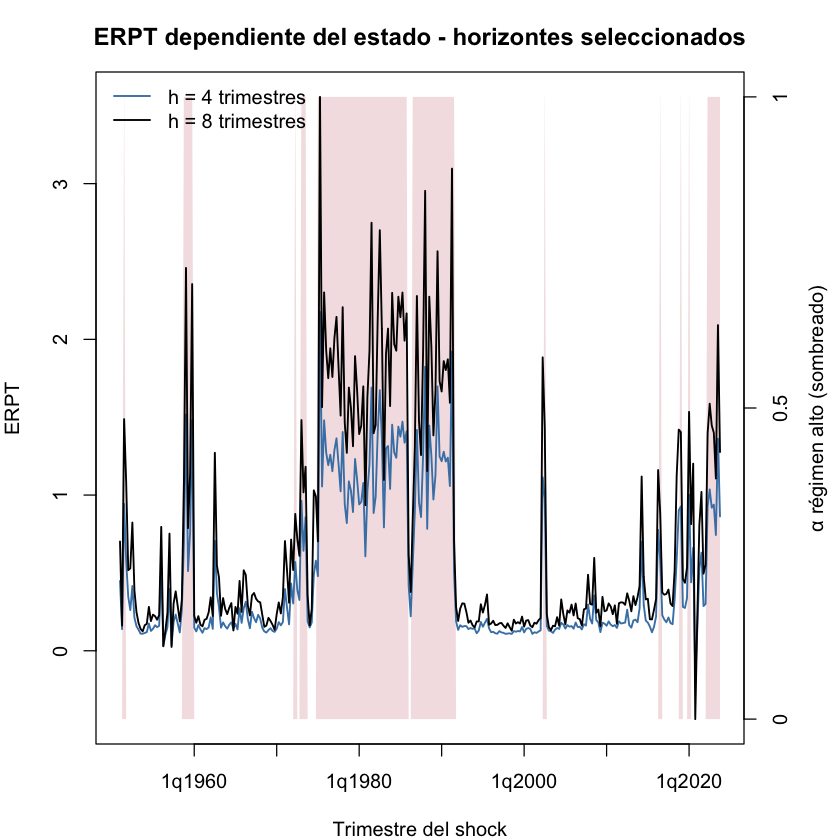

In [88]:
graficar_erpt(out_impp_usa_tvar_p3, archivo = "erpt_impp_usa_tvar_p3_sincap")

In [112]:
exists("out_impp_usa_tvar_p3_acum")

[1] TRUE

HTML widgets cannot be represented in plain text (need html)

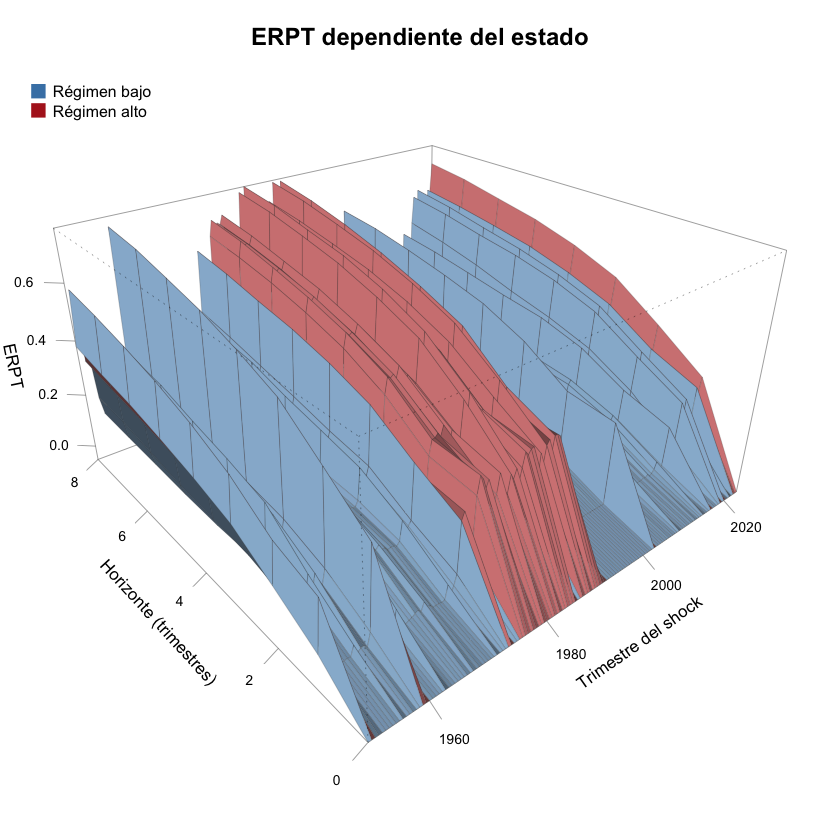

In [113]:
graficar_erpt_manta(out_impp_usa_tvar_p3_acum, cada = 2,
                    archivo = "erpt_manta_impp_usa_tvar_p3_acum_c2_sincap")

In [89]:
graficar_slider(out_impp_usa_tvar_p3, archivo = "slider_impp_usa_tvar_p3_sincap")

HTML widgets cannot be represented in plain text (need html)

 horizonte  1q1975  3q1975  3q1989  4q2005
         0 -0.0543 -0.0543 -0.0543 -0.0543
         1  0.1598  0.4614  0.5895  0.0034
         2  0.2600  0.5332  0.8484  0.1120
         3  0.3961  0.8066  1.3513  0.1437
         4  0.4793  1.0550  1.6979  0.1588
         5  0.5308  1.1952  1.9548  0.1856
         6  0.6006  1.3408  2.2077  0.2306
         7  0.6531  1.4575  2.4057  0.2710
         8  0.7026  1.5647  2.5655  0.2964


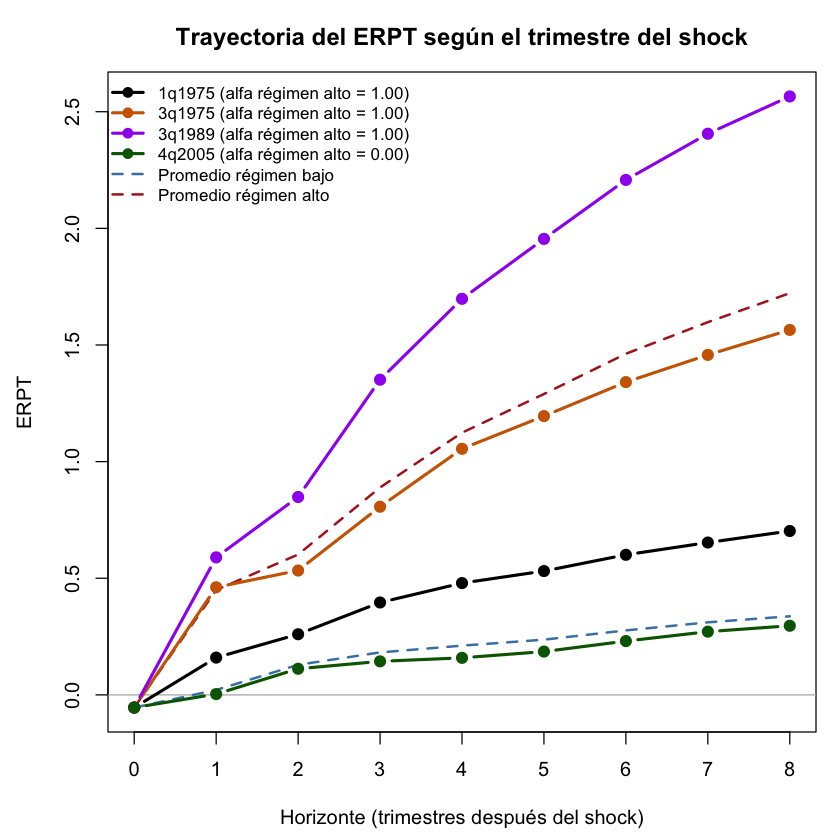

In [90]:
graficar_trayectorias(out_impp_usa_tvar_p3,
                      trimestres = c("1q1975", "3q1975", "3q1989", "4q2005"),
                      archivo = "trayectorias_impp_usa_tvar_p3_sincap")


In [91]:
guardar_gif(out_impp_usa_tvar_p3, archivo = "gif_impp_usa_tvar_p3_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_impp_usa_tvar_p3_sincap.gif



In [9]:
out_impp_usa_tvar_p3_acum <- erpt_historia(res, data = df_ERPT_Arg,
                                  endog = c("impp_usa", "E", "ipc", "pbird"),
                                  definicion = "acumulado")


Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 7.9%.

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 86 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_bajo_original reg_alto_original
1         0           -0.0543           -0.0543
2         1            0.0151            0.2834
3         2            0.0936            0.3426
4         3            0.1337            0.4421
5         4            0.1479            0.5009
6         5            0.1574            0.5423
7         6            0.1768            0.5753
8         7            0.1942            0.6040
9         8            0.2060            0.6252

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_bajo_mediana reg_alto_mediana
1         0          -0.0543          -0.0543
2         1           0.0030           0.2936
3         2           0.0790           0.3424
4         3           0.1130           0.4379
5         4        

In [10]:
saveRDS(out_impp_usa_tvar_p2,      "out_impp_usa_tvar_p3.rds")
saveRDS(out_impp_usa_tvar_p2_acum, "out_impp_usa_tvar_p3_acum.rds")

HTML widgets cannot be represented in plain text (need html)

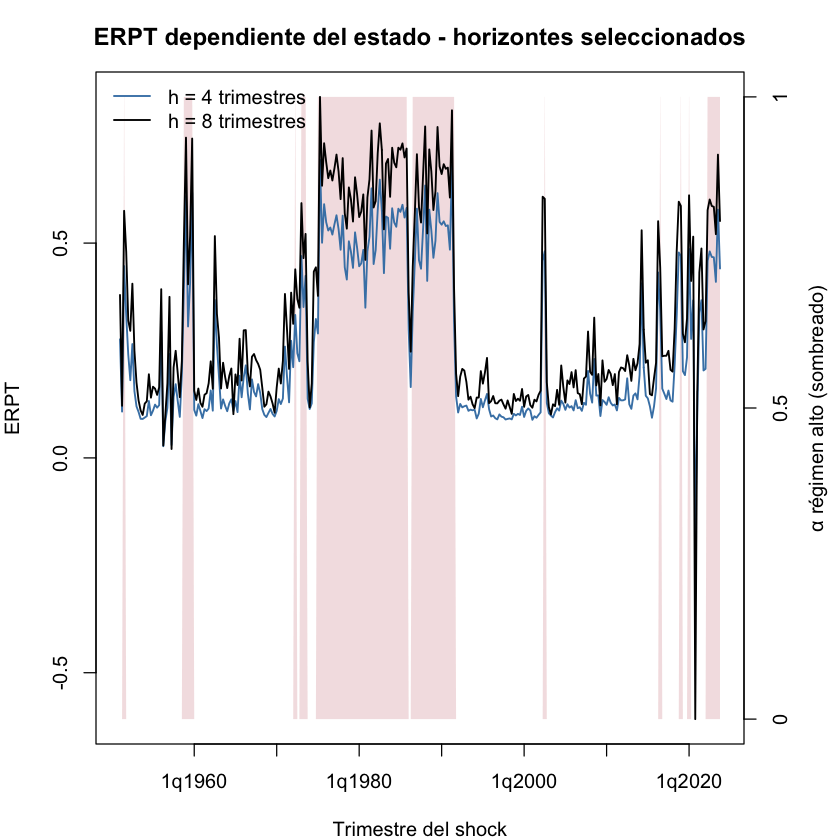

In [93]:
graficar_erpt(out_impp_usa_tvar_p3_acum, archivo = "erpt_impp_usa_tvar_p3_acum_sincap")

In [94]:
graficar_slider(out_impp_usa_tvar_p3_acum, archivo = "slider_impp_usa_tvar_p3_acum_sincap")

HTML widgets cannot be represented in plain text (need html)

 horizonte  1q1975  2q1975  3q1975  3q1989
         0 -0.0543 -0.0543 -0.0543 -0.0543
         1  0.1106  0.3590  0.2945  0.3590
         2  0.1747  0.5170  0.3198  0.4295
         3  0.2533  0.6294  0.4284  0.5531
         4  0.2896  0.6936  0.5008  0.6162
         5  0.3106  0.7509  0.5480  0.6685
         6  0.3365  0.7881  0.5850  0.7109
         7  0.3589  0.8202  0.6130  0.7451
         8  0.3772  0.8403  0.6335  0.7702


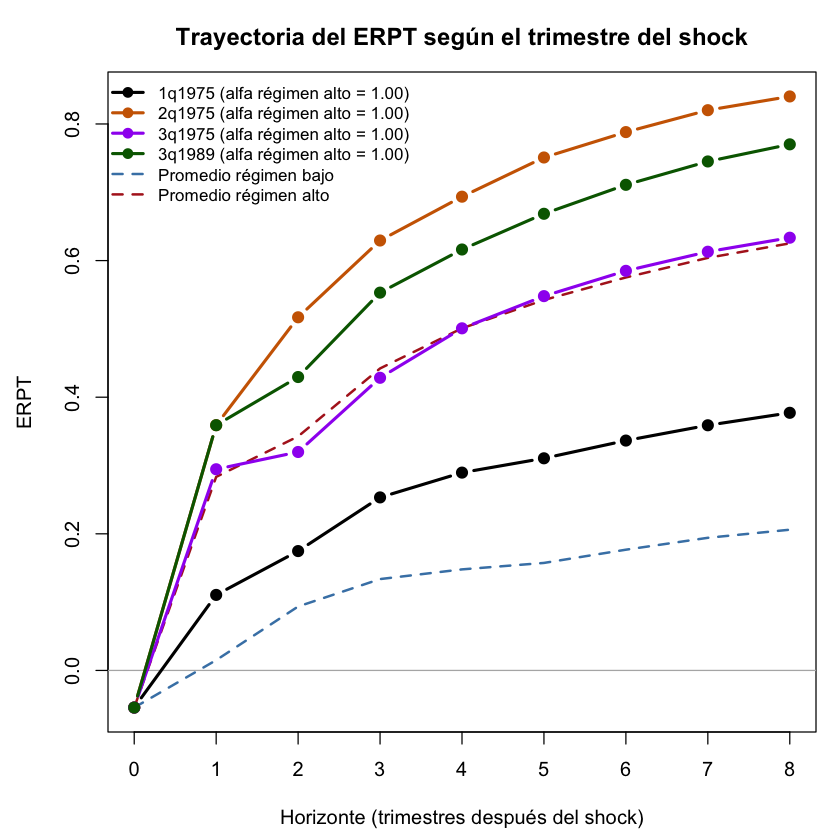

In [97]:
graficar_trayectorias(out_impp_usa_tvar_p3_acum,
                      trimestres = c("1q1975", "2q1975", "3q1975", "3q1989"),
                      archivo = "trayectorias_impp_usa_tvar_p3_acum_sincap")


In [98]:
guardar_gif(out_impp_usa_tvar_p3_acum, archivo = "gif_impp_usa_tvar_p3_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_impp_usa_tvar_p3_acum_sincap.gif



  horizonte reg_bajo_original reg_alto_original
1         0           -0.0543           -0.0543
2         1            0.0752            0.5039
3         2            0.1081            0.1522
4         3            0.0531            0.2874
5         4            0.0290            0.2349
6         5            0.0256            0.1658
7         6            0.0397            0.1725
8         7            0.0345            0.1355
9         8            0.0260            0.1243


HTML widgets cannot be represented in plain text (need html)

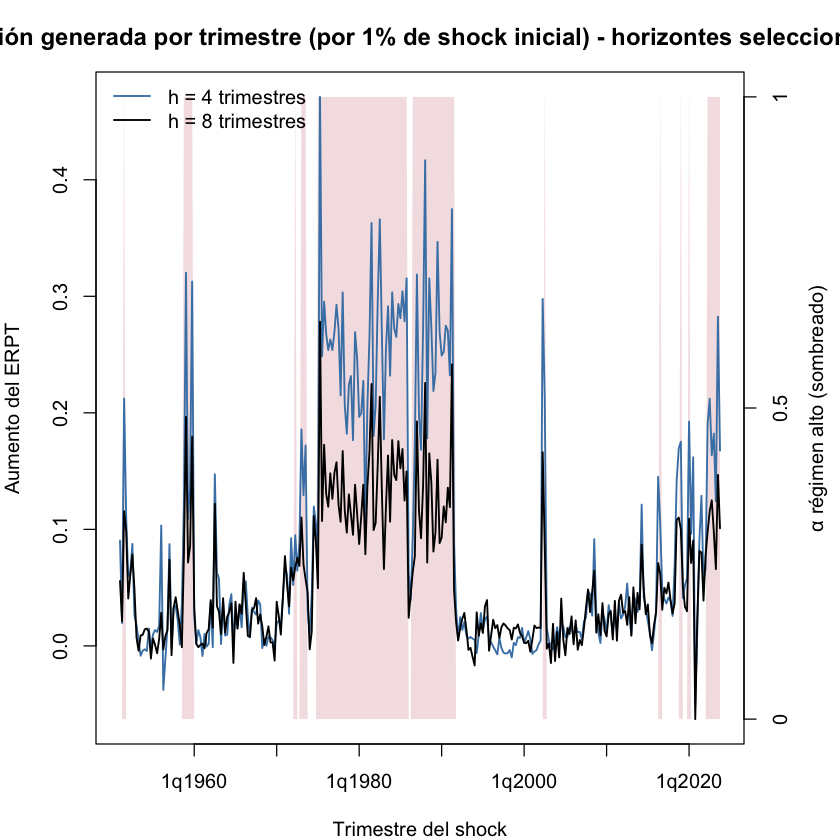

In [99]:
inc_impp_usa_tvar_p3 <- erpt_incremental(out_impp_usa_tvar_p3)
graficar_erpt(inc_impp_usa_tvar_p3, archivo = "erpt_impp_usa_tvar_p3_incremental_sincap",
              titulo = "Inflación generada por trimestre (por 1% de shock inicial)",
              eje_z = "Aumento del ERPT")


  horizonte reg_bajo_original reg_alto_original
1         0           -0.0543           -0.0543
2         1            0.0694            0.3377
3         2            0.0785            0.0593
4         3            0.0402            0.0995
5         4            0.0142            0.0588
6         5            0.0095            0.0414
7         6            0.0194            0.0330
8         7            0.0174            0.0287
9         8            0.0119            0.0213


HTML widgets cannot be represented in plain text (need html)

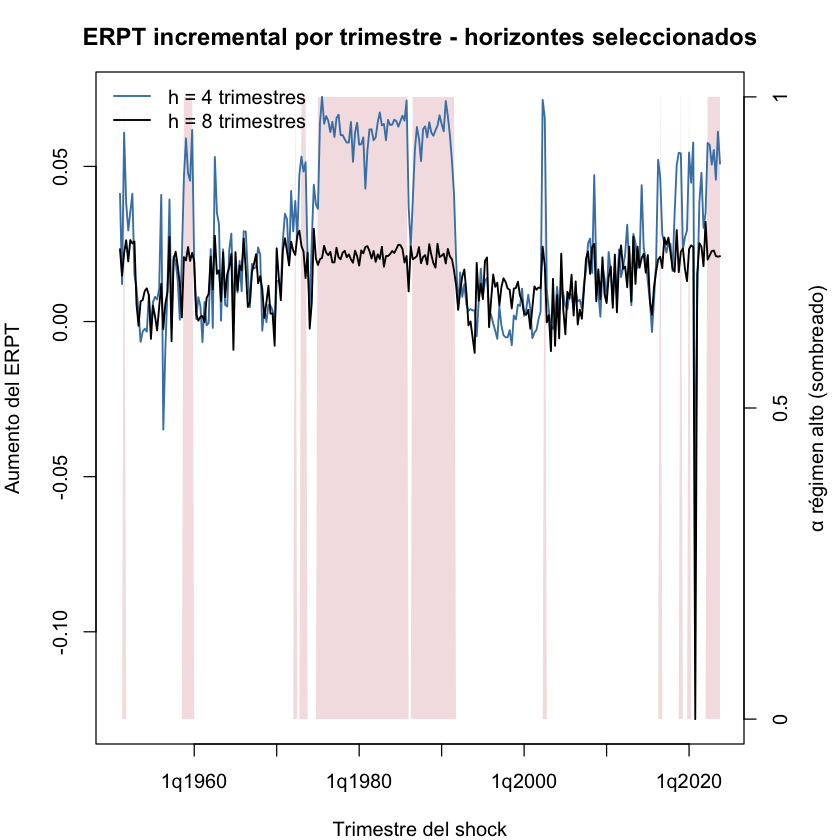

In [100]:
inc_impp_usa_tvar_p3_acum <- erpt_incremental(out_impp_usa_tvar_p3_acum)
graficar_erpt(inc_impp_usa_tvar_p3_acum, archivo = "erpt_impp_usa_tvar_p3_acum_incremental_sincap",
              titulo = "ERPT incremental por trimestre", eje_z = "Aumento del ERPT")

Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) 
Trimestres por régimen: régimen 1 = 206 | régimen 2 = 86 


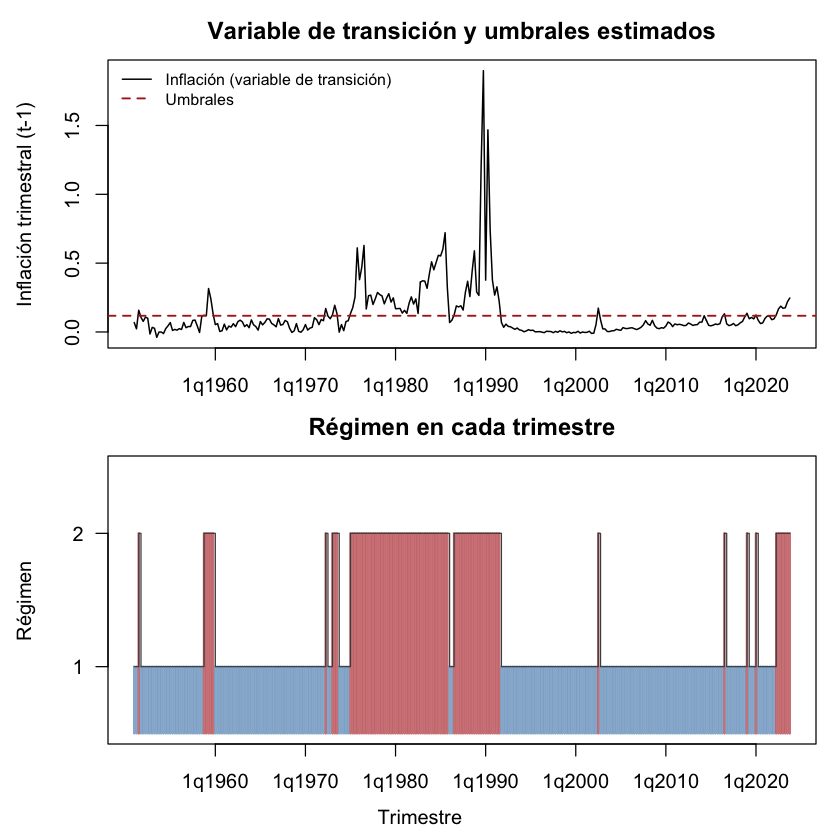

In [101]:
graficar_transicion(res, data = df_ERPT_Arg,
                    endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_p3_sincap")


### Excel con ERPT h=4 y h=8 por trimestre: resultado y gráficos

In [11]:
source("src/erpt_historia_v38.R")
source("src/exportar_erpt_series.R")
modelos_trim <- list(
  "TVAR p2 (principal)" = list(relativo    = cargar_out("out_impp_usa_tvar_p2"),
                               transmision = cargar_out("out_impp_usa_tvar_p2_acum")),
  "TVAR p3 (robustez)"  = list(relativo    = cargar_out("out_impp_usa_tvar_p3"),
                               transmision = cargar_out("out_impp_usa_tvar_p3_acum"))
)
series_trim <- exportar_erpt_series(modelos_trim, horizontes = c(4, 8),
                                    archivo = "ERPT_series_trimestrales.xlsx",
                                    carpeta_graficos = "GRAFICOS_TVAR_VLSTAR_Trimestrales")

>>> erpt_historia v38 cargada (datos trimestrales o anuales; usar_frecuencia("anual") en notebooks anuales)
TVAR p2 (principal)              293 períodos | gráfico: GRAFICOS_TVAR_VLSTAR_Trimestrales/serie_erpt_TVAR_p2_principal_.png
TVAR p3 (robustez)               292 períodos | gráfico: GRAFICOS_TVAR_VLSTAR_Trimestrales/serie_erpt_TVAR_p3_robustez_.png

Listo: ERPT_series_trimestrales.xlsx 


## Comparación de criterios

In [102]:
rbind(ic_tvar_p2, ic_tvar_p3)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=2,2,93,-896.09,1978.2,2115.3,2320.4
TVAR p=3,2,125,-861.69,1973.4,2157.5,2433.0


## Errores t de Student (2 regímenes)

Misma especificación, pero con errores t de Student (`cond_dist = "Student"`): colas más pesadas, que admiten trimestres extremos sin necesitar un régimen aparte. Objetivo: (1) ver si el VLSTAR encuentra una solución válida (sin covarianza casi singular) y (2) verificar que el ERPT del TVAR principal no cambia. Los modelos gaussianos ya guardados no se pisan: los archivos t llevan `student_` en el nombre.

`resumen_modelo` muestra los grados de libertad: valores bajos (≈ 3–6) indican colas muy pesadas; valores muy altos (> 30) indican que los errores son casi normales.

### TVAR con errores t, p = 2

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -1140.26

The largest loglik: -759.322

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -948.249

The largest loglik: -681.358

Filtering inappropriate estimates...

Filtered through 0 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


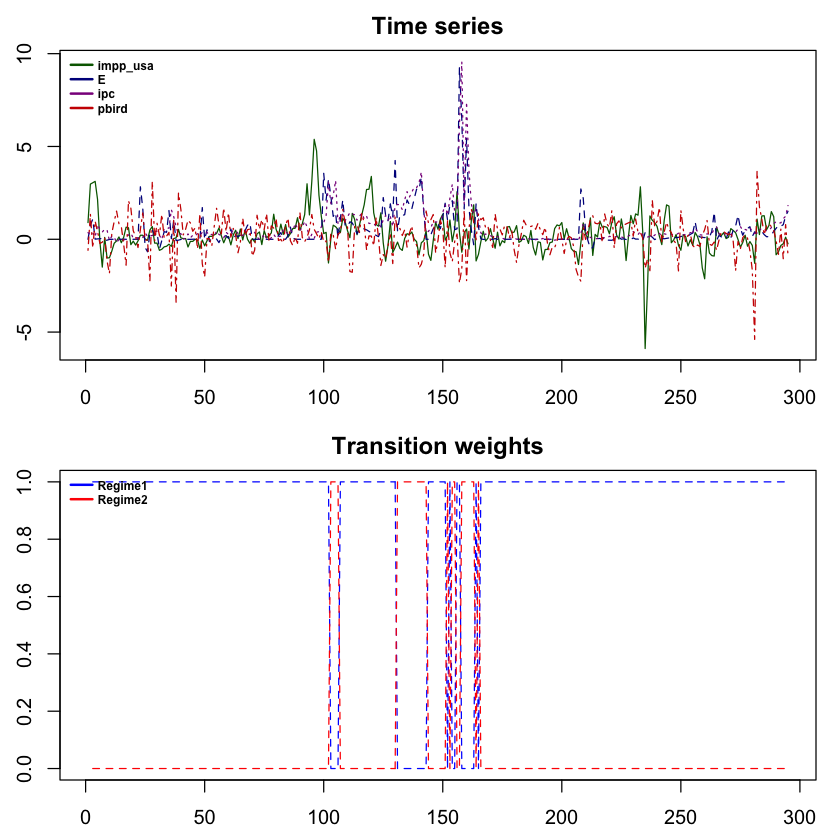

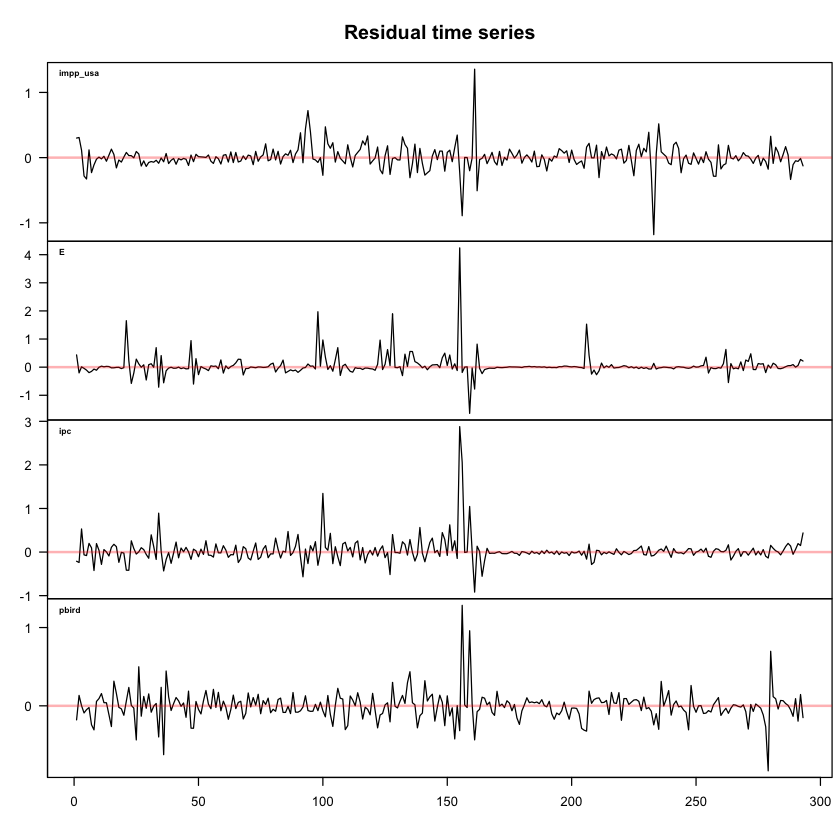

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



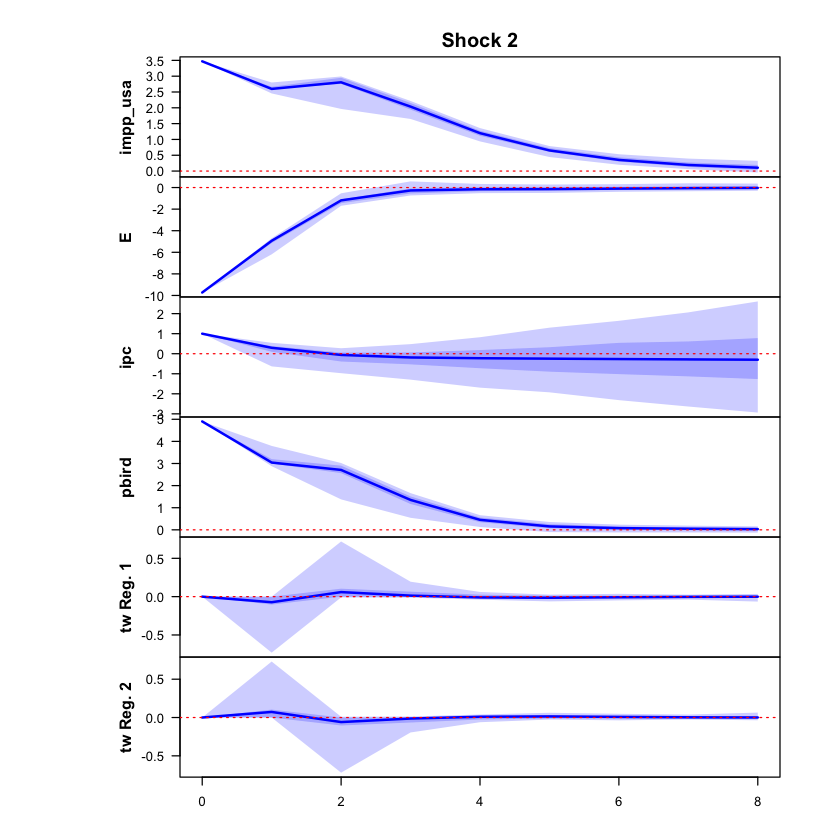

 >>> Linear IRF ( 1  shock units)


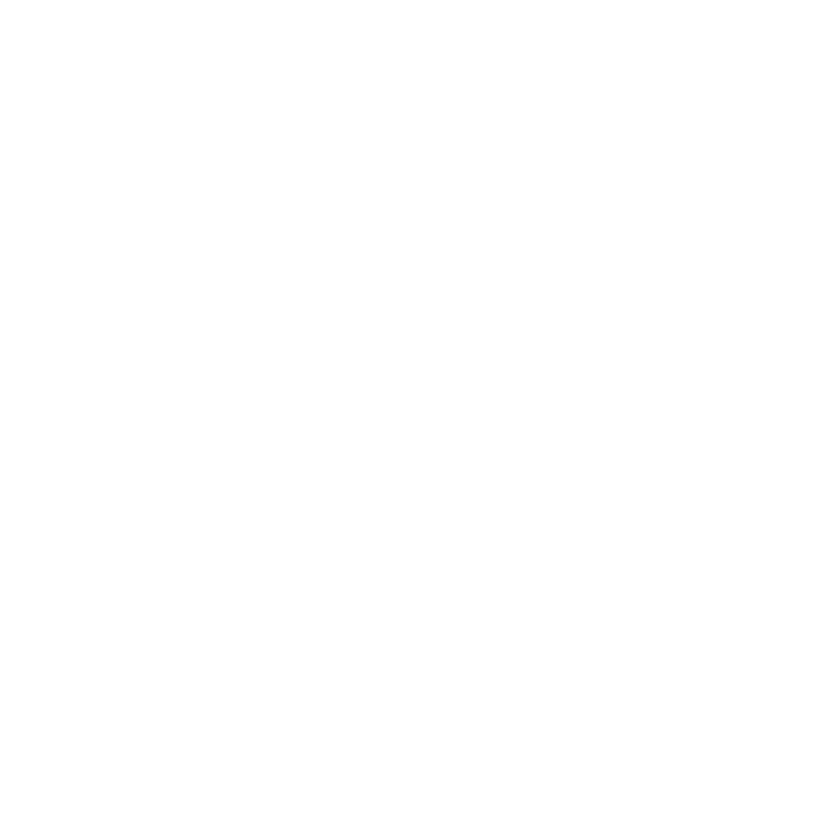

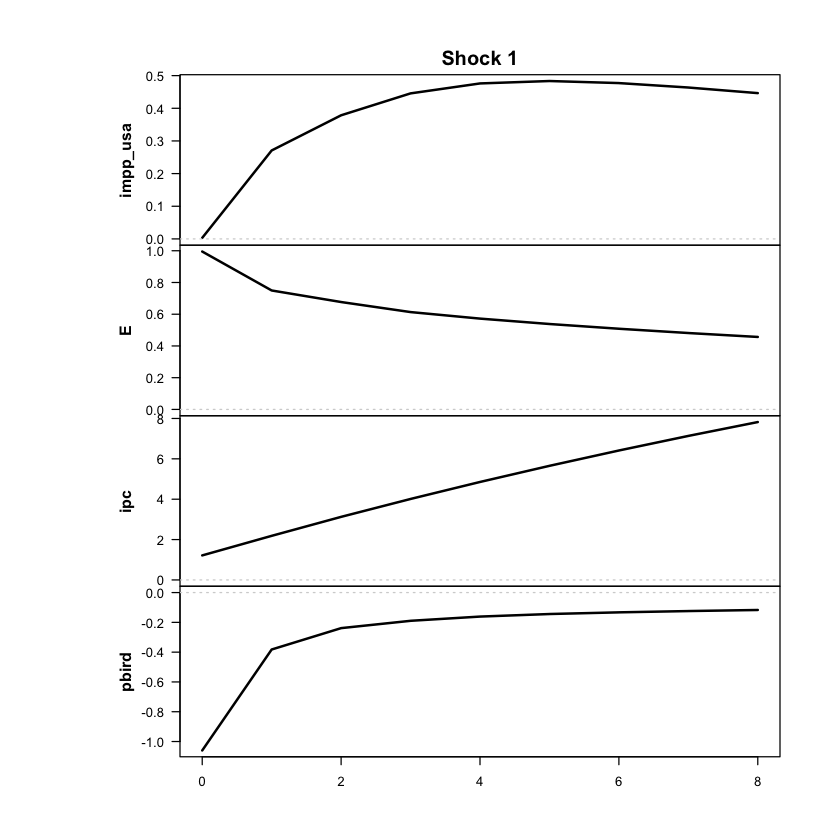

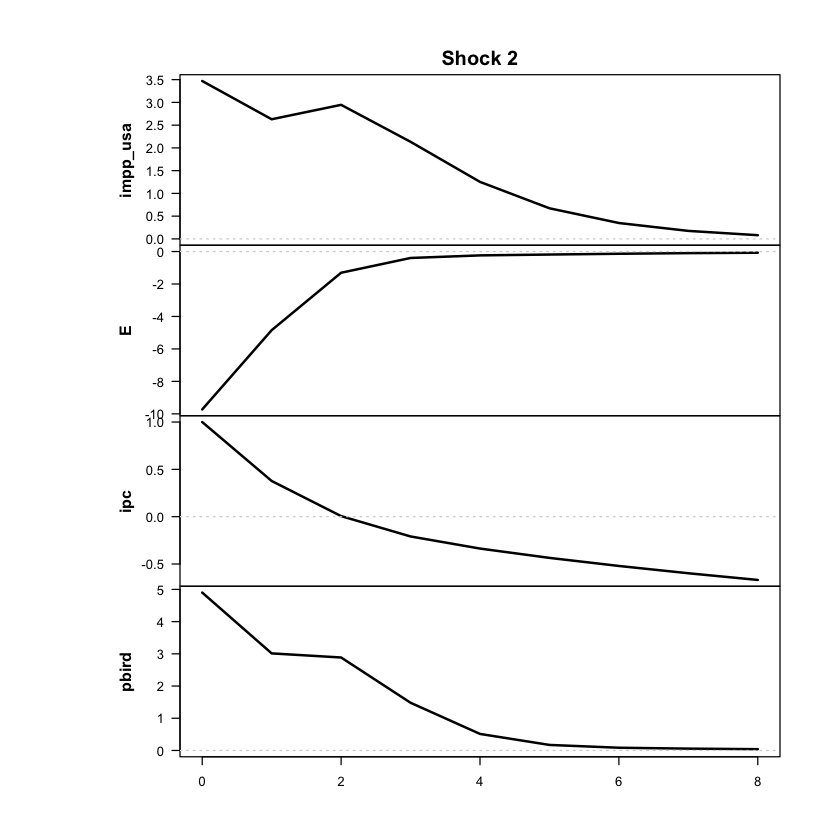

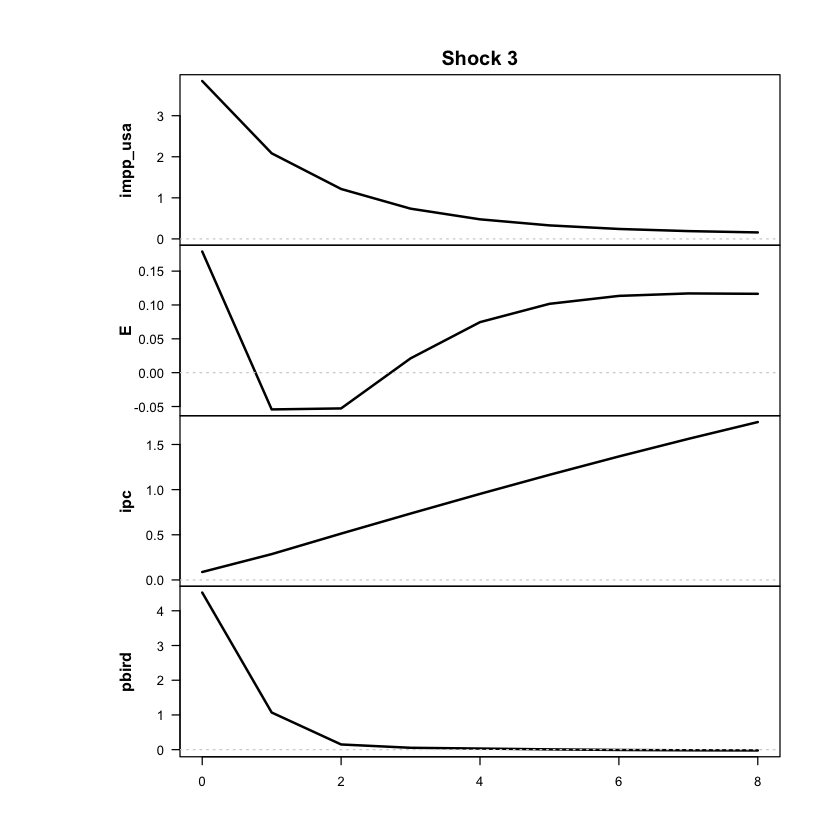

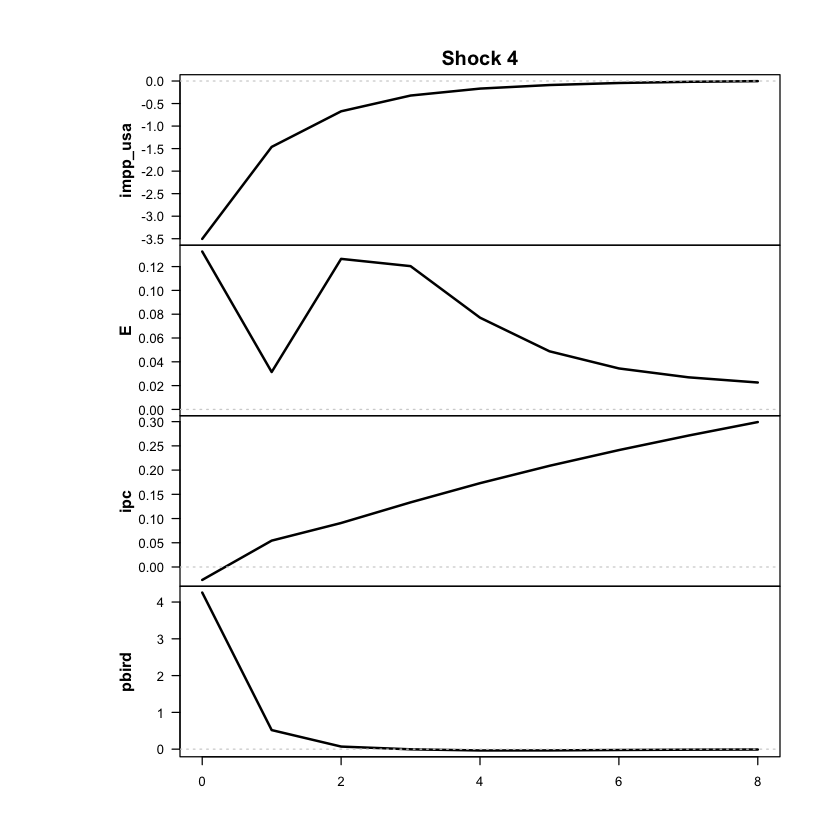

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



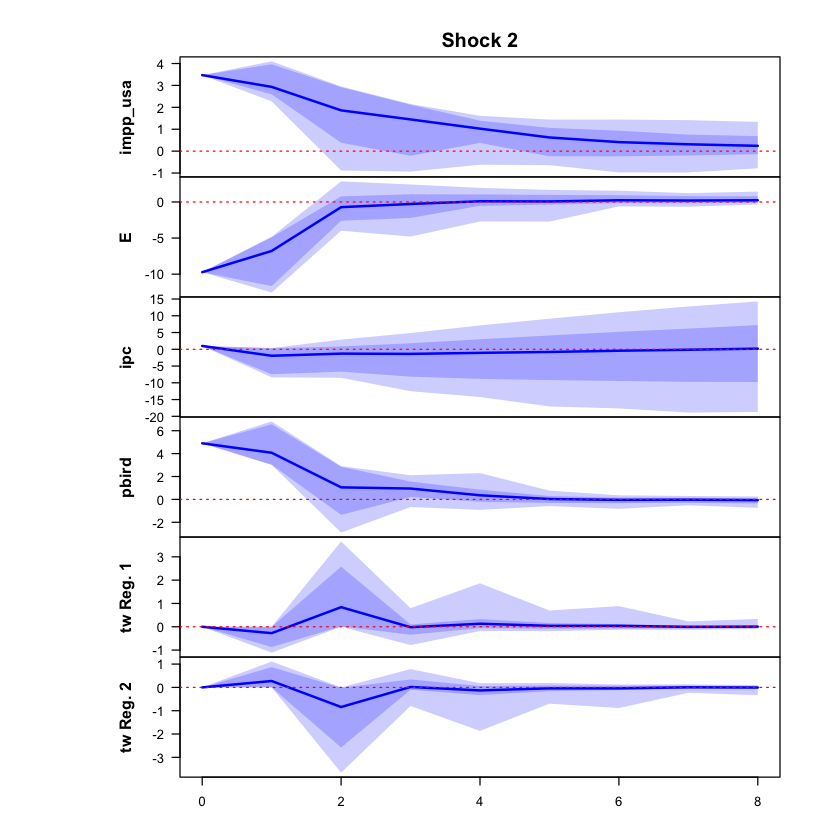

 >>> Linear IRF ( 1  shock units)


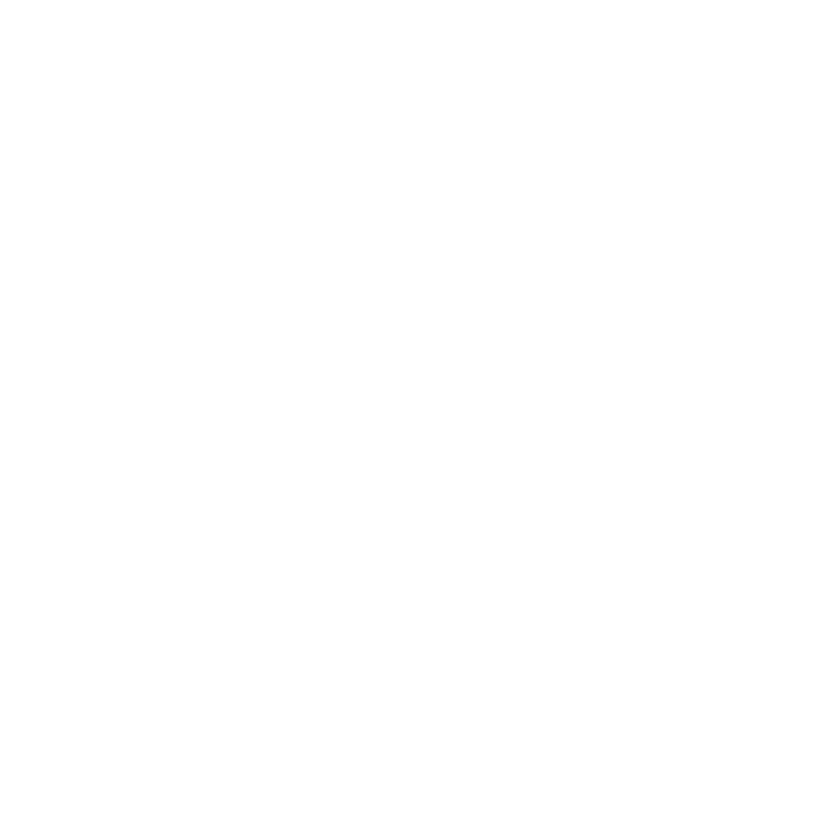

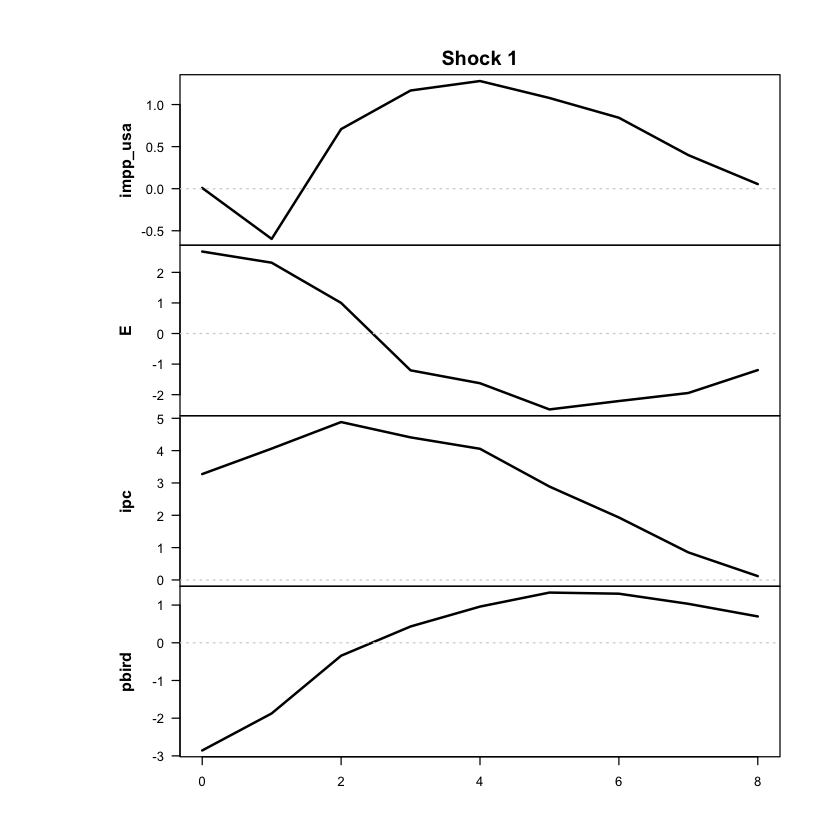

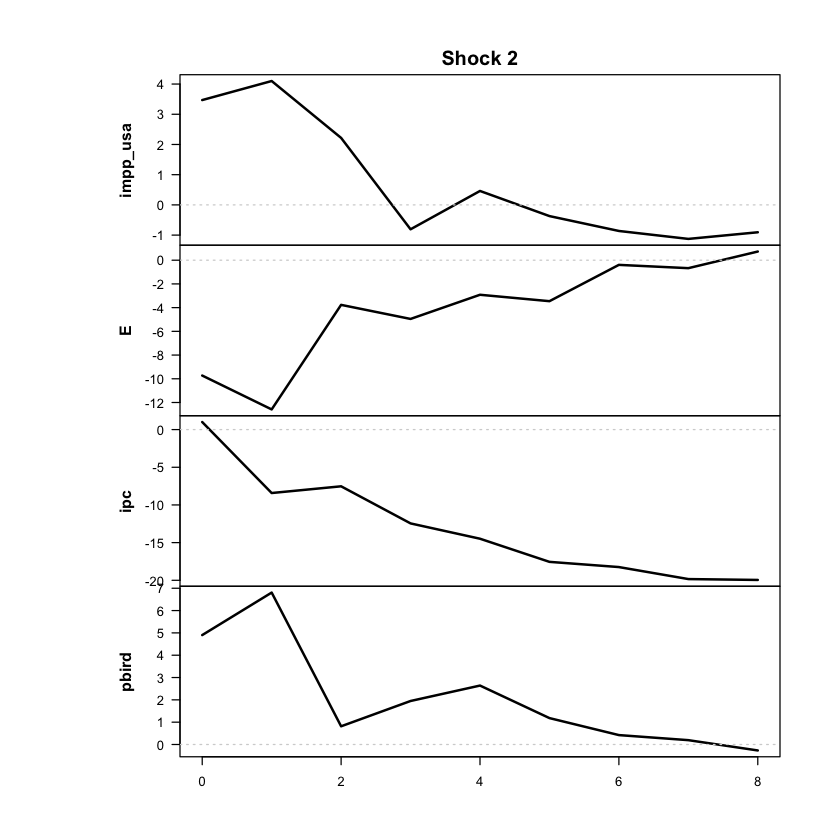

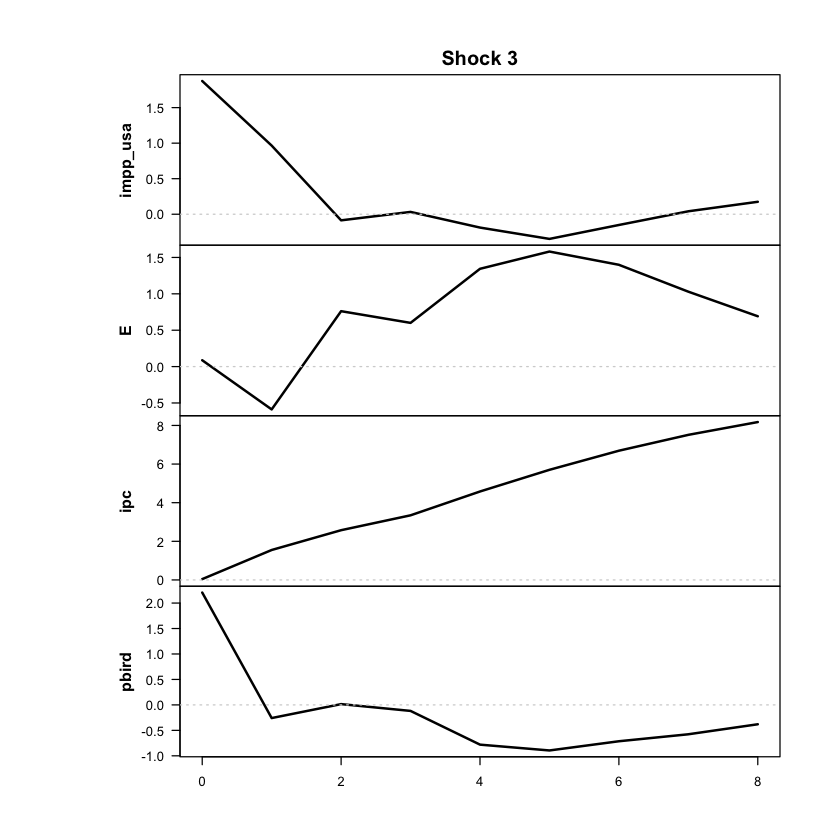

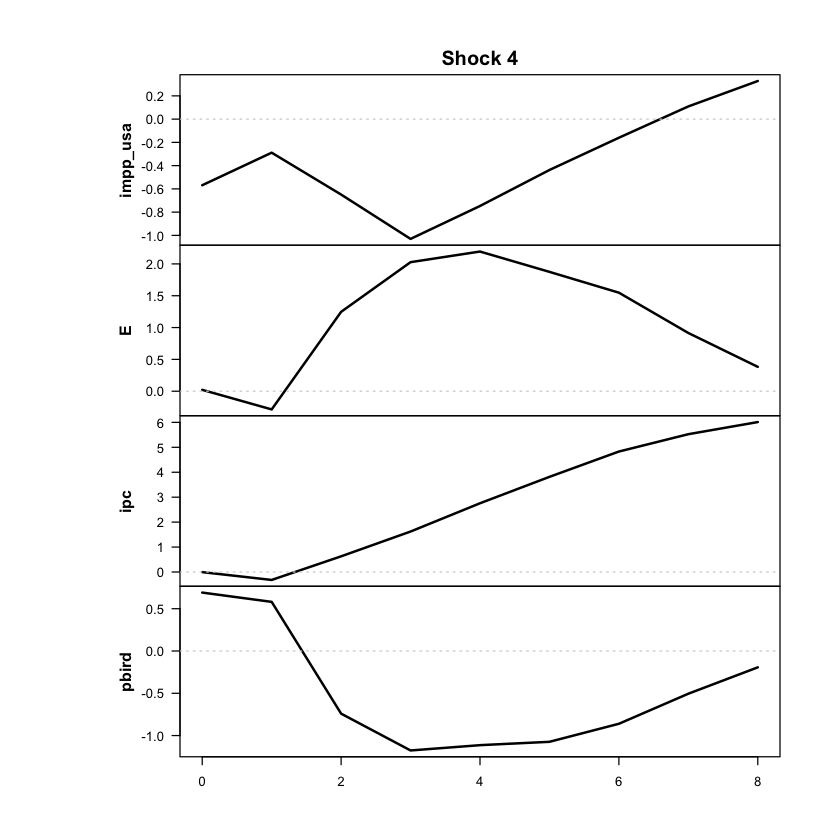

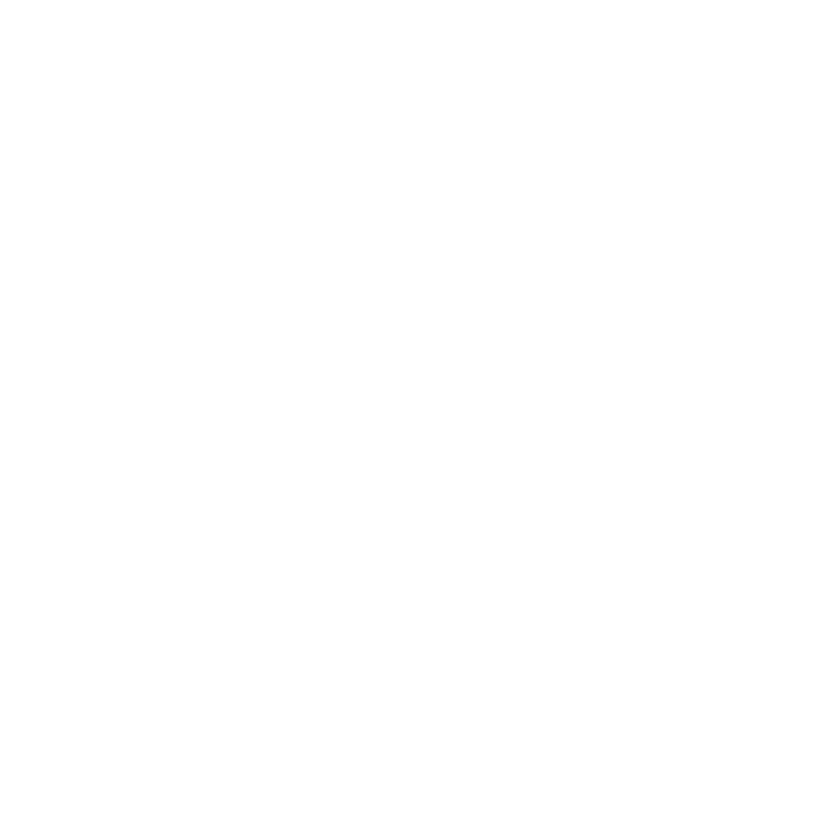

In [117]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [118]:
ic_tvar_t_p2 <- criterios_info(res, "TVAR-t p=2")
print(ic_tvar_t_p2)

      modelo regimenes parametros  loglik    AIC     HQ    BIC
1 TVAR-t p=2         2         94 -681.36 1550.7 1689.3 1896.7


In [119]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 2 | rezagos: 2 | errores: Student 
Grados de libertad de la t de Student: 2.02 
Umbrales: 37.2% trimestral (254% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 266 | régimen 2 = 27 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.80      0.34
E             8.78     51.85
ipc           8.98     67.27
pbird         0.58      0.20


In [120]:
explorar_optimos(res, n = 10)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -681.36            37.2    NA          2           266/27
             2 -686.26            35.8    NA          2           265/28
             3 -686.27            35.9    NA          2           265/28
             4 -686.27            36.5    NA          2           265/28
             5 -686.27            36.7    NA          2           265/28
             6 -686.27            34.3    NA          2           265/28
             7 -686.27            35.5    NA          2           265/28
             8 -686.28            34.5    NA          2           265/28
             9 -686

In [121]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 94, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.02 (for all regimes) 
Upper threshold: 1.59 
Regime means: 0.20, 0.12, 0.24, 0.35

   Y      phi0          A1                                 A2                  
1 y1 = [  0.00 ] + [  0.48 -0.04  0.30  0.05 ] y1.1 + [  0.02 -0.13  0.13  0.01
2 y2   [ -0.01 ]   [ -0.02  0.50  0.19 -0.02 ] y2.1   [ -0.01 -0.12  0.20  0.01
3 y3   [  0.01 ]   [  0.00  0.15  0.70  0.02 ] y3.1   [  0.01 -0.05  0.18  0.00
4 y4   [  0.30 ]   [  0.07 -0.19  0.00  0.19 ] y4.1   [ -0.04 -0.14  0.07 -0.01
             Omega                     1/2     
1 ] y1.2 + [ 27.35 -0.58  0.52  2.88 ]     eps1
2 ] y2.2   [ -0.58  3.30  0.99 -0.82 ]     eps2
3 ] y3.2   [  0.52  0.99  1.51 -0.89 ]     eps3
4 ] y4.2   [  2.88 -0.82 -0.89 40.30 ]     eps4

Regime 2 
Regime means: -0.39, -0.78, -0.24,  1.

In [122]:
shock_tvar_t_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar_t_p2 <- 2
shock_tvar_t_p2

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0001 -0.0148  0.1061 -0.0967
  E         0.2381  0.3594  0.0428  0.0317
  ipc       0.2414 -0.0307  0.0174 -0.0053
  pbird    -0.0294 -0.0210  0.1255  0.1181

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.53    0.85    0.03    0.02 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  1.014  -0.085   0.408  -0.167 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — tvar t p2

Correr solo si el modelo pasó el diagnóstico.

In [123]:
out_impp_usa_tvar_t_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_t_p2)

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 266 | régimen 2 = 27 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0           -0.0853           -0.0853
2         1           -0.0328            0.4368
3         2           -0.0034            0.4139
4         3            0.0050            0.5307
5         4            0.0020            0.5799
6         5           -0.0007            0.6213
7         6           -0.0036            0.6323
8         7           -0.0068            0.6483
9         8           -0.0101            0.6548


In [124]:
out_impp_usa_tvar_t_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar_t_p2,
                      definicion = "acumulado")

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 266 | régimen 2 = 27 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0           -0.0853           -0.0853
2         1           -0.0220            0.2045
3         2           -0.0022            0.1755
4         3            0.0029            0.1992
5         4            0.0009            0.2011
6         5           -0.0008            0.2006
7         6           -0.0026            0.1950
8         7           -0.0047            0.1901
9         8           -0.0069            0.1820


In [125]:
   out_impp_usa_tvar_t_p2_acum_s456 <- erpt_historia(res, data = df_ERPT_Arg,
                                                     endog = c("impp_usa", "E", "ipc", "pbird"),
                                                     shock_num = shock_tvar_t_p2,
                                                     definicion = "acumulado", semilla = 456)

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 266 | régimen 2 = 27 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0           -0.0853           -0.0853
2         1           -0.0204            0.2036
3         2            0.0008            0.1766
4         3            0.0078            0.2024
5         4            0.0097            0.2064
6         5            0.0100            0.2071
7         6            0.0099            0.2039
8         7            0.0095            0.1959
9         8            0.0090            0.1864


Umbrales (inflación trimestral de t-1): 37.2% trimestral (254% anualizada) 
Trimestres por régimen: régimen 1 = 266 | régimen 2 = 27 


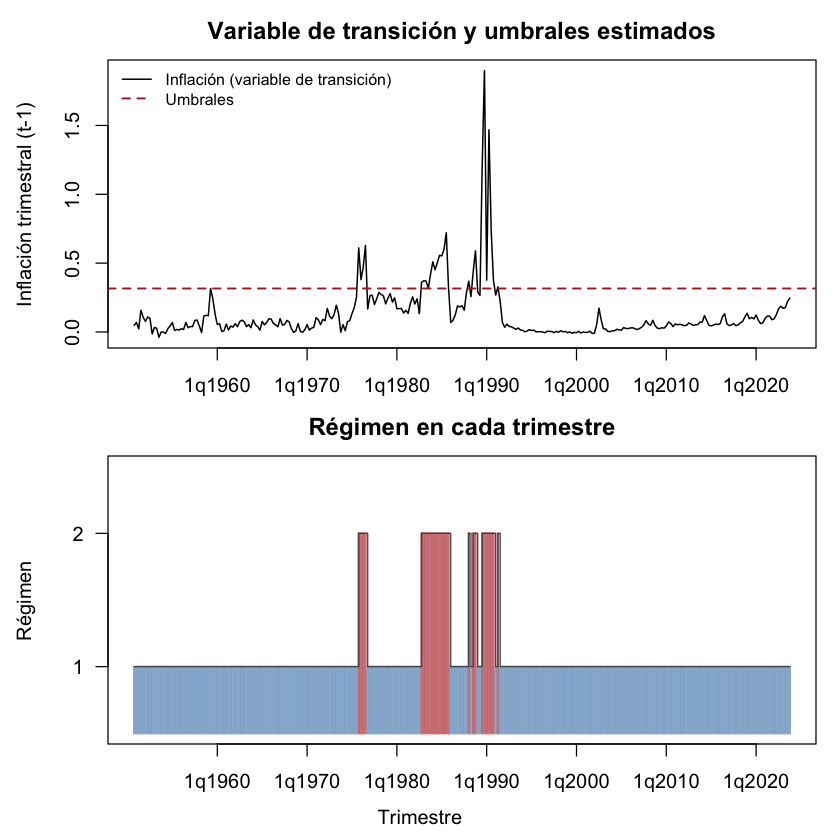

In [126]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar_t_p2_sincap")

### VLSTAR con errores t, p = 2

Muy mal resultado, no conviene correr con p=3. La explicación está en la página 221 de la conversación con Claude (Claude 24 sept 2026 Diferencia entre IRF y GIRF).

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -1188.26

The largest loglik: -753.798

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -1085.76

The largest loglik: -671.17

Filtering inappropriate estimates...

Filtered through 68 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 1 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


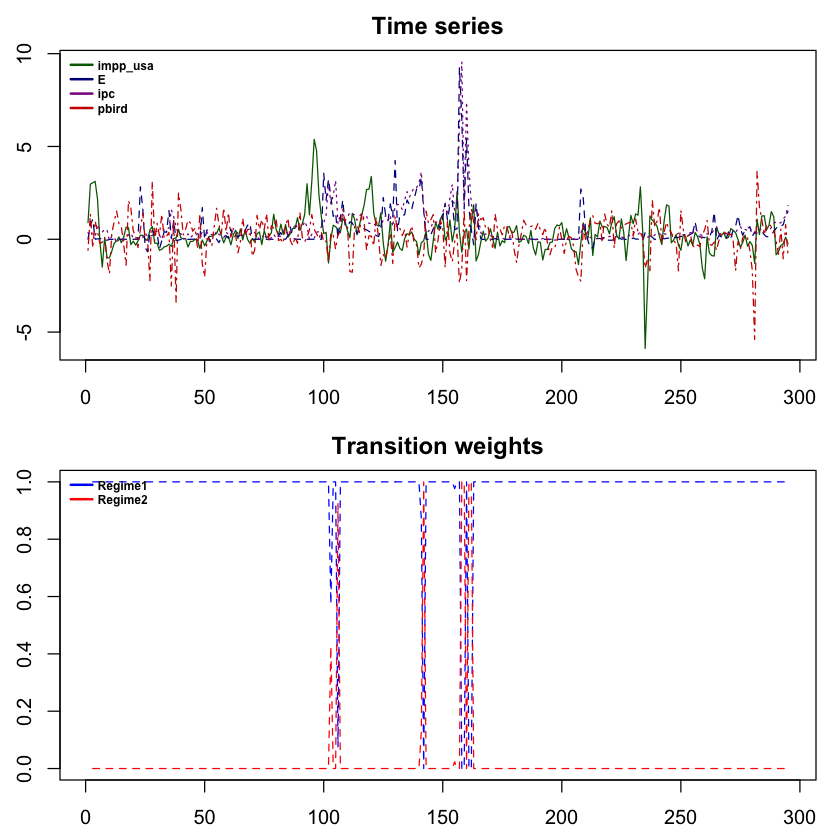

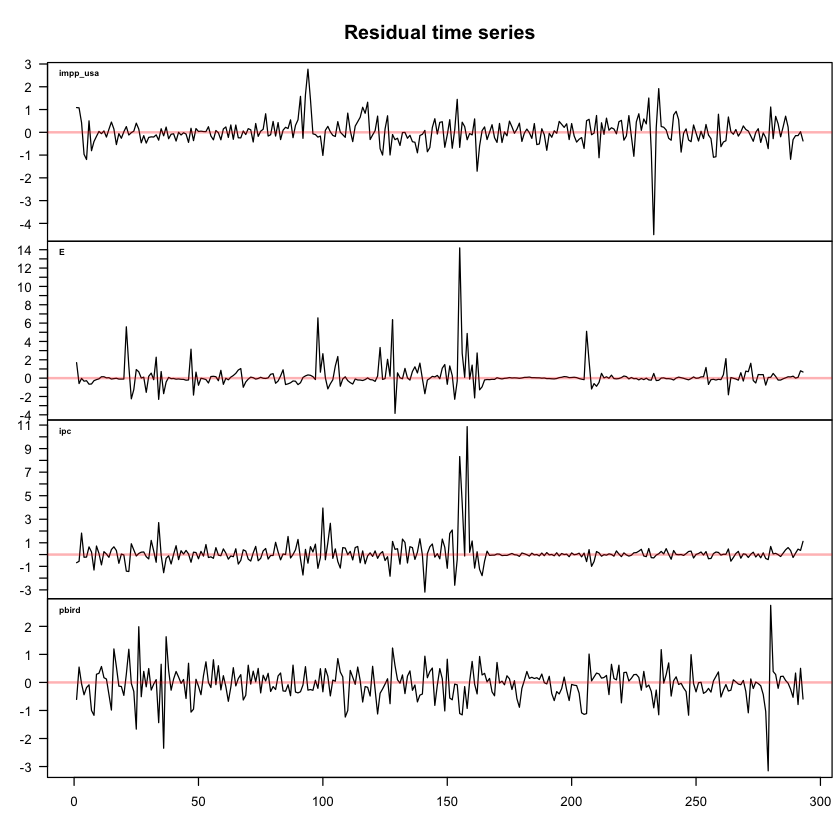

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



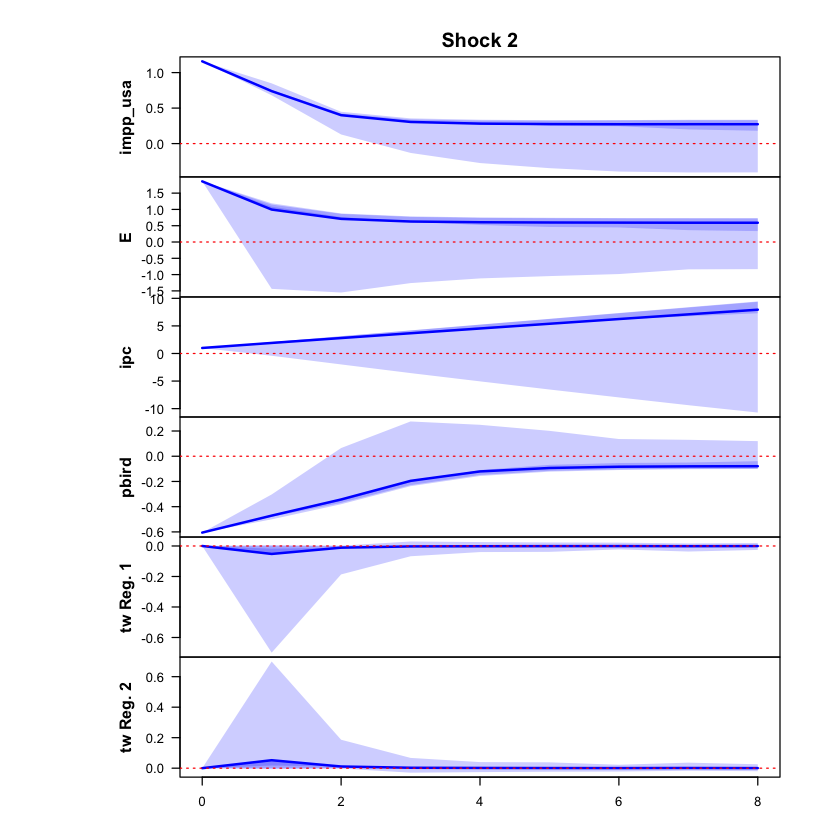

 >>> Linear IRF ( 1  shock units)


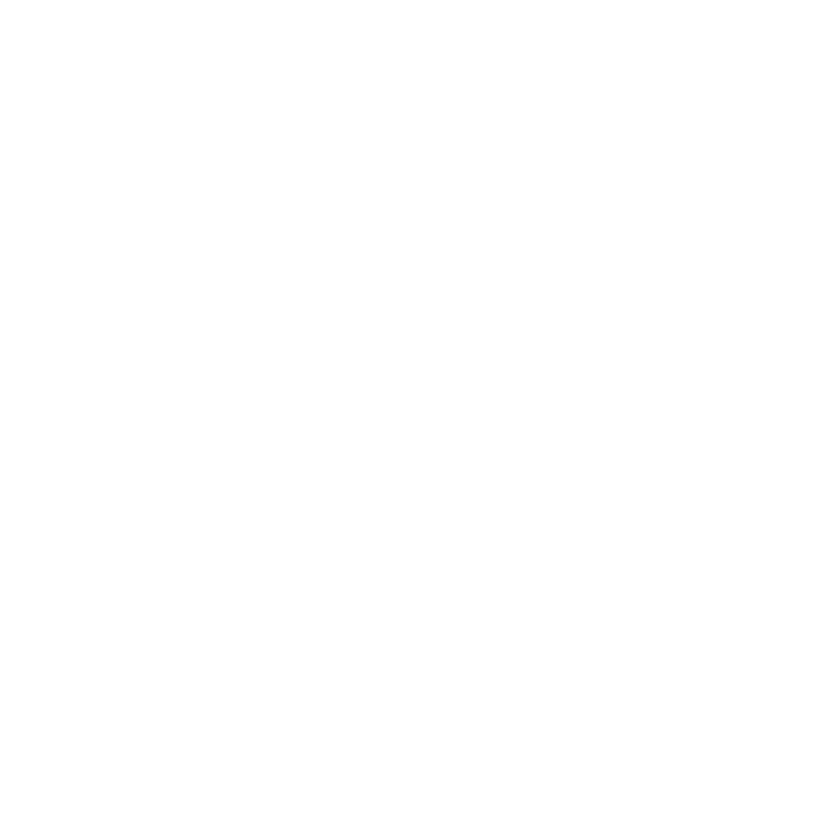

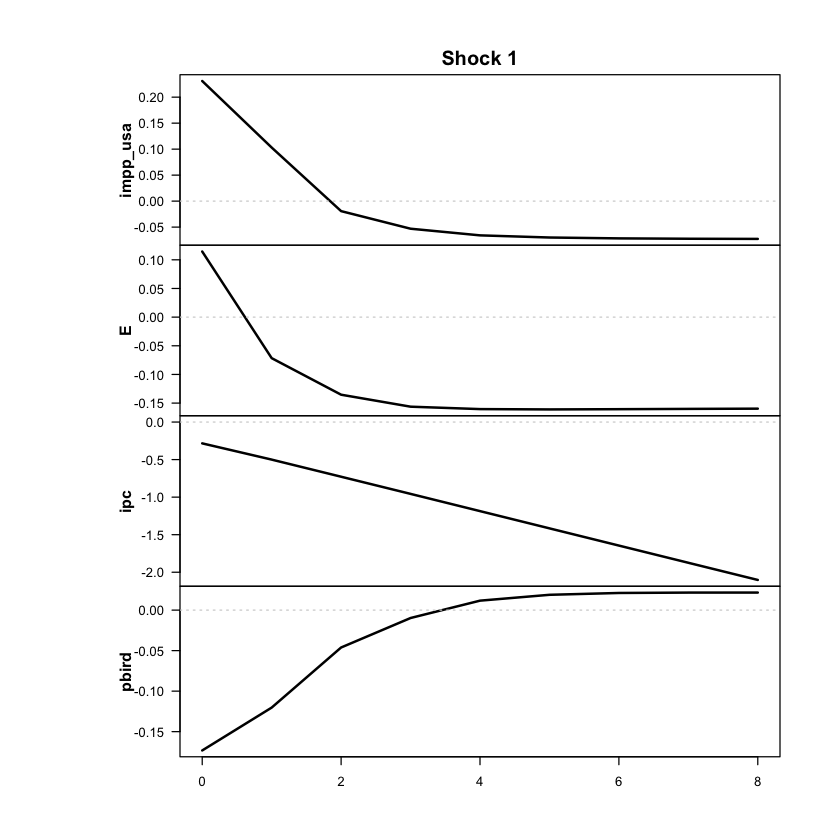

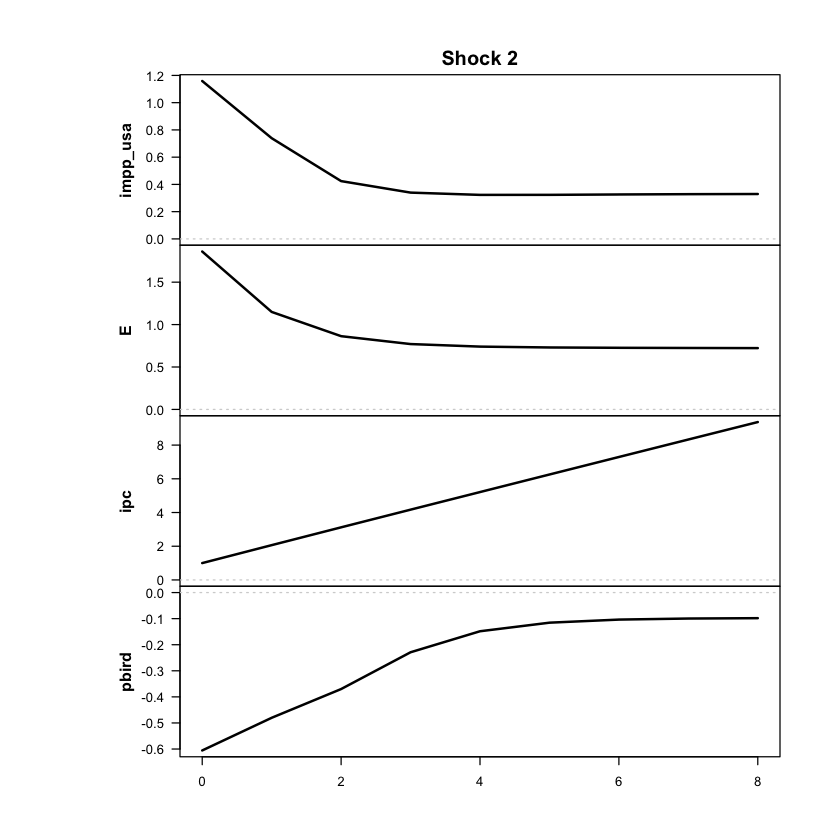

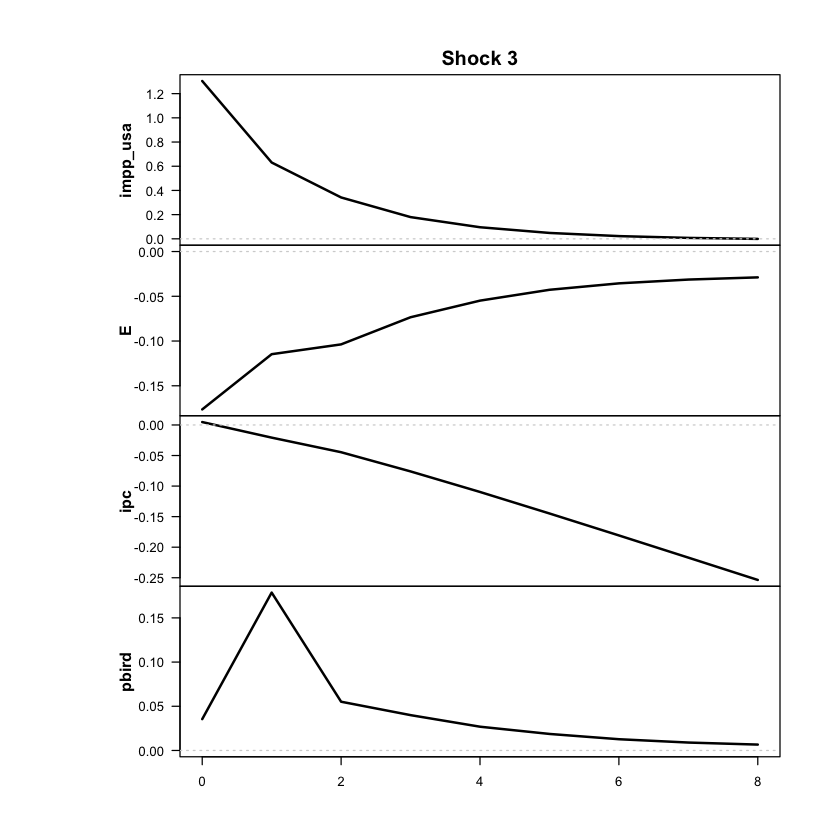

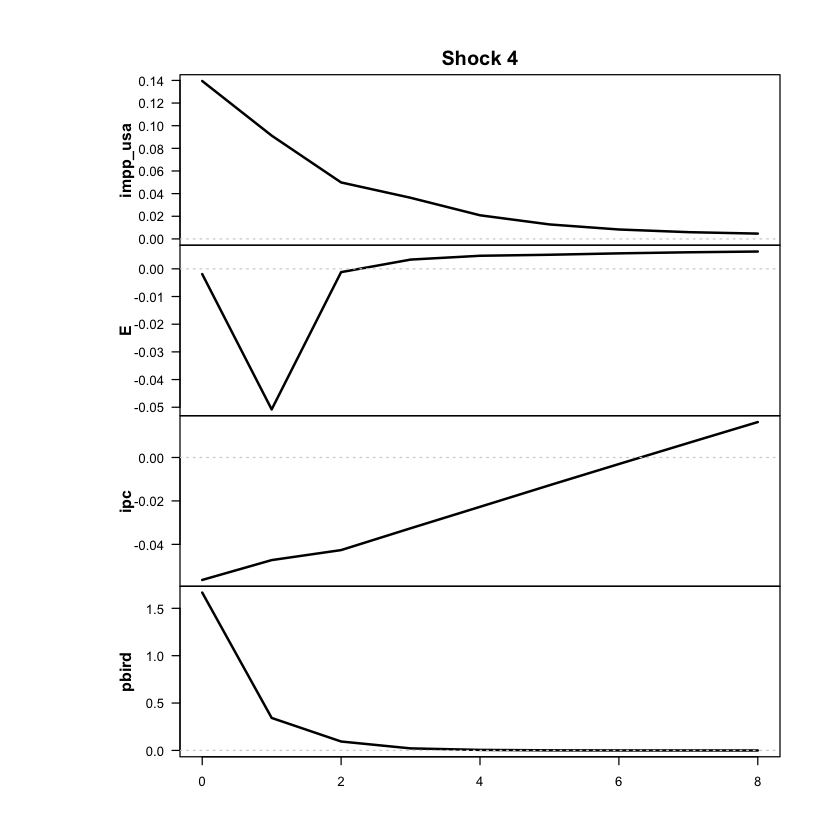

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



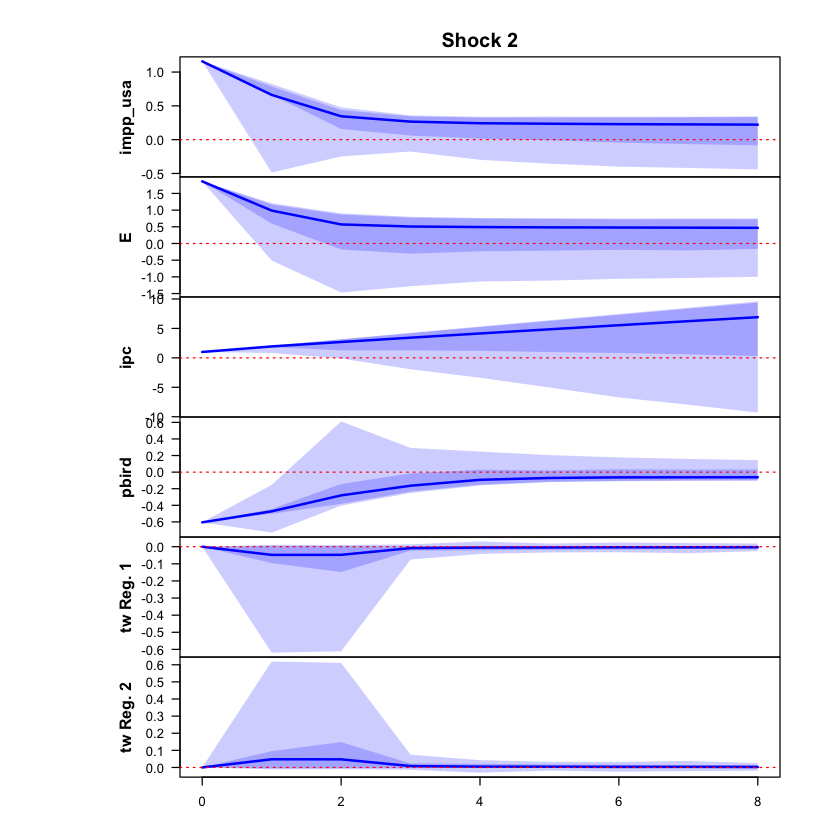

 >>> Linear IRF ( 1  shock units)


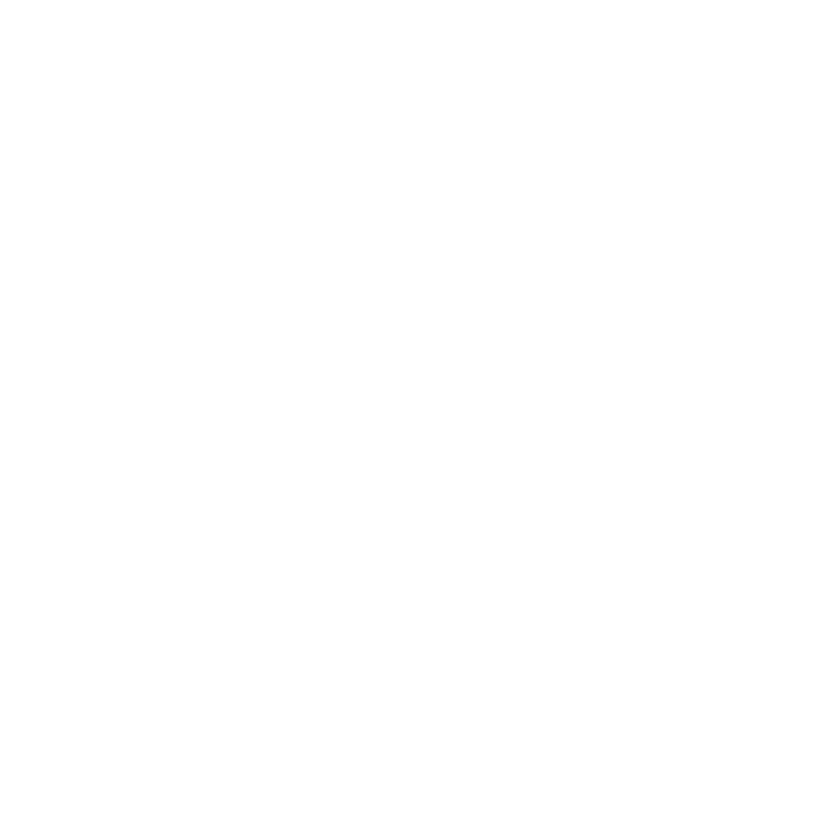

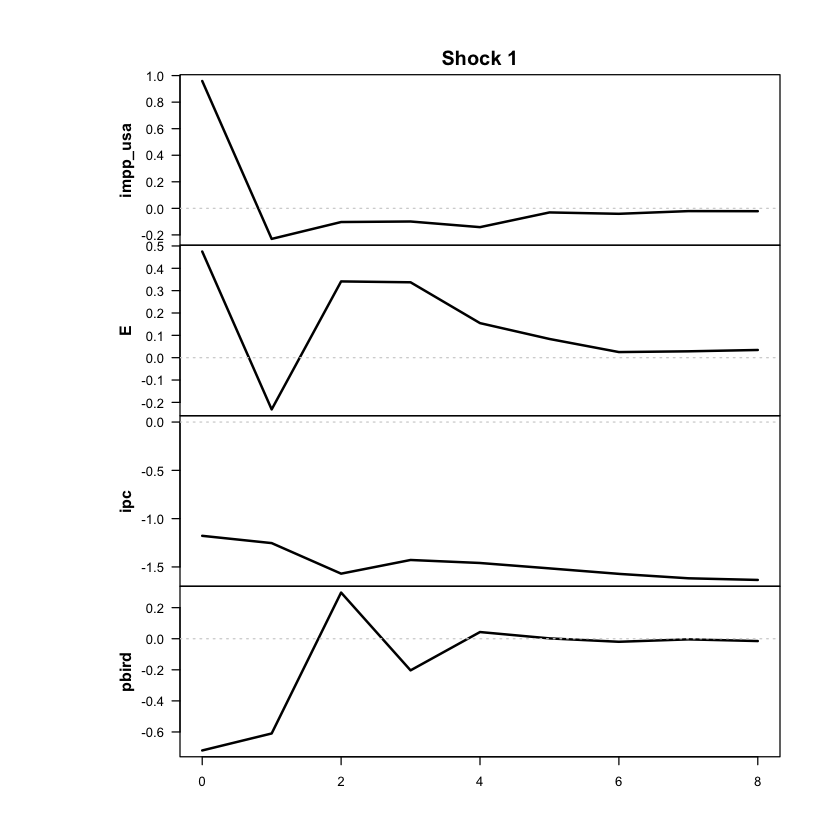

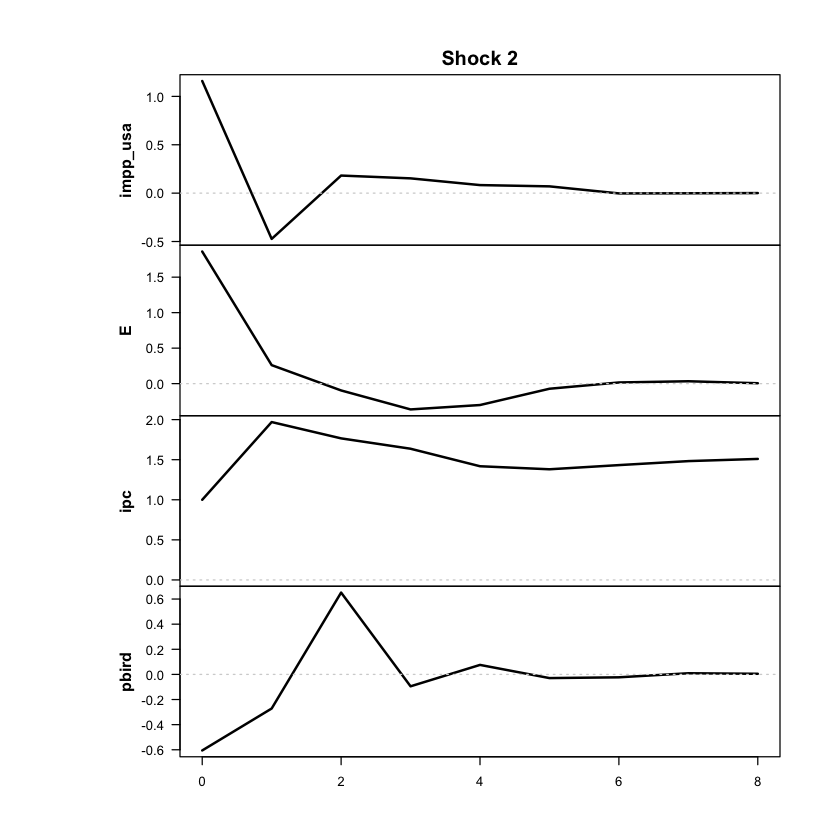

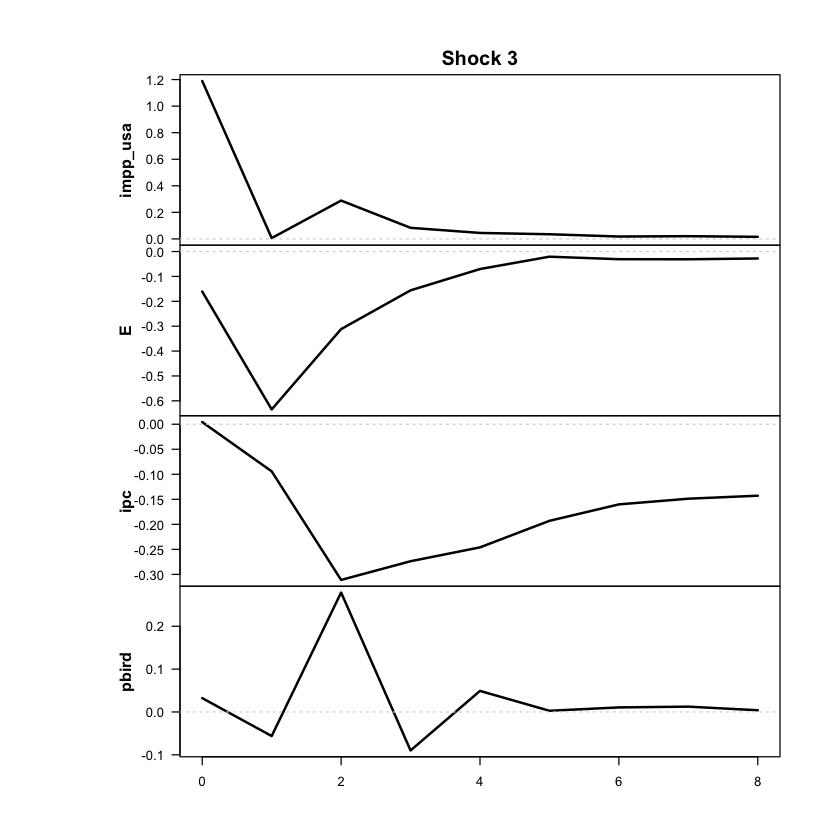

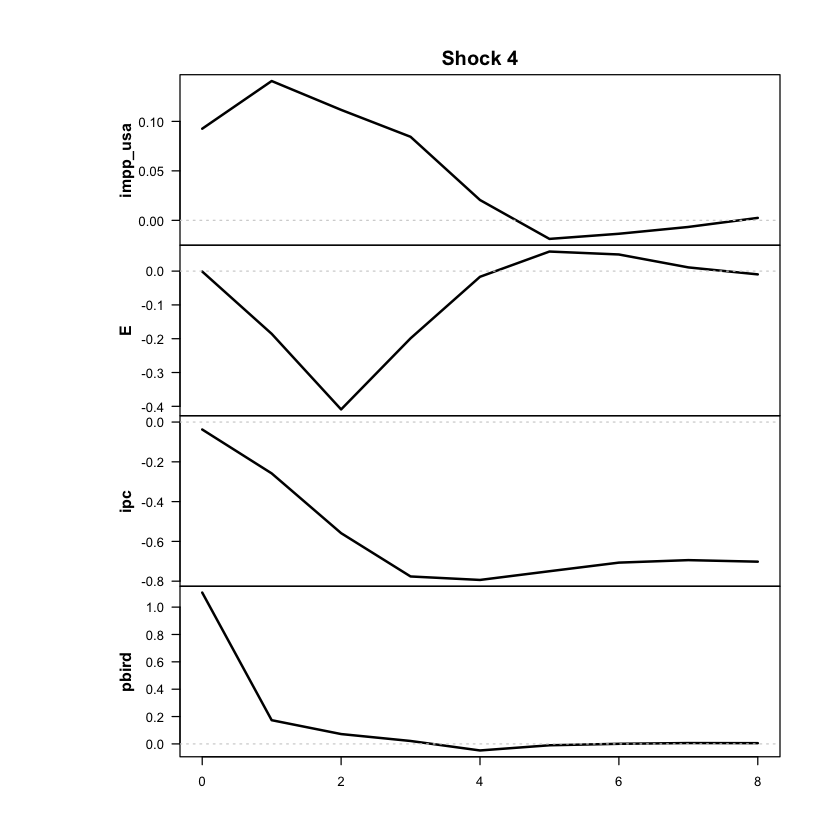

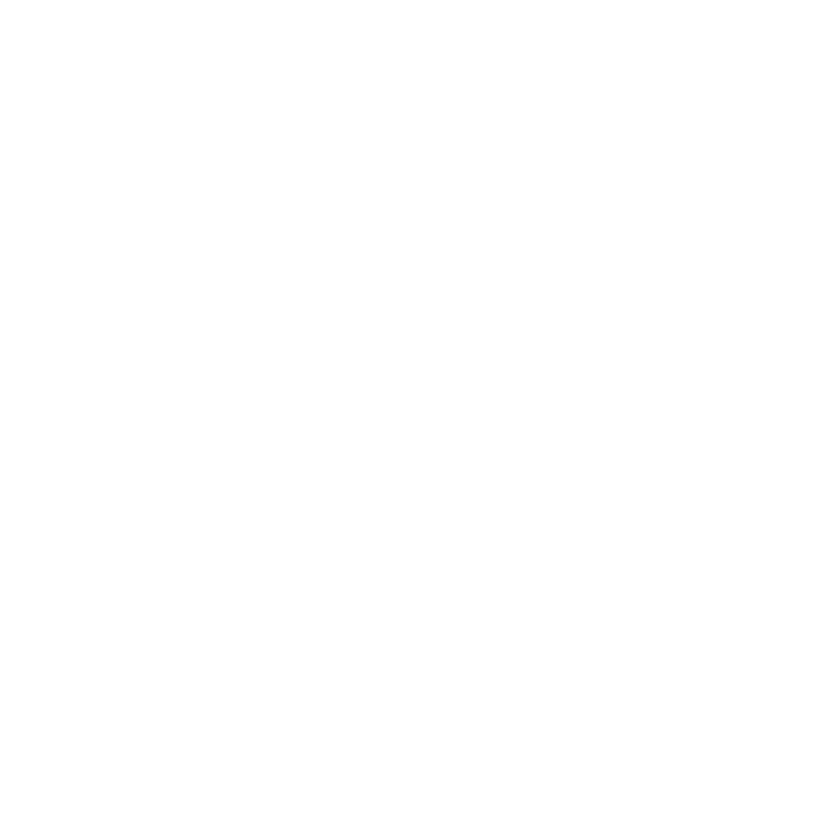

In [127]:
res <- run_vlstar (
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [128]:
ic_vlstar_t_p2 <- criterios_info(res, "VLSTAR-t p=2")
print(ic_vlstar_t_p2)

        modelo regimenes parametros  loglik    AIC     HQ    BIC
1 VLSTAR-t p=2         2         95 -786.16 1762.3 1902.3 2111.9


In [129]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Student 
Grados de libertad de la t de Student: 2.31 
Umbral (c): 84.5 % trimestral ( 1060 % anualizada) | gamma: 31.5 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 287 | régimen 2 = 6 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.76      0.27
E            11.34     60.39
ipc          12.14     90.75
pbird         0.54      0.78


In [130]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -671.17            31.1  3.42        2.7           260/33
             2 -680.40            38.8  2.03        2.4           268/25
             3 -688.12            37.8  2.85        2.7           268/25
             4 -692.01            37.5  1.87        2.4           267/26
             5 -704.01            40.4  2.38        2.7           269/24
             6 -707.21              40  2.12        2.4           269/24
             7 -712.26            37.2  1.99        2.5           266/27
             8 -713.09              36  2.51        2.6           265/28
             9 -714

In [131]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Student STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 95, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Degrees of freedom: 2.31 (for all regimes) 
Weight params: 3.09 (location), 31.50 (scale) 
Regime means: -1.29, -3.08, -4.36,  0.81

   Y      phi0          A1                                 A2                  
1 y1 = [  0.04 ] + [  0.49  0.07  0.05  0.02 ] y1.1 + [  0.01 -0.12  0.14  0.01
2 y2   [ -0.02 ]   [ -0.03  0.42  0.40 -0.01 ] y2.1   [ -0.02 -0.01  0.03  0.02
3 y3   [ -0.02 ]   [  0.00  0.15  0.80  0.03 ] y3.1   [  0.00 -0.04  0.12  0.00
4 y4   [  0.30 ]   [  0.08 -0.36  0.22  0.21 ] y4.1   [ -0.06 -0.03 -0.03  0.00
             Omega                     1/2     
1 ] y1.2 + [  1.87 -0.04  0.02  0.19 ]     eps1
2 ] y2.2   [ -0.04  0.30  0.10 -0.11 ]     eps2
3 ] y3.2   [  0.02  0.10  0.16 -0.09 ]     eps3
4 ] y4.2   [  0.19 -0.11 -0.09  2.83 ]     eps4

Regime 2 
Regime mean

In [132]:
shock_vlstar_t_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p2 <- 2
shock_vlstar_t_p2

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0064  0.0087  0.0360  0.0038
  E         0.0274  0.1210 -0.0422 -0.0005
  ipc      -0.0563  0.0539  0.0009 -0.0112
  pbird    -0.0048 -0.0046  0.0010  0.0462

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.27    0.75    0.13    0.00 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
 -2.057   0.446  -0.022  24.568 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — vlstar t p2

Correr solo si el modelo pasó el diagnóstico.

In [133]:
out_impp_usa_vlstar_t_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_t_p2)

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 285 | régimen 2 = 6 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0            0.4459            0.4459
2         1            0.9017            0.7381
3         2            1.3506            0.8944
4         3            1.7919            1.0485
5         4            2.2294            1.2028
6         5            2.6647            1.3548
7         6            3.0976            1.5081
8         7            3.5232            1.6601
9         8            3.9479            1.8137


In [134]:
out_impp_usa_vlstar_t_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_t_p2,
                      definicion = "acumulado")

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 285 | régimen 2 = 6 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0            0.4459            0.4459
2         1            0.5607            0.5781
3         2            0.6813            0.4964
4         3            0.7434            0.9874
5         4            0.8325            0.9392
6         5            0.8555            0.9488
7         6            0.8883            0.9648
8         7            0.9147            0.9815
9         8            0.9363            0.9964


Parámetros usados -> c (escalado): 3.09 | gamma: 31.5 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.6127 | franja 10%-90%: 0.5988 a 0.6265 


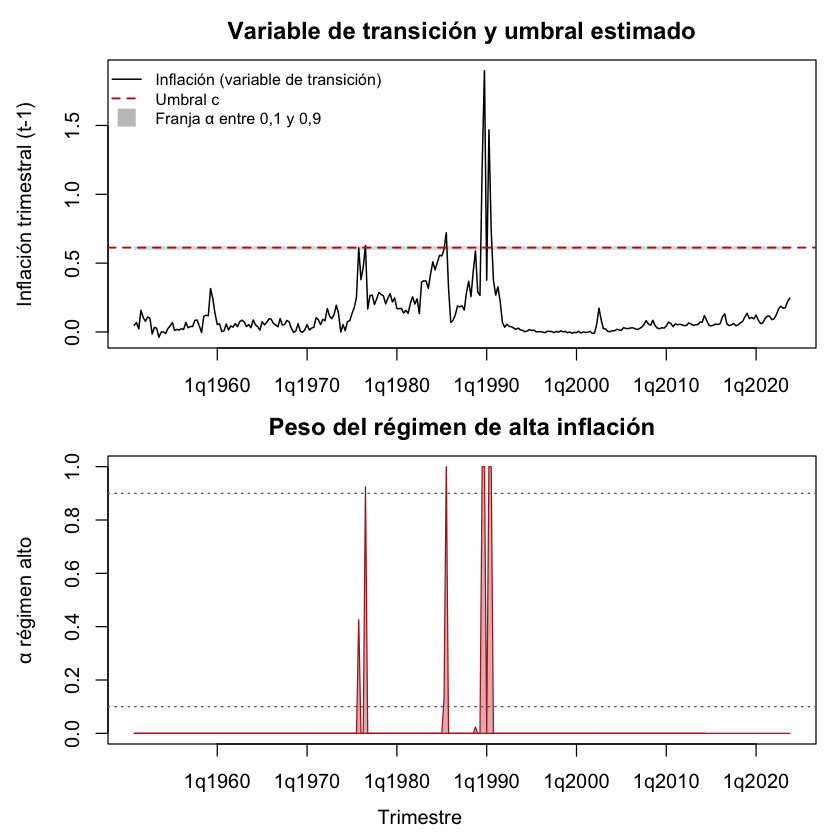

In [135]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_t_p2_sincap")

### VLSTAR con errores t, p = 3

In [ ]:
res <- run_vlstar (
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 3,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  cond_dist = "Student"   # errores t de Student
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [ ]:
ic_vlstar_t_p3 <- criterios_info(res, "VLSTAR-t p=3")
print(ic_vlstar_t_p3)

In [ ]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

In [ ]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

In [ ]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

In [ ]:
shock_vlstar_t_p3 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_t_p3 <- 2
shock_vlstar_t_p3

### ERPT — vlstar t p3

Correr solo si el modelo pasó el diagnóstico.

In [ ]:
out_impp_usa_vlstar_t_p3 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_t_p3)

In [ ]:
out_impp_usa_vlstar_t_p3_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_t_p3,
                      definicion = "acumulado")

In [ ]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_t_p3_sincap")

### Comparación: gaussiano vs. t de Student

In [ ]:
rbind(ic_tvar_p2, ic_tvar_p3, ic_tvar_t_p2, ic_vlstar_t_p2, ic_vlstar_t_p3)

## VLSTAR gaussiano, 2 regímenes, p = 2 — estimación en tres etapas

La estimación en tres etapas (`estim_method = "three-phase"`) empieza estimando los coeficientes por mínimos cuadrados y descarta los puntos de partida en los que algún régimen tiene muy pocas observaciones en relación con sus parámetros (`min_obs_coef`). Objetivo: evitar las soluciones degeneradas que aíslan los trimestres de hiperinflación. El modelo se guarda con `3fases_moc3` en el nombre del archivo; los modelos en dos etapas no se pisan.

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating the AR and weight parameters by nonlinear least squares for 10000 vectors of weight parameters...

PHASE 2: Estimating the error distribution parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -951.811

The largest loglik: -948.977

PHASE 3: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -929.338

The largest loglik: -874.954

Filtering inappropriate estimates...

Filtered through 496 inappropriate (or unstable) estimates with a larger (penalized) log-likelihood

Calculating approximate standard errors...

Finished!




========= Unstructured fitted model ==========


Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


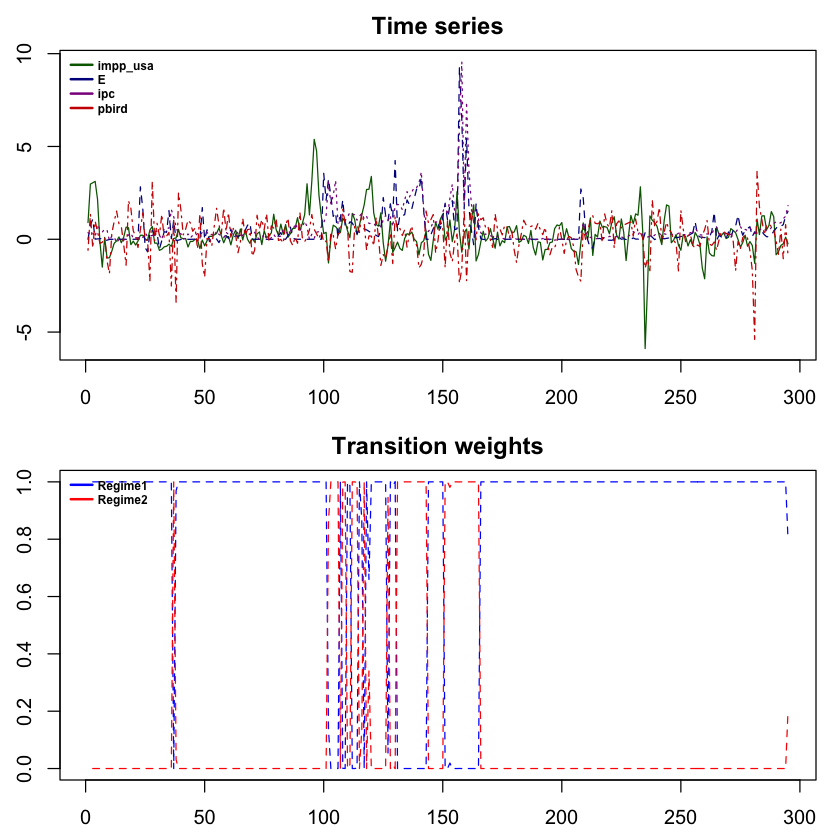

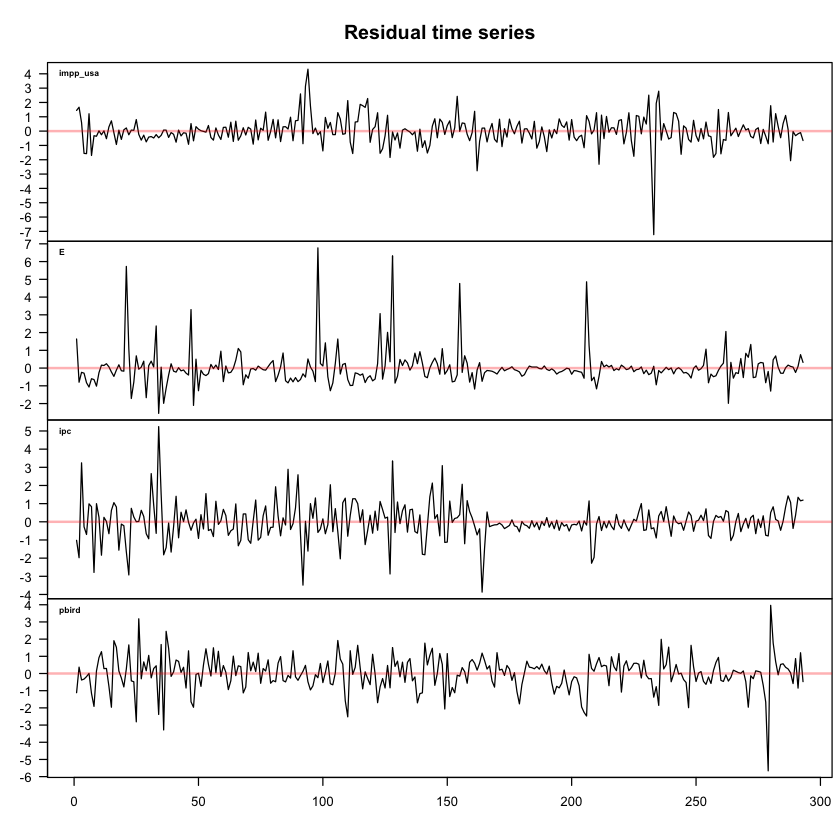

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



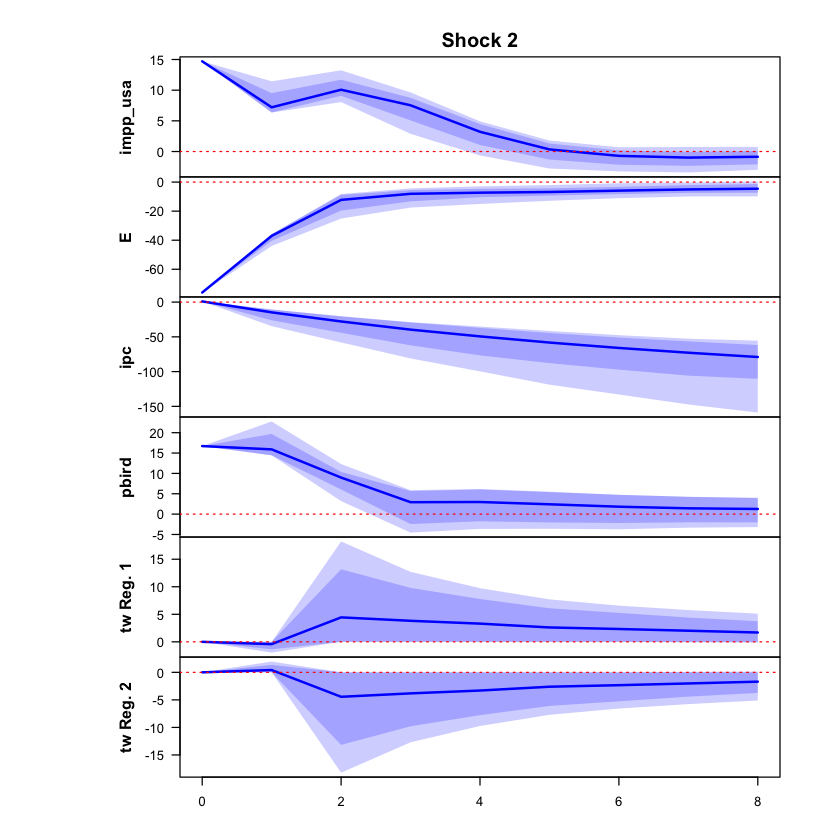

 >>> Linear IRF ( 1  shock units)


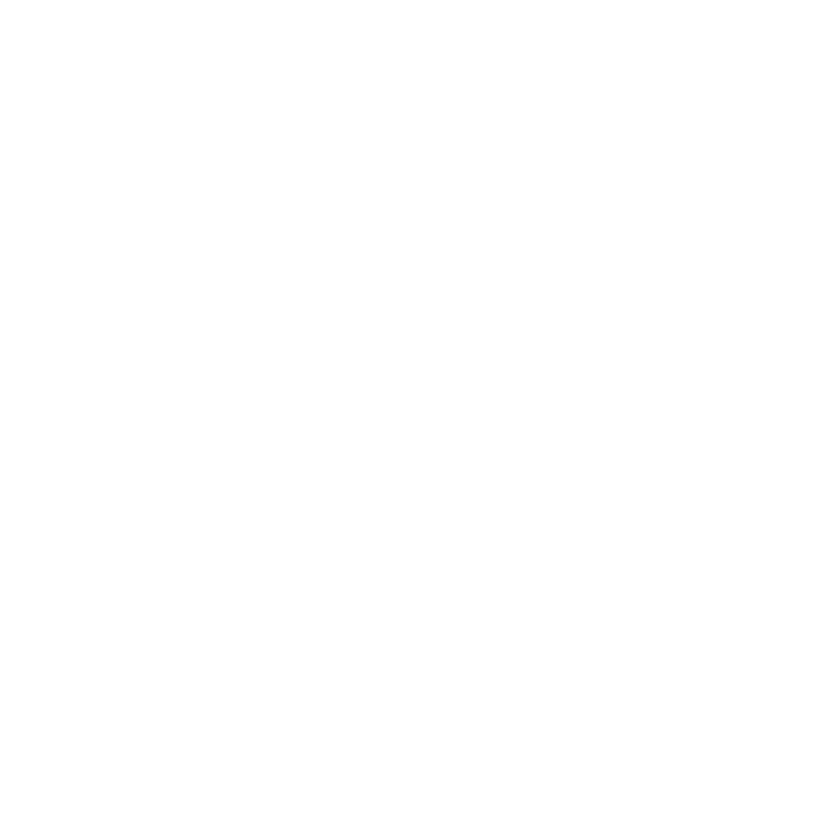

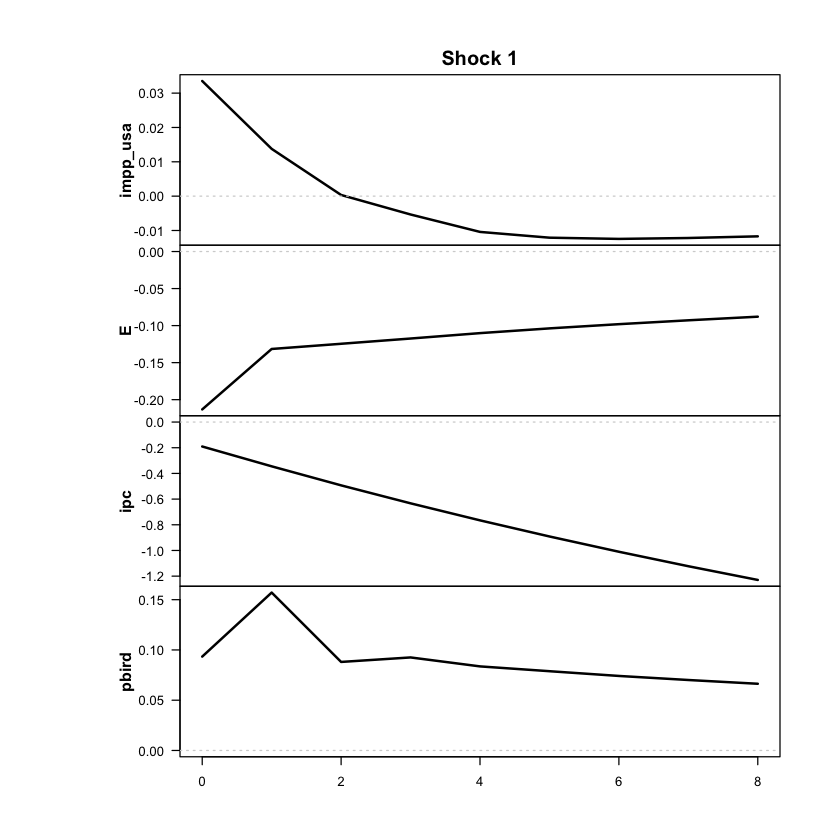

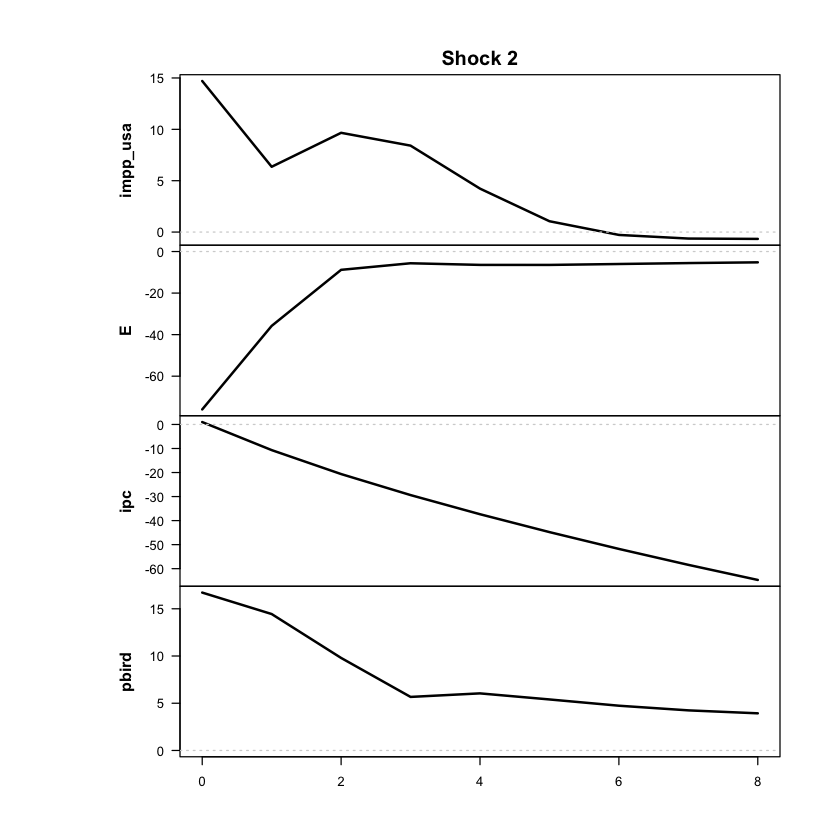

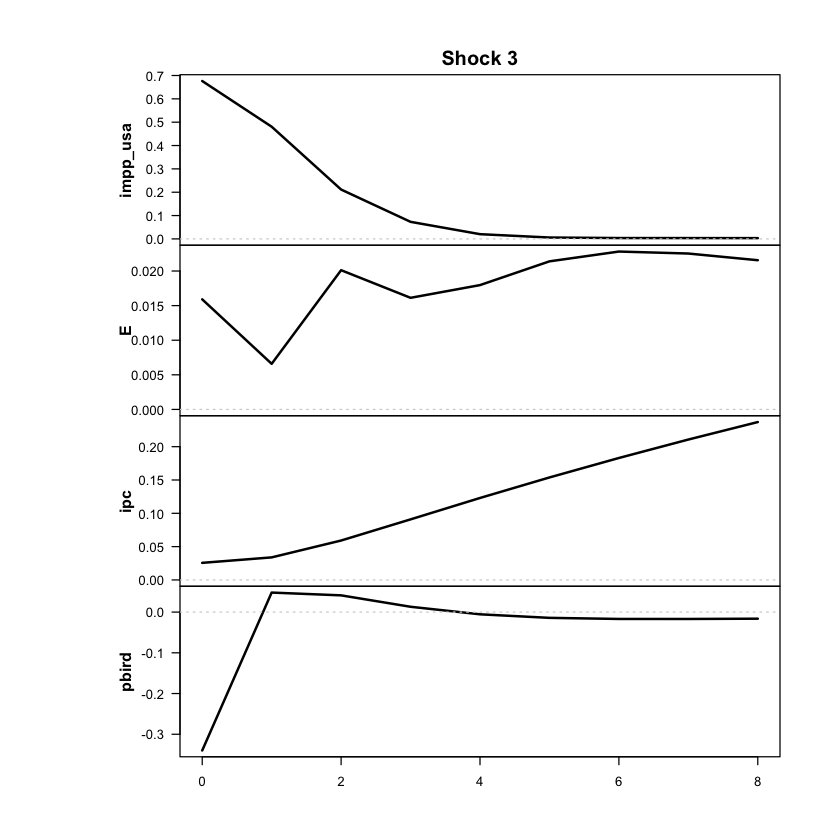

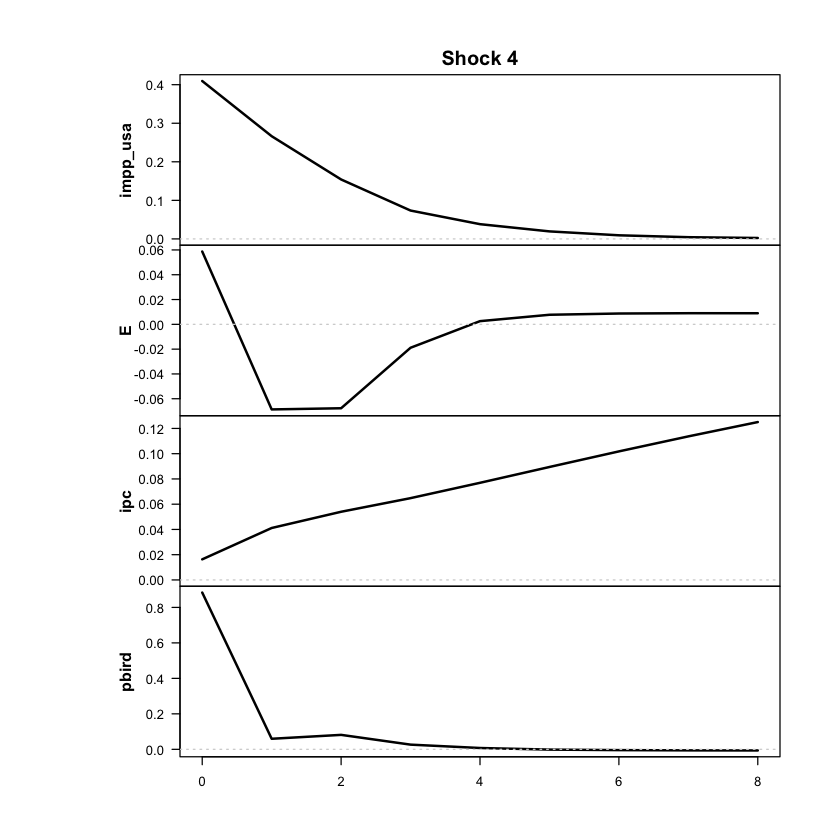

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



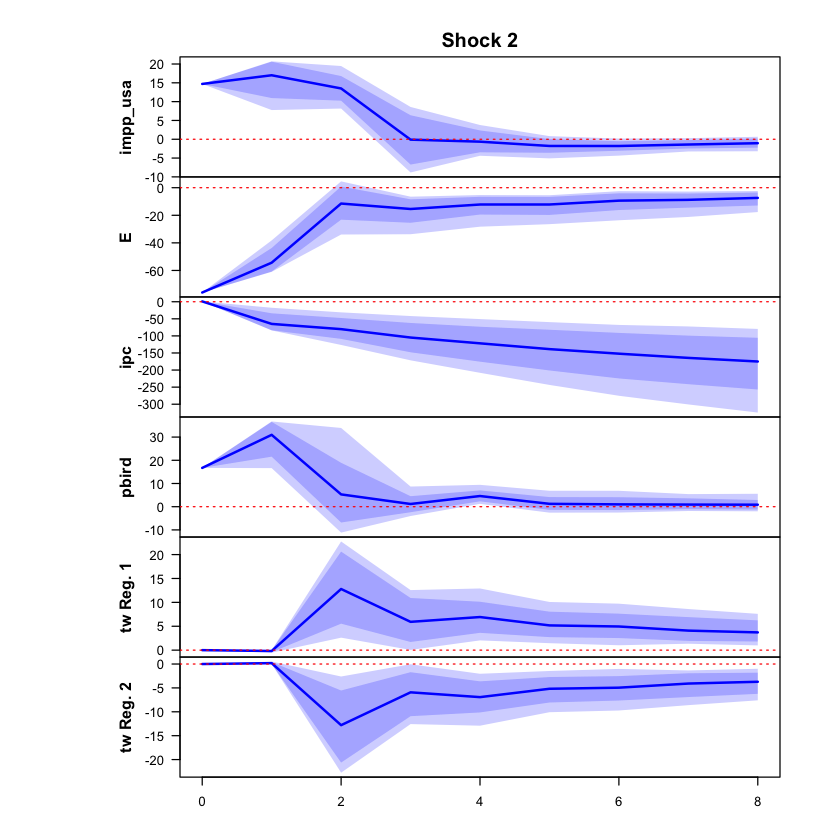

 >>> Linear IRF ( 1  shock units)


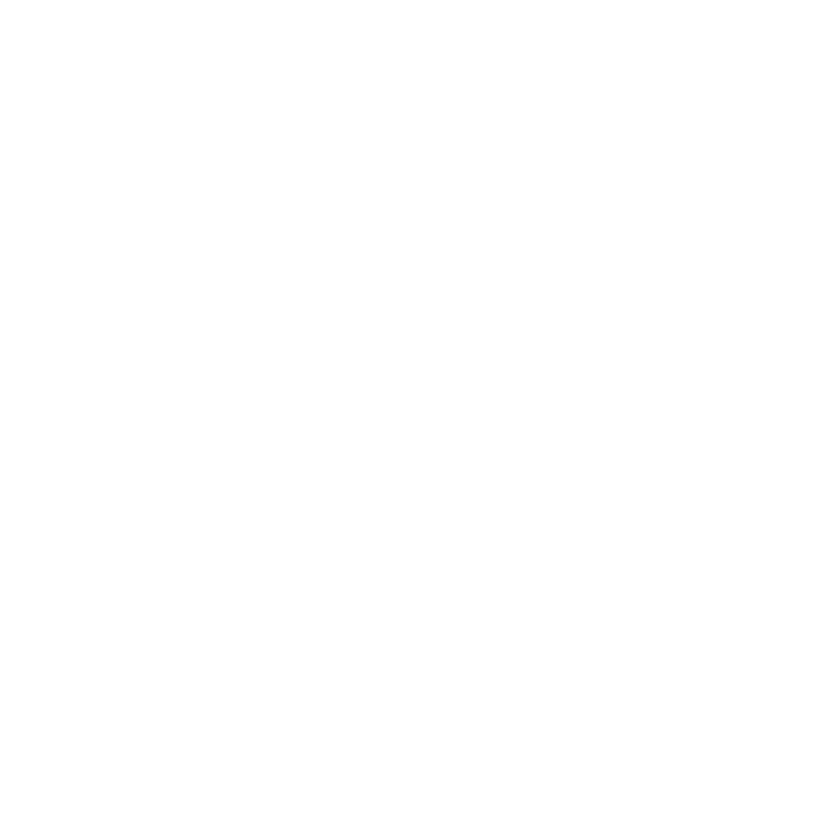

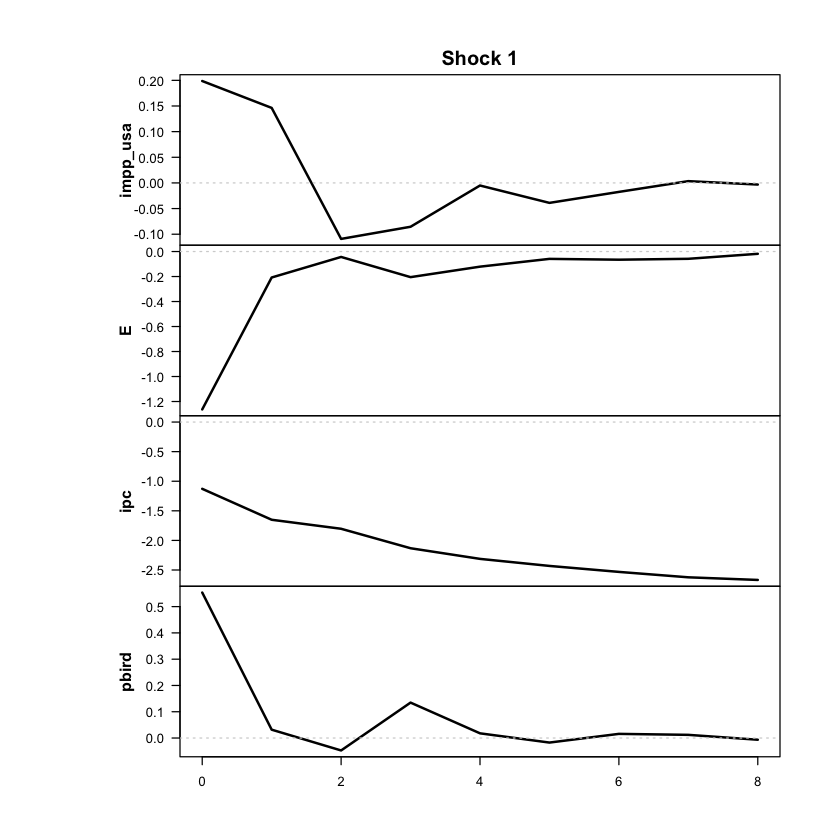

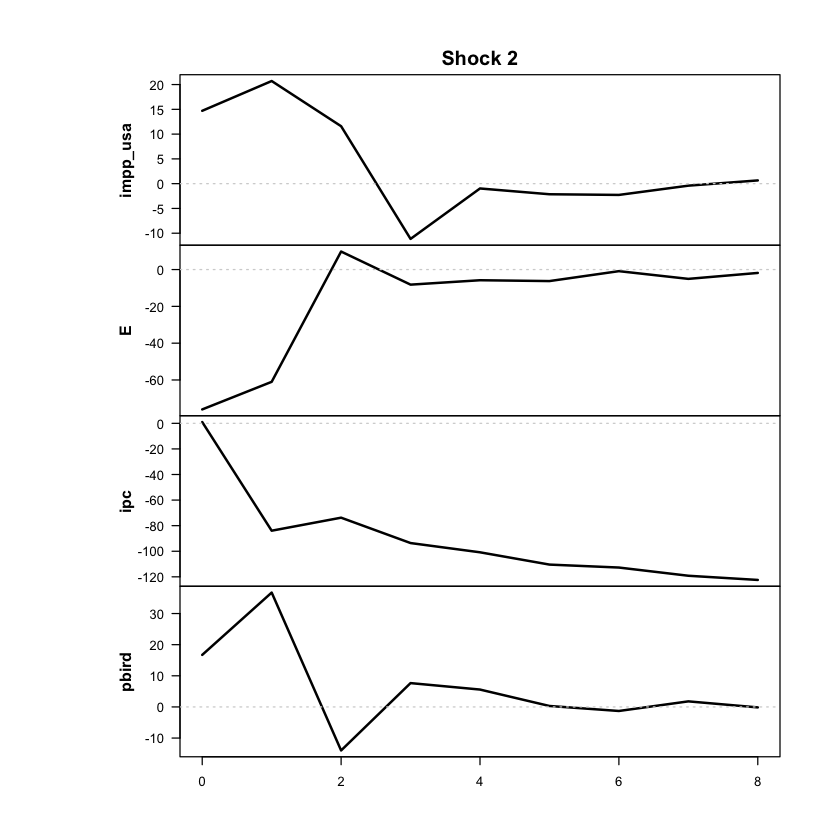

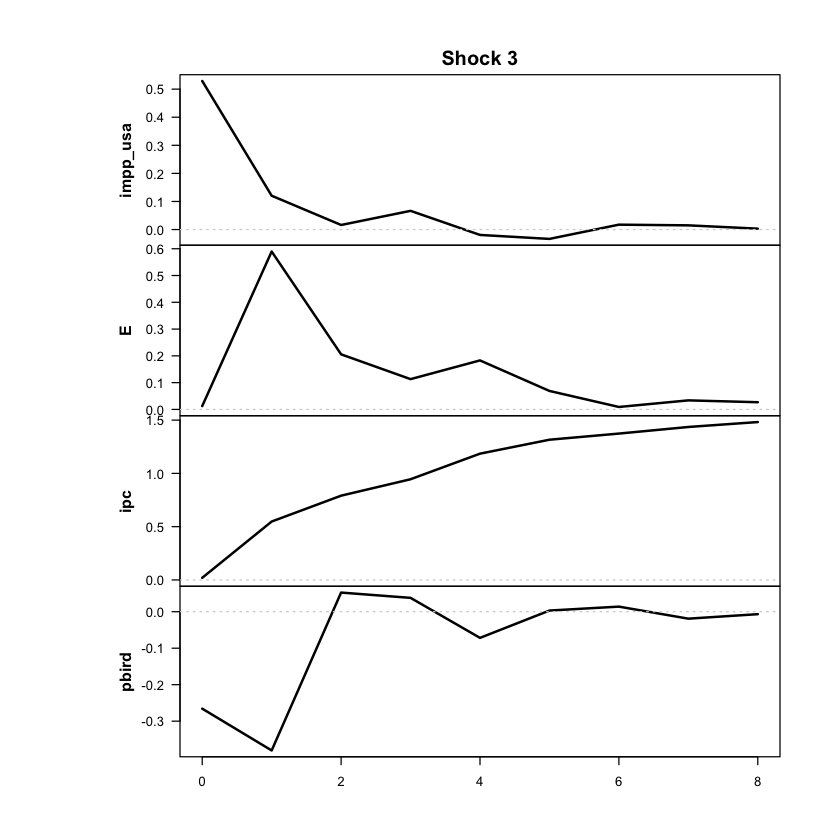

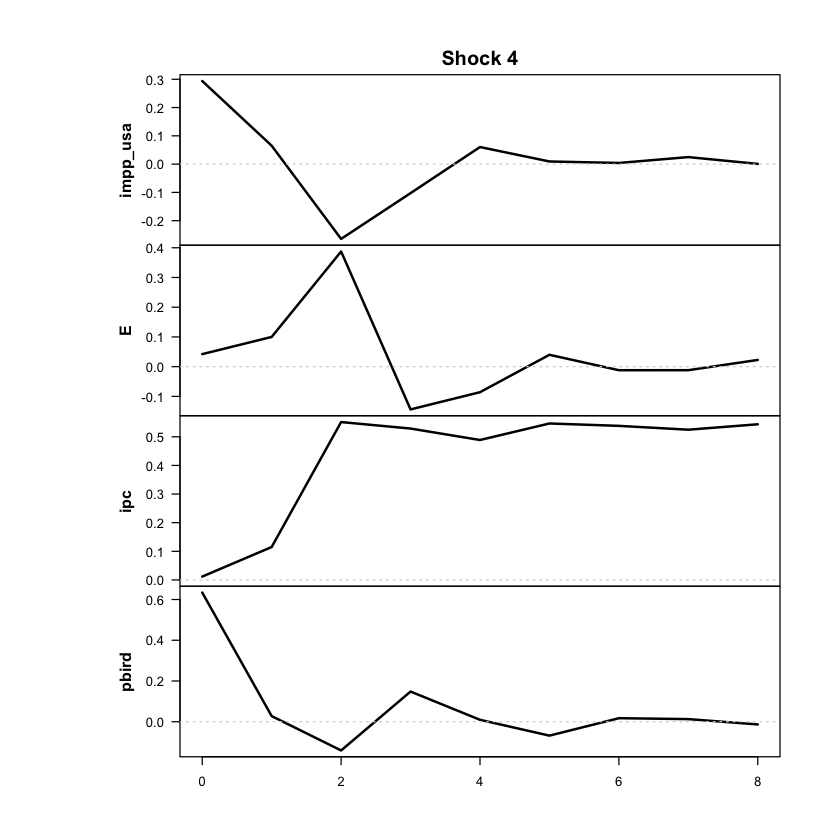

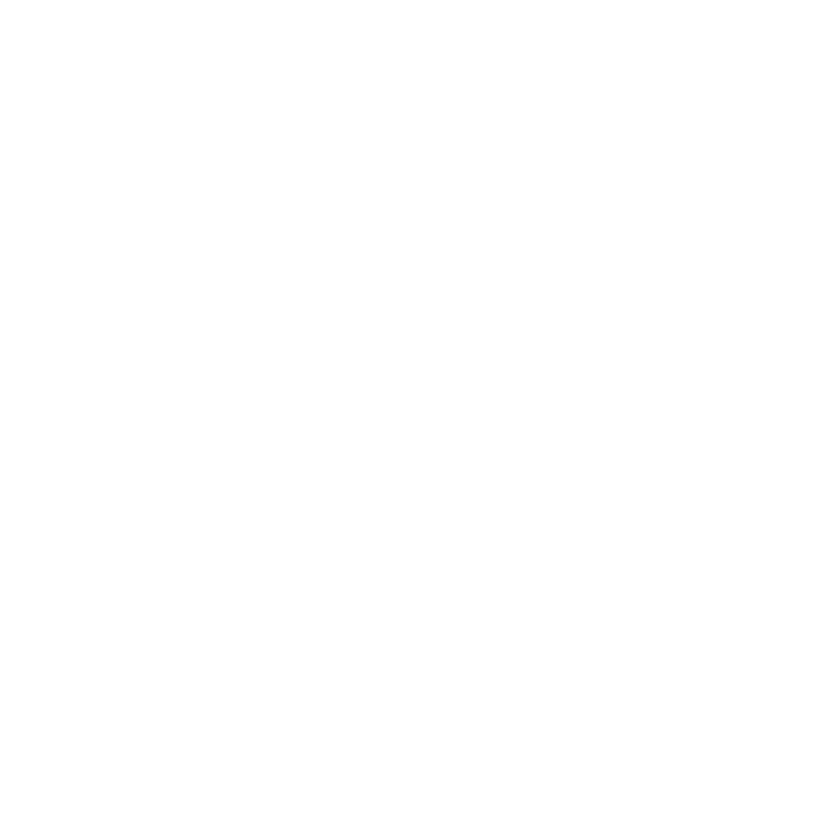

In [137]:
res <- run_vlstar (
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE,
  estim_method = "three-phase",   # estimación en tres etapas
  min_obs_coef = 3                # mínimo de observaciones por régimen (default de sstvars)
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [138]:
ic_vlstar_3f_p2 <- criterios_info(res, "VLSTAR 3 etapas p=2")
print(ic_vlstar_3f_p2)

               modelo regimenes parametros  loglik    AIC     HQ    BIC
1 VLSTAR 3 etapas p=2         2         94 -929.33 2046.7 2185.2 2392.6


In [139]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: logistic | regímenes: 2 | rezagos: 2 | errores: Gaussian 
Umbral (c): 28.3 % trimestral ( 171 % anualizada) | gamma: 99.61 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 252 | régimen 2 = 41 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2
impp_usa      0.75      0.75
E             6.62     53.24
ipc           7.31     58.86
pbird         0.63      0.01


In [140]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -874.95            40.1  3.93         NA           269/24
             2 -876.82            40.6  3.95         NA           269/24
             3 -876.94            37.8  3.91         NA           268/25
             4 -877.08            39.3  4.29         NA           269/24
             5 -877.08            39.6  4.05         NA           269/24
             6 -877.09            41.2  3.75         NA           269/24
             7 -877.22            39.5  4.22         NA           269/24
             8 -877.31            40.5  3.87         NA           269/24
             9 -877

In [141]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

logistic Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 2, d = 4, #parameters = 94, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Weight params: 1.25 (location), 99.61 (scale) 
Regime means: 0.27, 0.50, 0.63, 0.03

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.08 ] + [  0.70  0.05 -0.01 -0.02 ] y1.1 + [ -0.16 -0.11  0.13  0.05
2 y2   [ 0.08 ]   [ -0.05  0.44  0.14 -0.09 ] y2.1   [  0.04 -0.13  0.29 -0.04
3 y3   [ 0.03 ]   [ -0.01  0.16  0.63  0.01 ] y3.1   [  0.03 -0.03  0.20  0.00
4 y4   [ 0.35 ]   [  0.12 -0.17 -0.60  0.04 ] y4.1   [  0.00  0.07  0.12  0.05
             Omega                     1/2     
1 ] y1.2 + [  0.63 -0.01  0.02  0.14 ]     eps1
2 ] y2.2   [ -0.01  0.24  0.04 -0.02 ]     eps2
3 ] y3.2   [  0.02  0.04  0.04 -0.01 ]     eps3
4 ] y4.2   [  0.14 -0.02 -0.01  0.91 ]     eps4

Regime 2 
Regime means: 0.29, 1.64, 2.17, 0.08

   Y     phi0          A1

In [142]:
shock_vlstar_3f_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_vlstar_3f_p2 <- 2
shock_vlstar_3f_p2

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0009 -0.0023  0.0187  0.0113
  E        -0.0510  0.1047  0.0038  0.0140
  ipc      -0.0378 -0.0011  0.0051  0.0032
  pbird     0.0026 -0.0027 -0.0094  0.0245

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.70    0.96    0.02    0.06 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.741  -0.011   1.338   0.231 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — solo si el modelo pasó el diagnóstico

Este modelo es malo, no vale la pena calcular el ERPT. Pero nos sirve para ver que cuando se descartan las soluciones degeneradas, la transición suave converge a una transición abruta (el gama es casi 100). Explicación en la p. 237 del archivo de la conversació con Claude, 24 sept 2025 Diferencia IRF y GIRF)

In [143]:
out_impp_usa_vlstar_3f_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_3f_p2)

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 249 | régimen 2 = 40 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0           -0.0109           -0.0109
2         1            0.1295            0.7025
3         2            0.2431            0.8617
4         3            0.3451            1.1320
5         4            0.4399            1.3255
6         5            0.5275            1.5195
7         6            0.6123            1.6654
8         7            0.6902            1.8054
9         8            0.7633            1.9207


In [144]:
out_impp_usa_vlstar_3f_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_vlstar_3f_p2,
                      definicion = "acumulado")

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 249 | régimen 2 = 40 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_bajo_original reg_alto_original
1         0           -0.0109           -0.0109
2         1            0.0872            0.4065
3         2            0.1514            0.4593
4         3            0.2044            0.5401
5         4            0.2471            0.5834
6         5            0.2820            0.6229
7         6            0.3135            0.6467
8         7            0.3403            0.6695
9         8            0.3637            0.6862


Parámetros usados -> c (escalado): 1.25 | gamma: 99.61 
(deben coincidir con 'Weight params' de print(modelo); si no, pasalos a mano)
Umbral en unidades originales: 0.2492 | franja 10%-90%: 0.2448 a 0.2535 


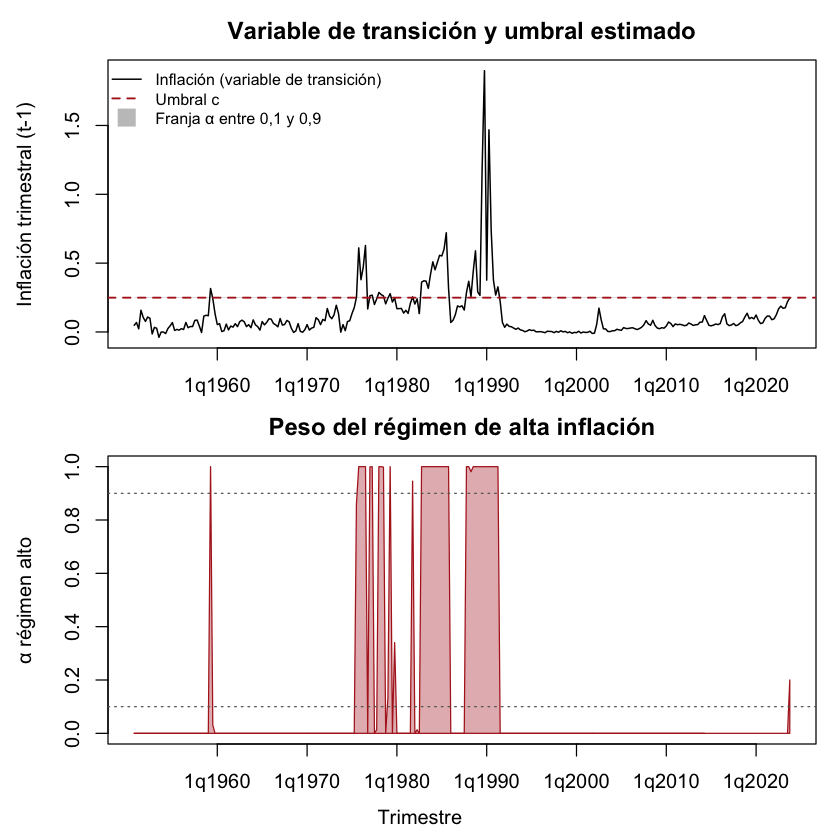

In [145]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_vlstar_3f_p2_sincap")

### Comparación con el TVAR principal y el VLSTAR en dos etapas

In [146]:
rbind(ic_tvar_p2, ic_vlstar_p2, ic_vlstar_3f_p2)
# Si ic_tvar_p2 o ic_vlstar_p2 no están en memoria, correr antes sus celdas con load_presaved = TRUE y criterios_info().

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR p=2,2,93,-896.09,1978.2,2115.3,2320.4
VLSTAR p=2,2,94,-928.90,2045.8,2184.3,2391.7
VLSTAR 3 etapas p=2,2,94,-929.33,2046.7,2185.2,2392.6


## VLSTAR (descartado por ahora)

Se conserva solo la estimación y el diagnóstico. Las soluciones que pasan el filtro de `sstvars` ajustan peor que el TVAR; las de mayor verosimilitud tienen la matriz de covarianza del régimen 2 casi singular (régimen de hiperinflación con 14–17 trimestres). Pendiente: probar errores t de Student.

Se cargó exitosamente modelos preguardados  vlstar_2_2_500_e9f2aea132c2dbca88b543e2af97bbb8.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


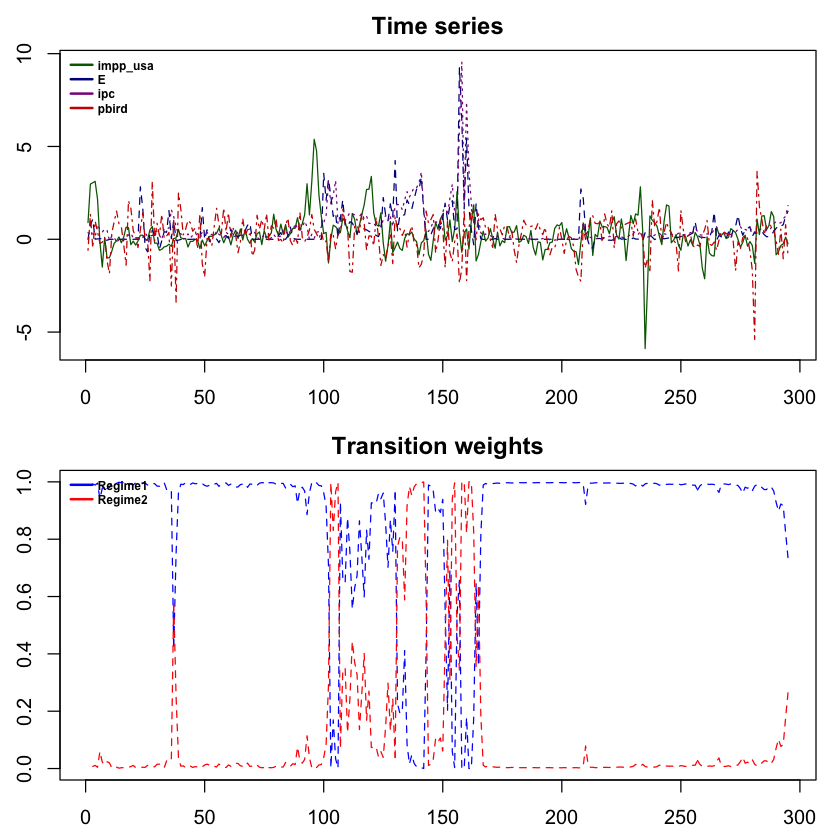

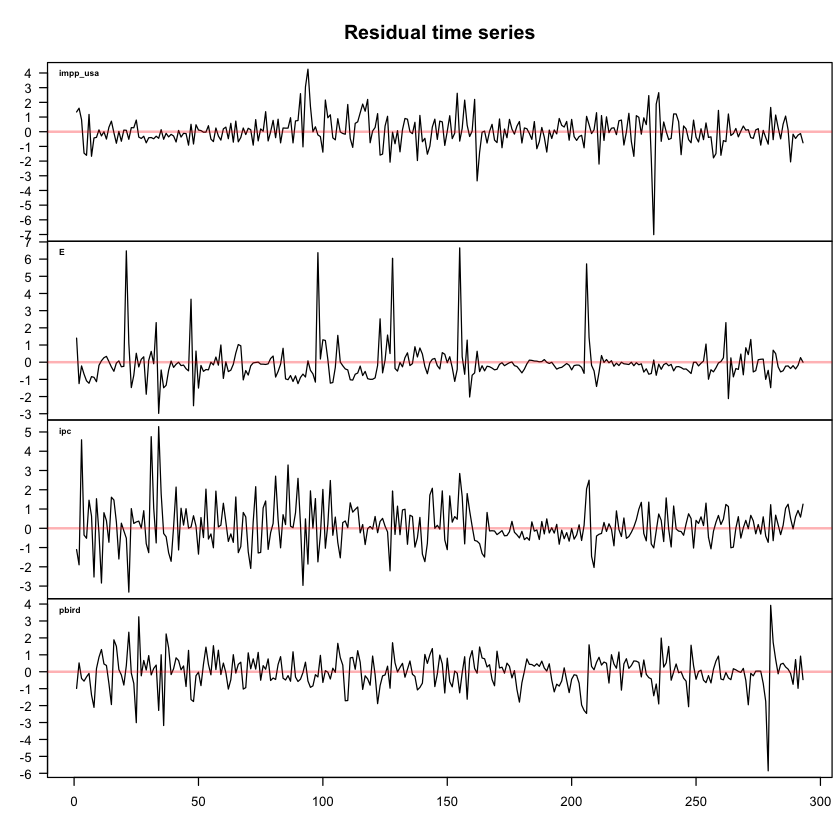

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



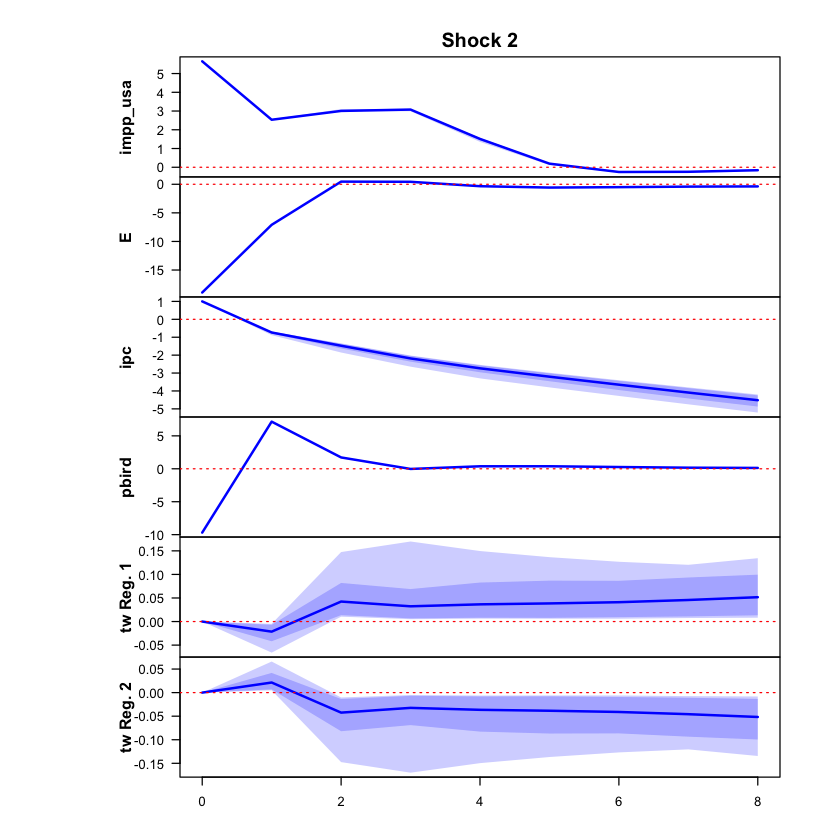

 >>> Linear IRF ( 1  shock units)


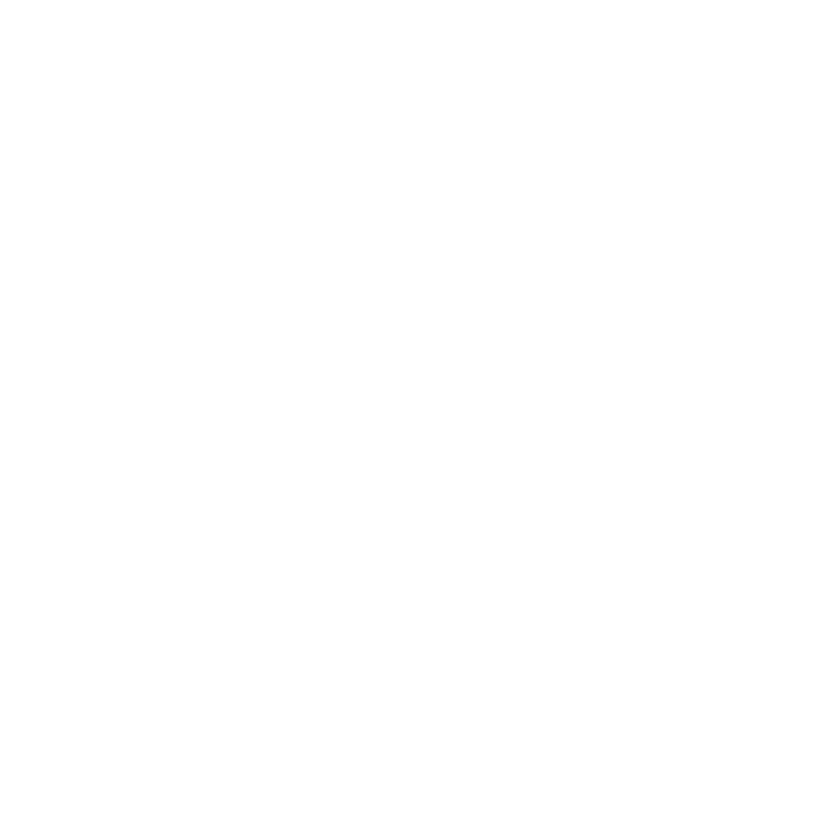

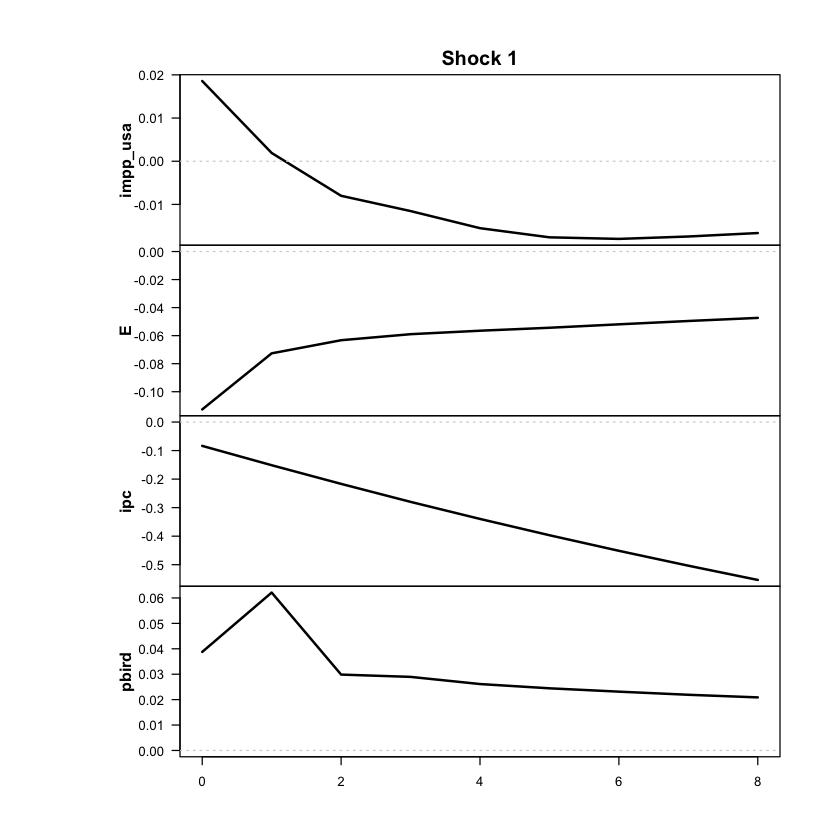

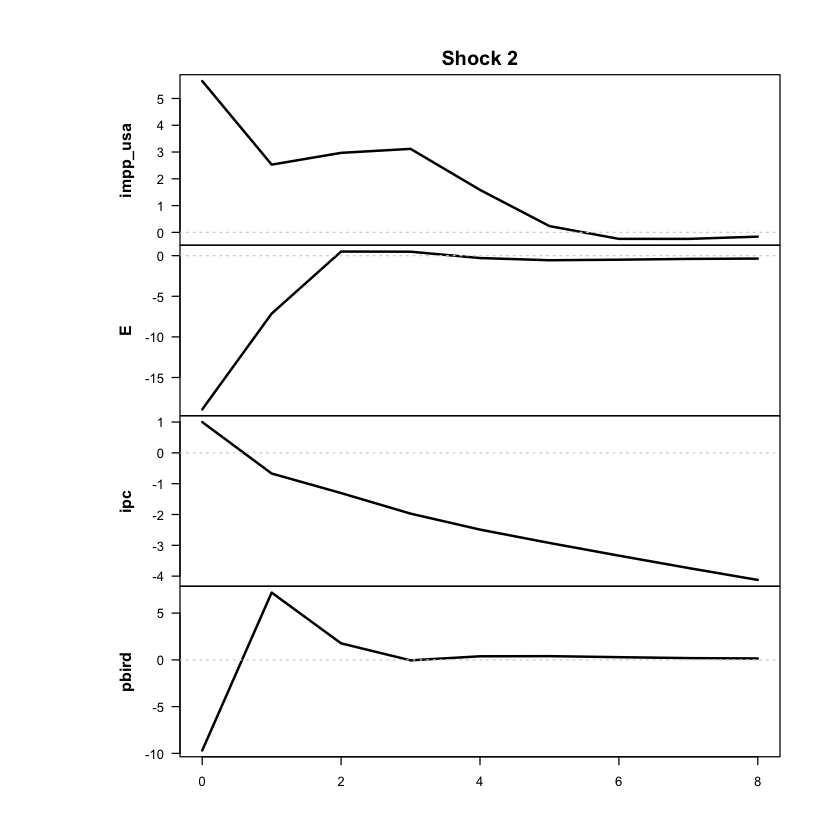

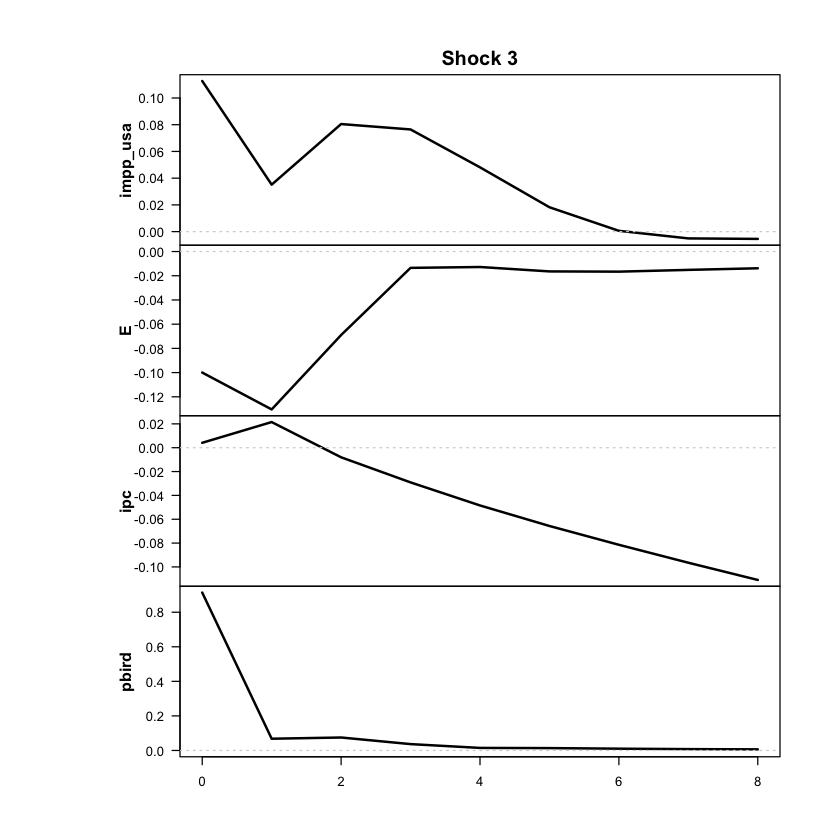

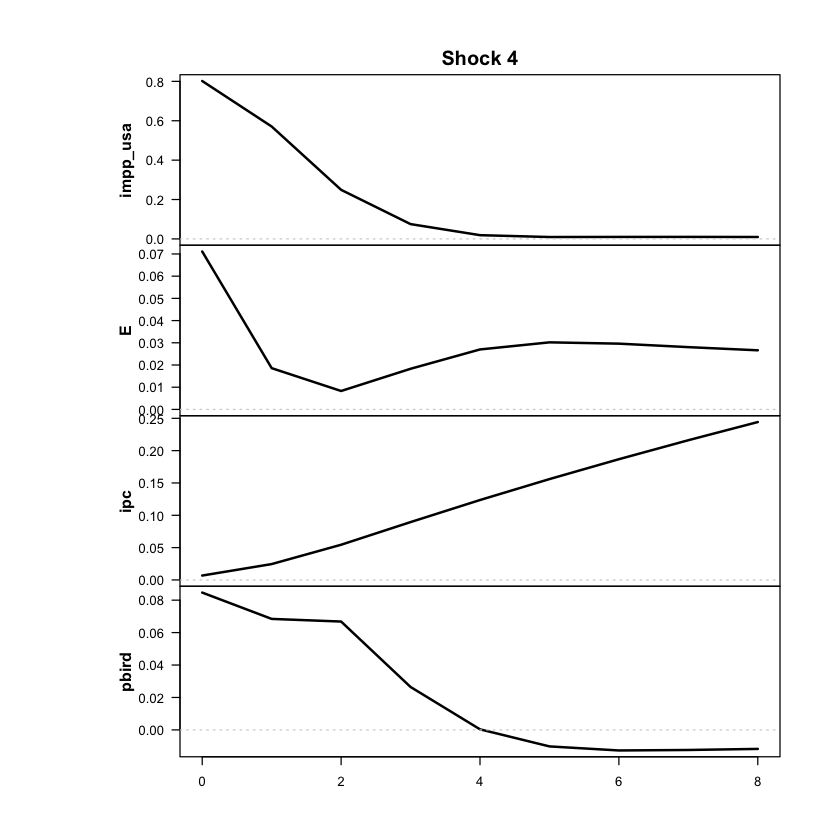

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



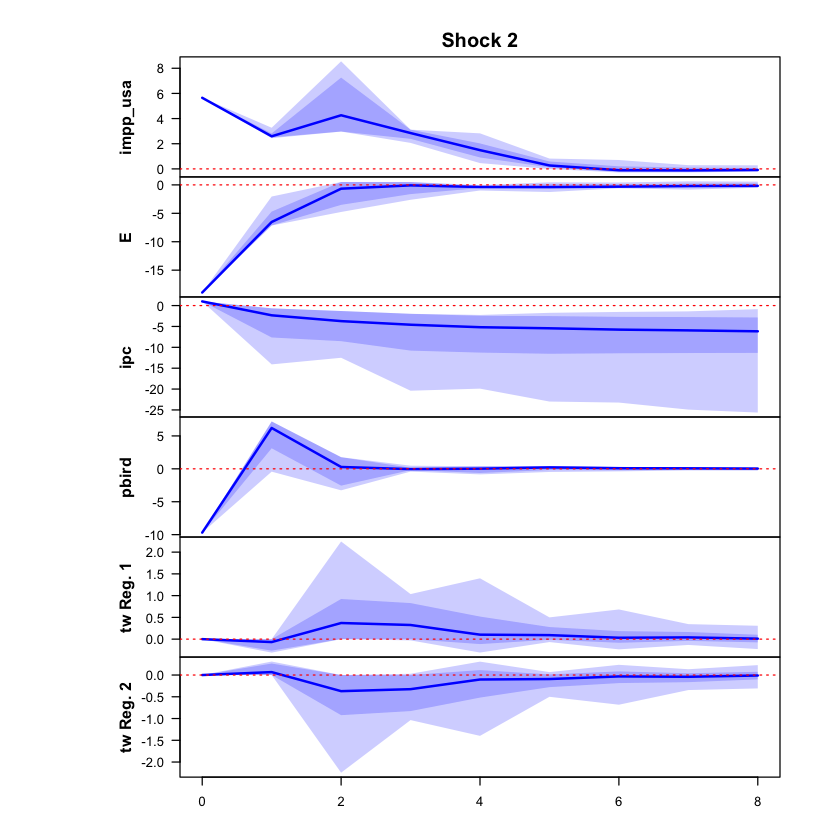

 >>> Linear IRF ( 1  shock units)


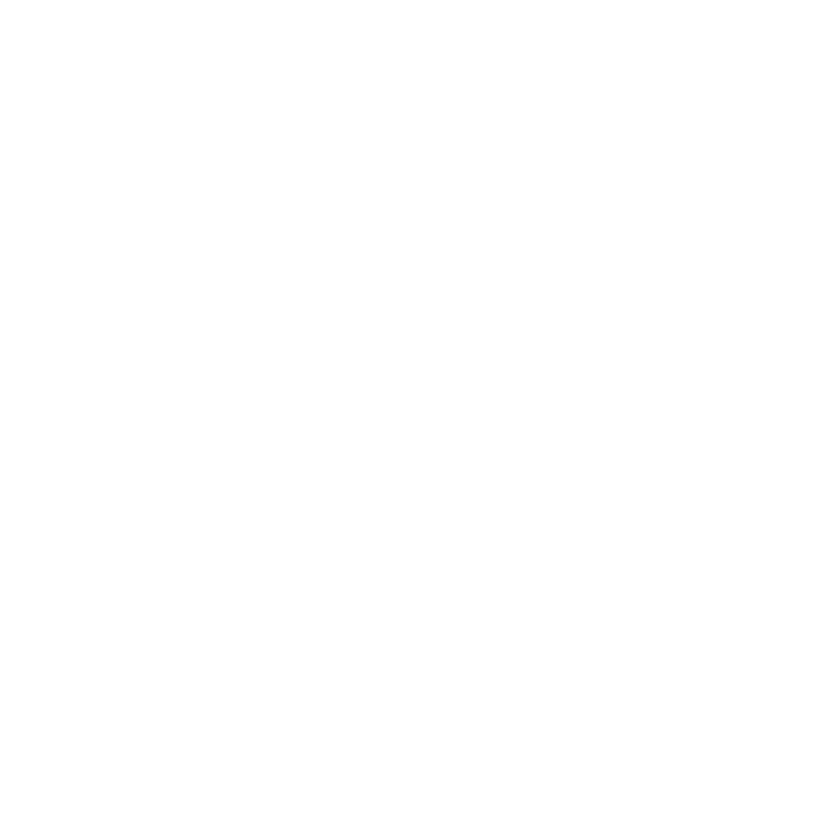

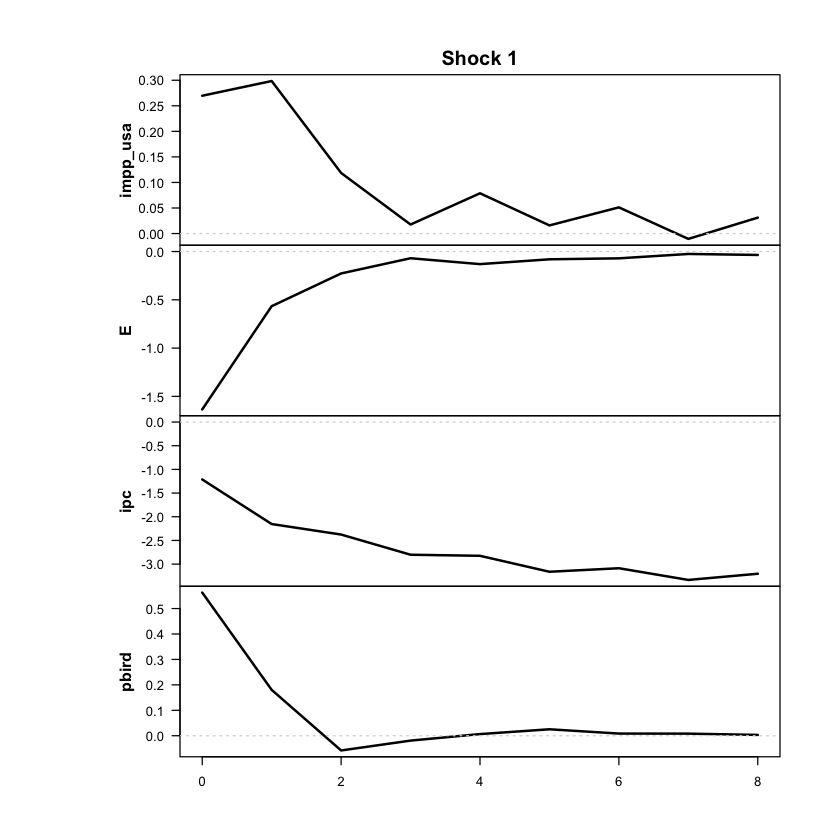

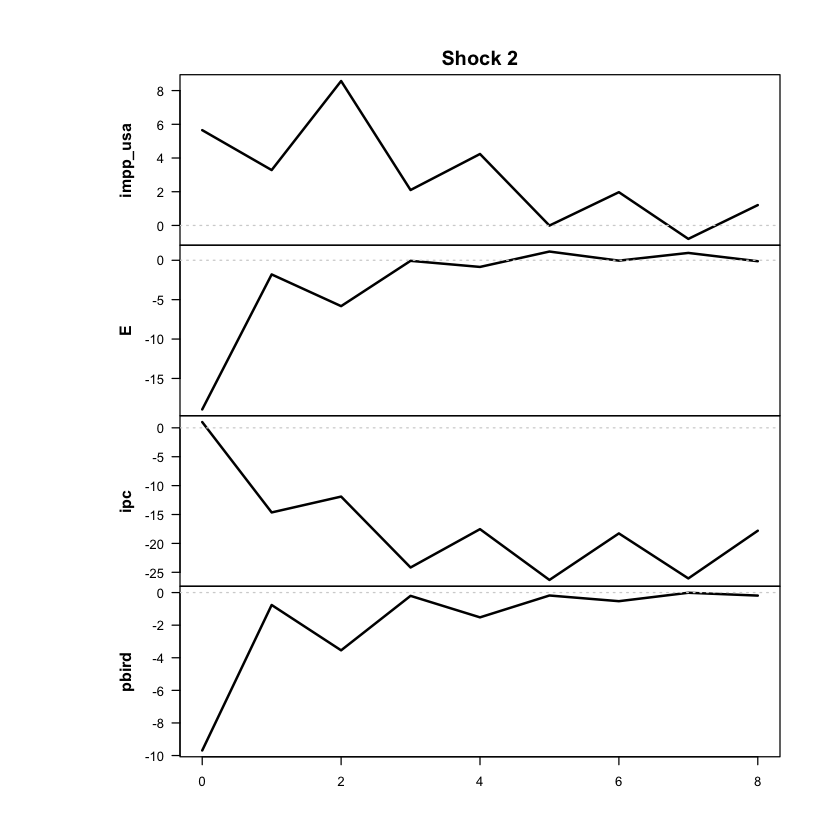

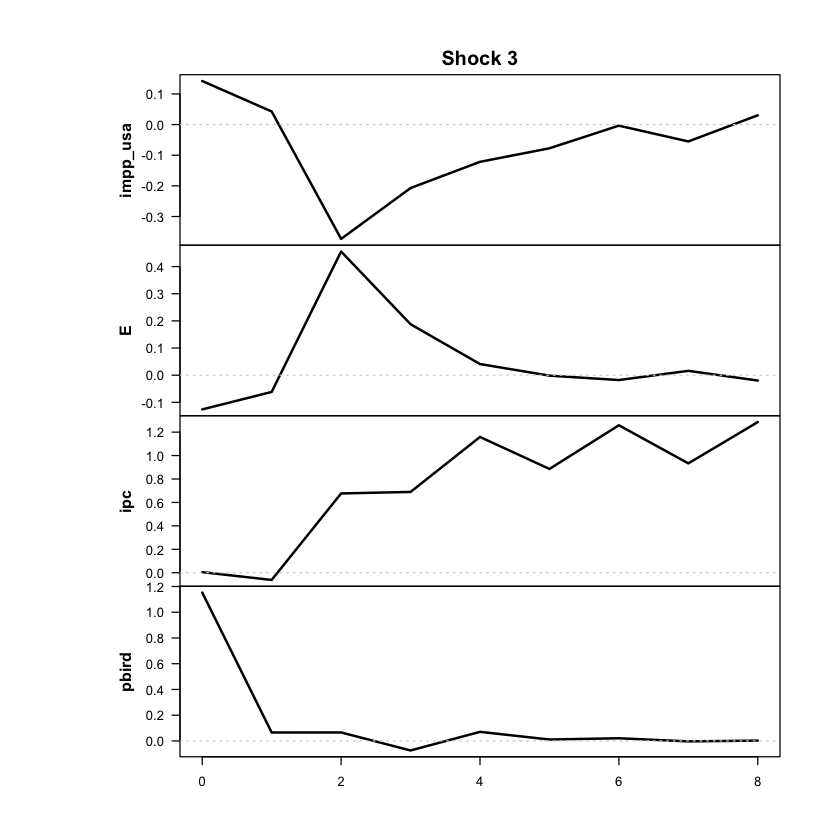

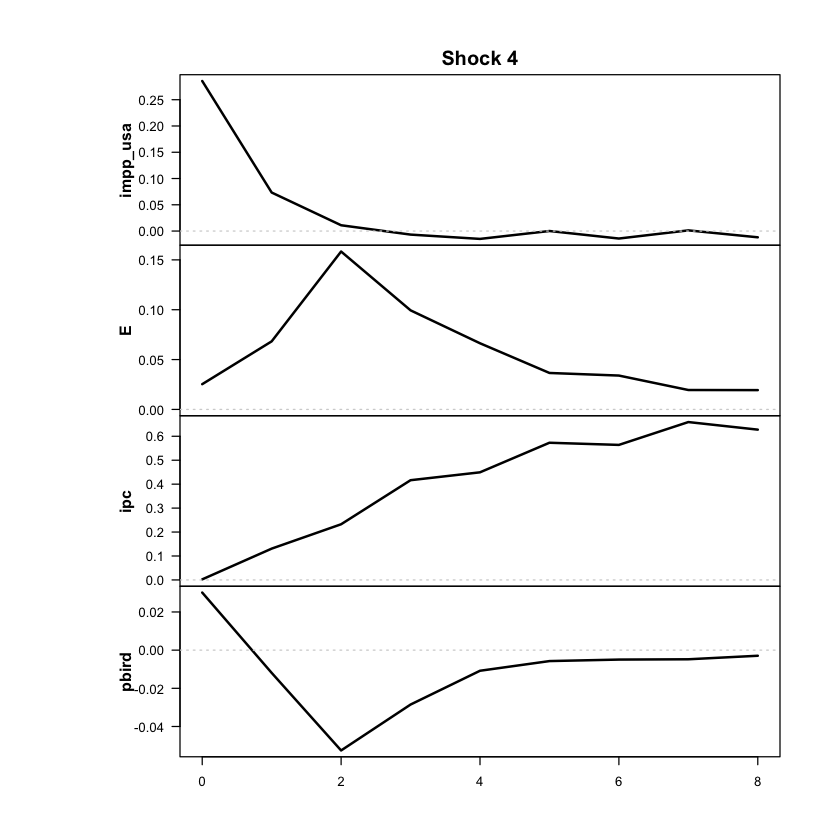

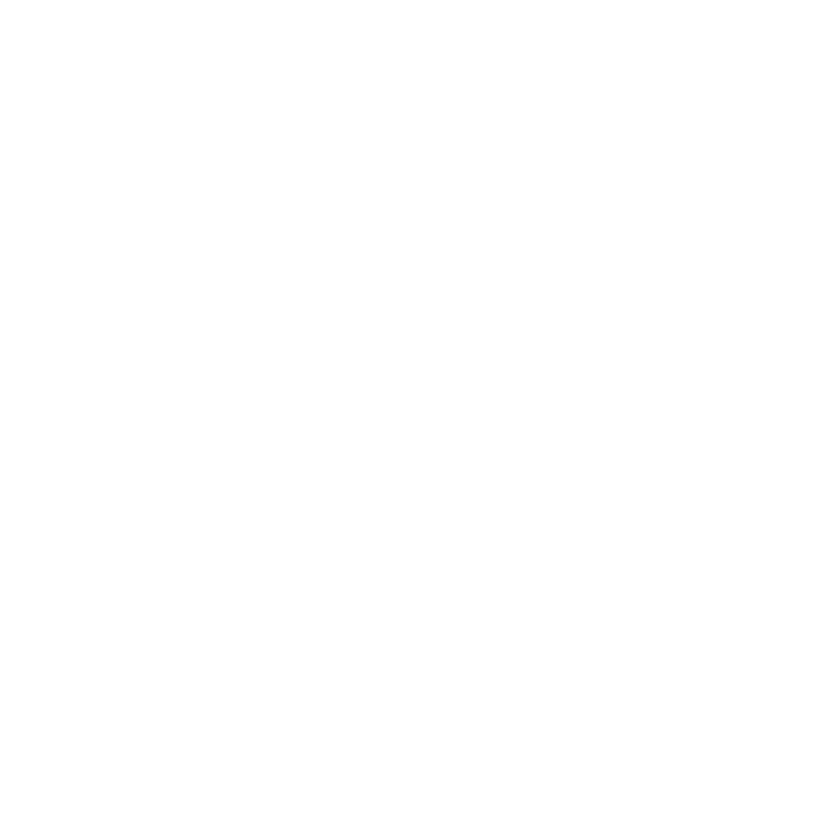

In [103]:
res <- run_vlstar (
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [104]:
ic_vlstar_p2 <- criterios_info(res, "VLSTAR p=2")
print(ic_vlstar_p2)
explorar_optimos(res, n = 20)

      modelo regimenes parametros loglik    AIC     HQ    BIC
1 VLSTAR p=2         2         94 -928.9 2045.8 2184.3 2391.7
umbral_trim_pct: umbral en % de inflación trimestral (solo VLSTAR)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma trim_reg_alto trim_transicion
             1 -878.59            38.9  3.55            14              37
             2 -879.03            39.5  3.66            14              36
             3 -880.23            38.9  3.57            15              36
             4 -880.37            39.1  3.55            14              37
             5 -880.89            38.6  3.73            15              35
             6 -881.55            39.0  3.69            15              35
             7 -881.90            39.0  3.68            15              35
             8 -881.98            39.4  3.52            14              36
             9 -882.27         

Se cargó exitosamente modelos preguardados  vlstar_3_2_500_d2defb6df84d4112af7e9b5364146217.rds  de la carpeta models

 >>> DIAGNOSTIC PLOTS


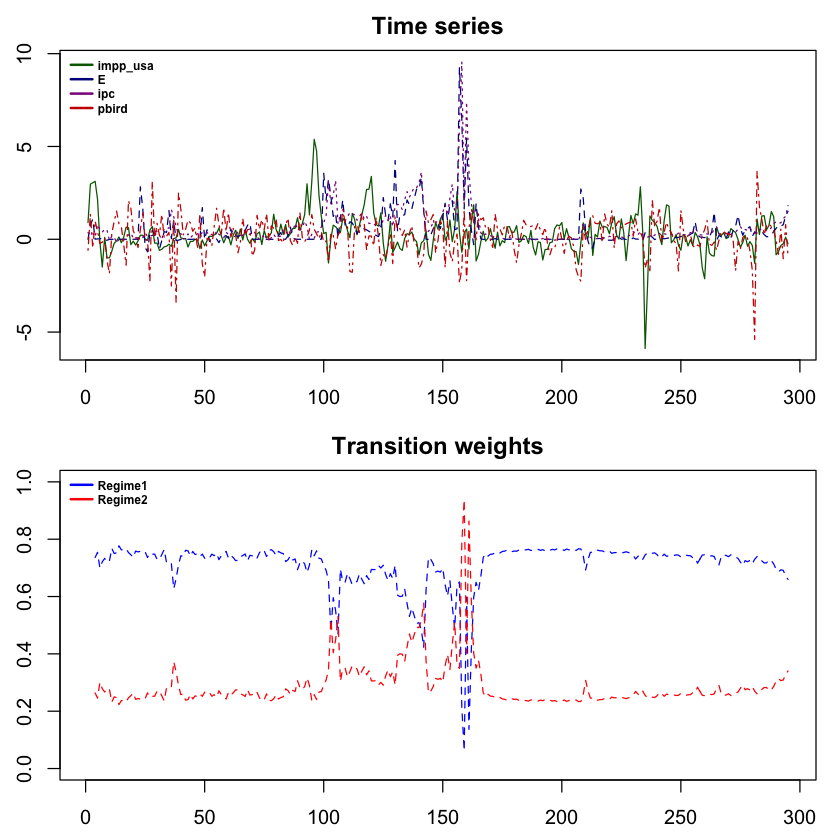

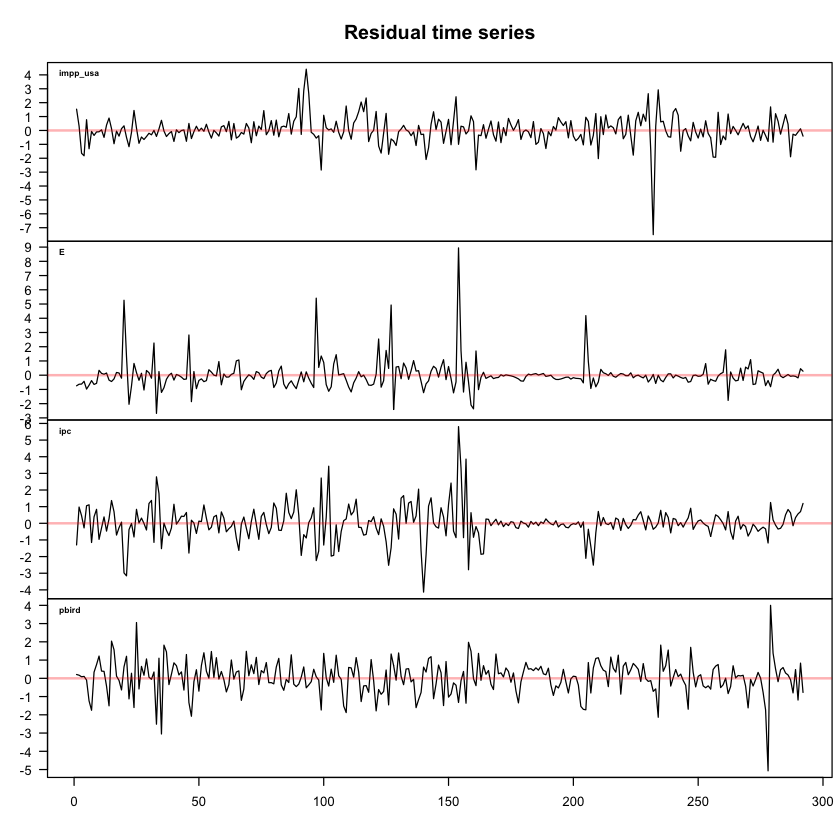

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



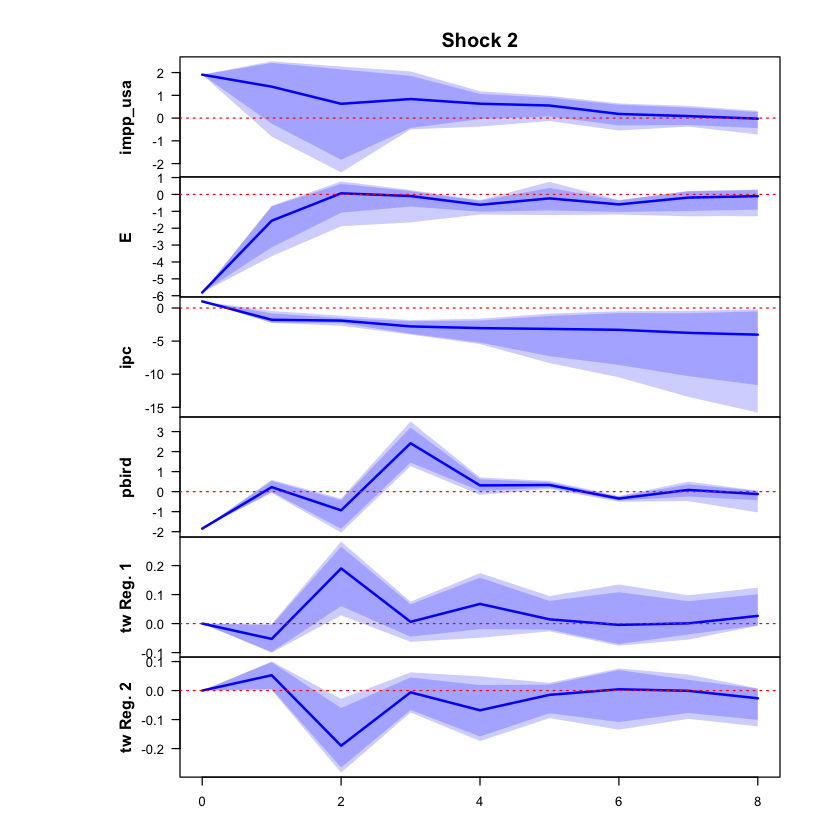

 >>> Linear IRF ( 1  shock units)


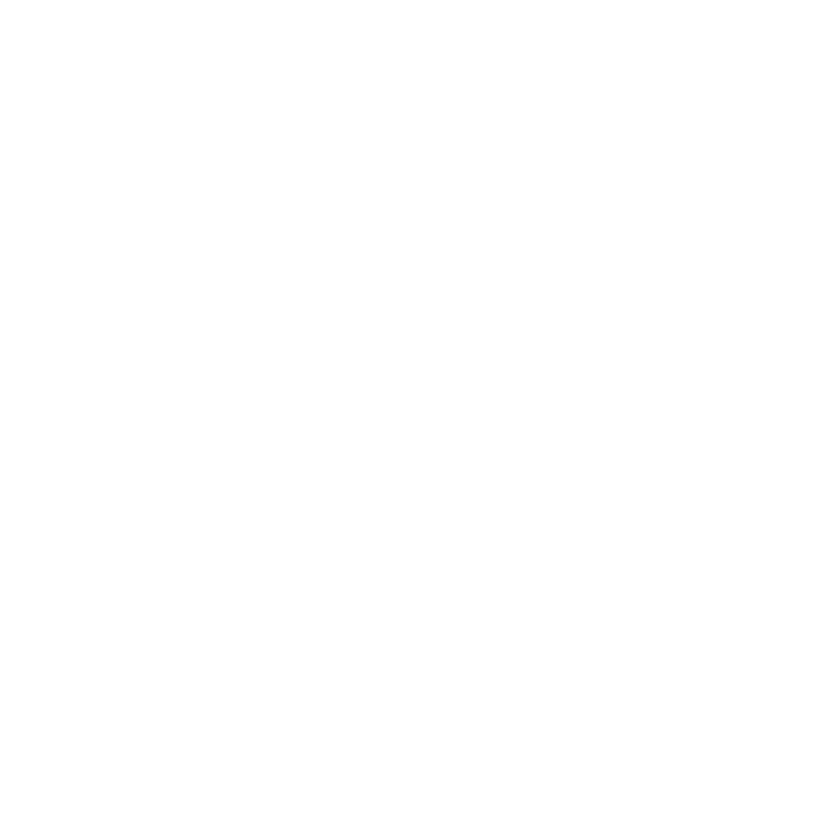

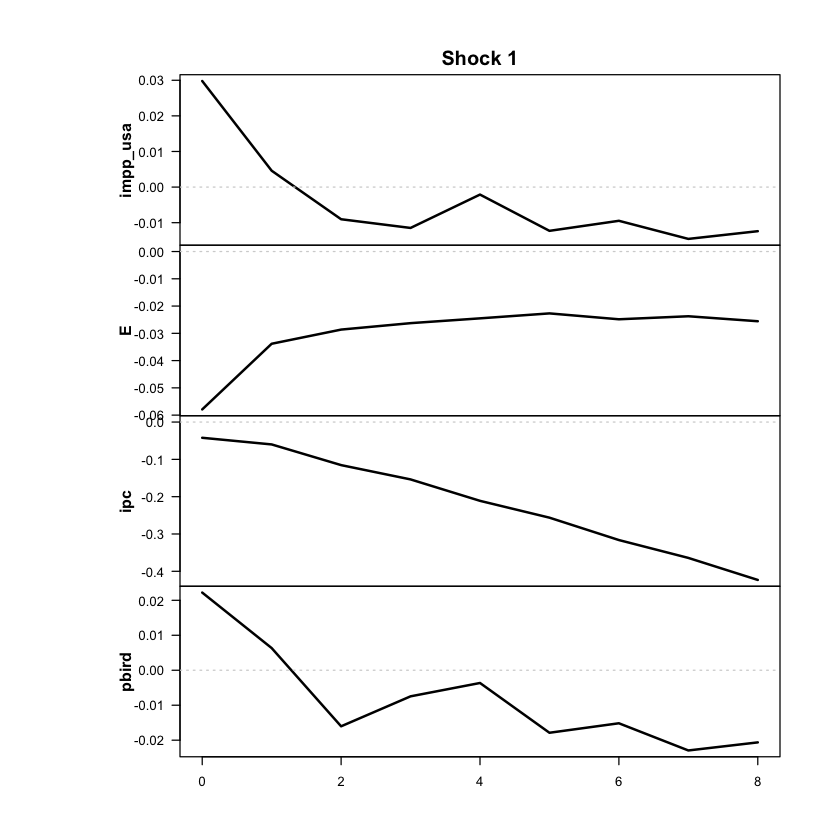

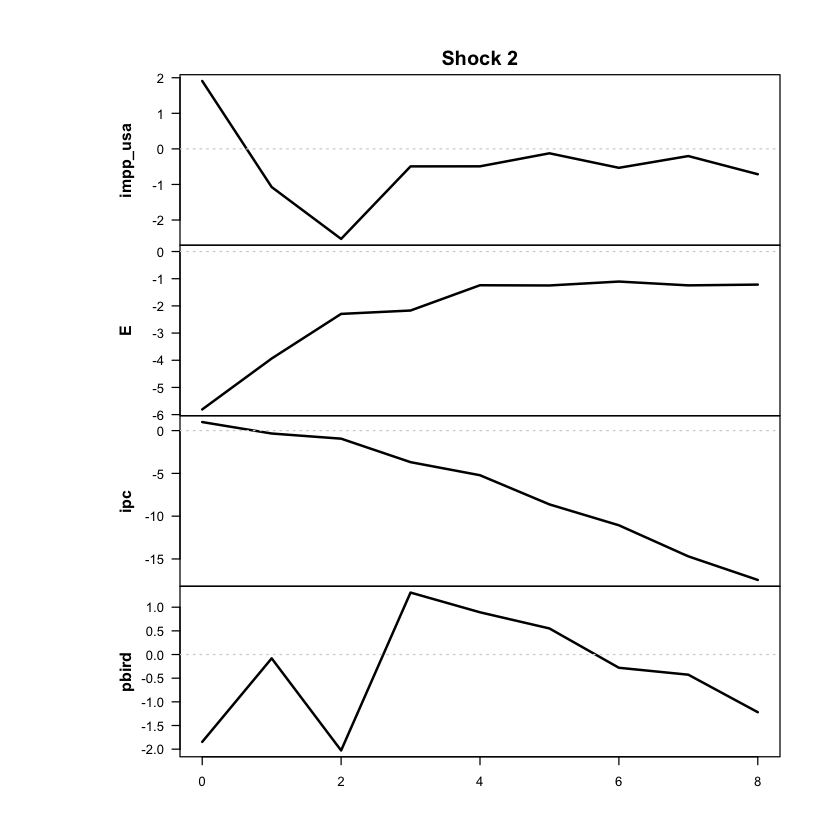

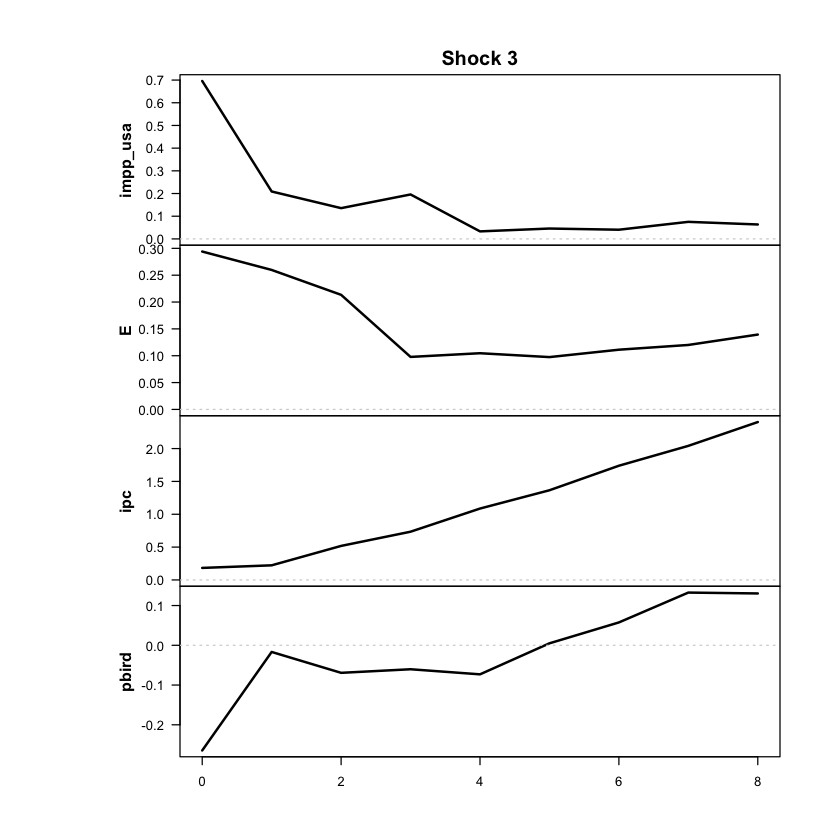

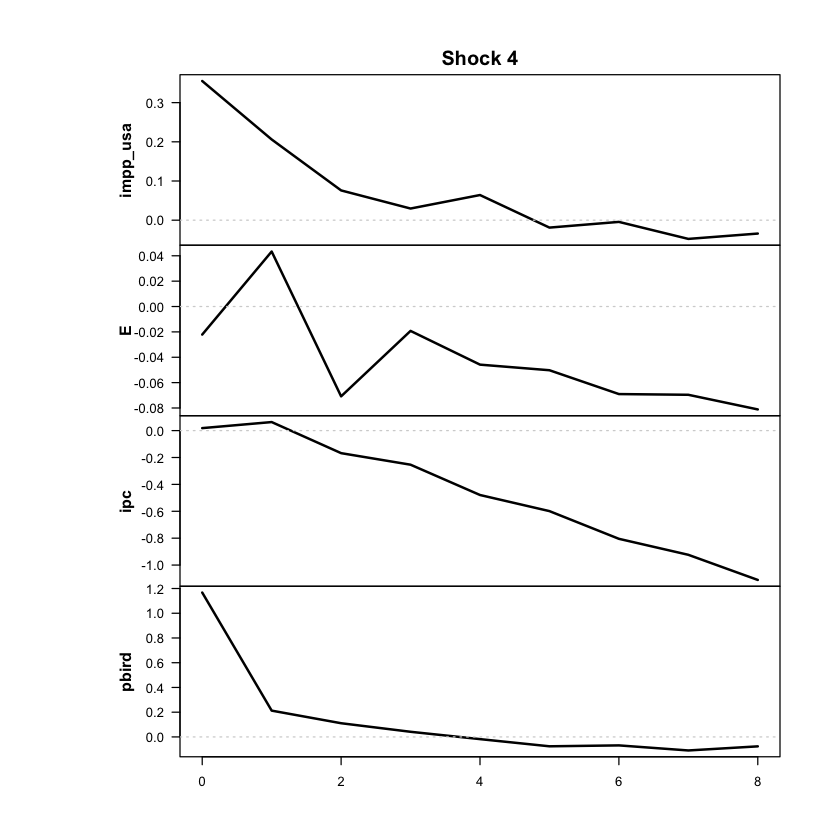

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



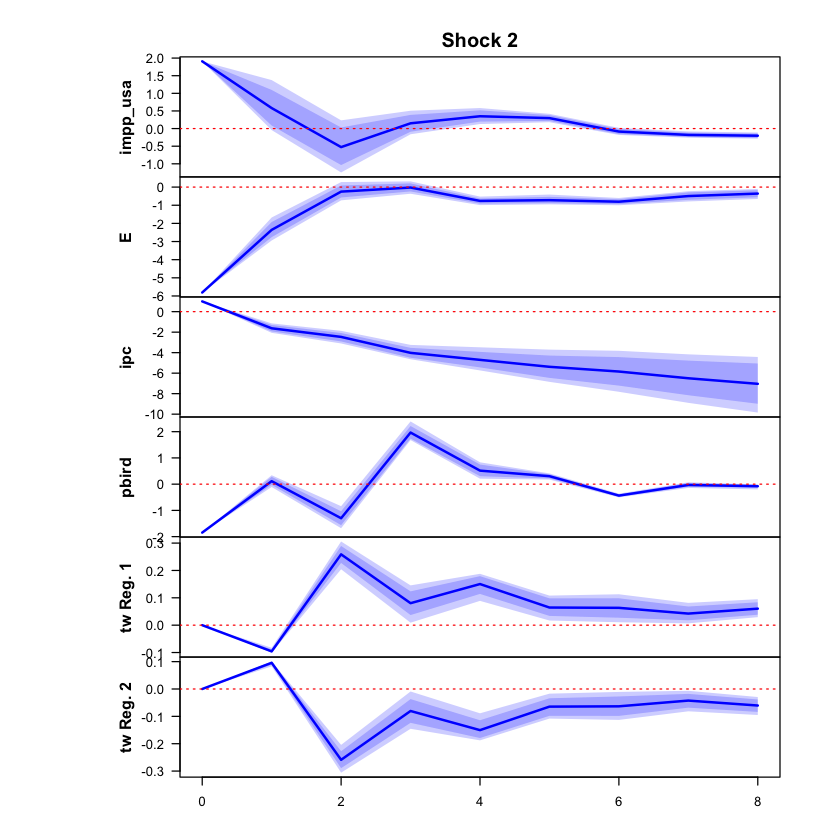

 >>> Linear IRF ( 1  shock units)


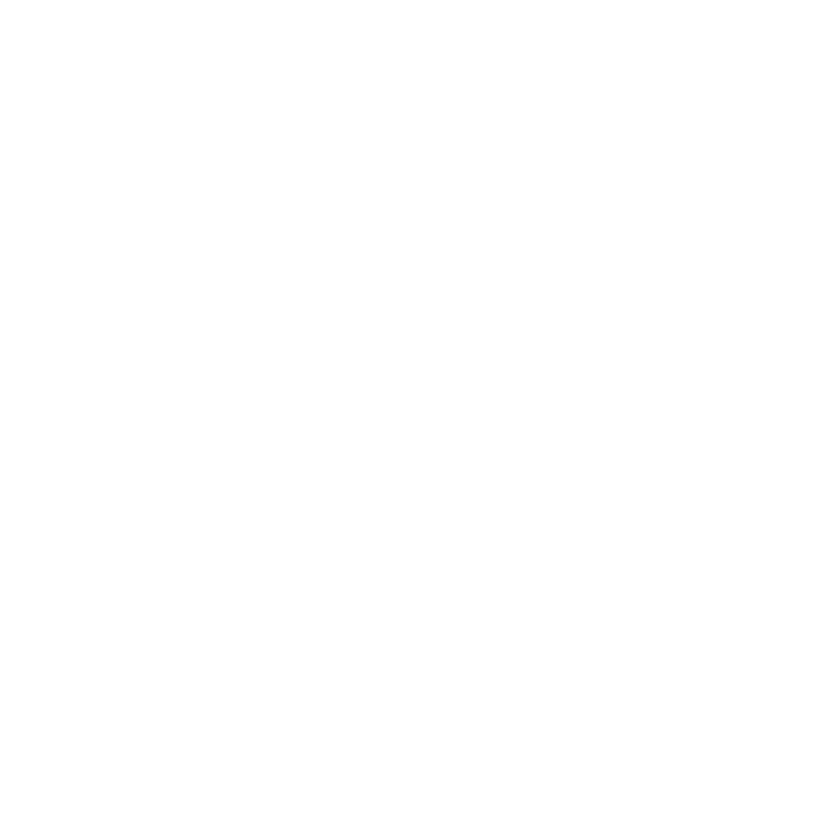

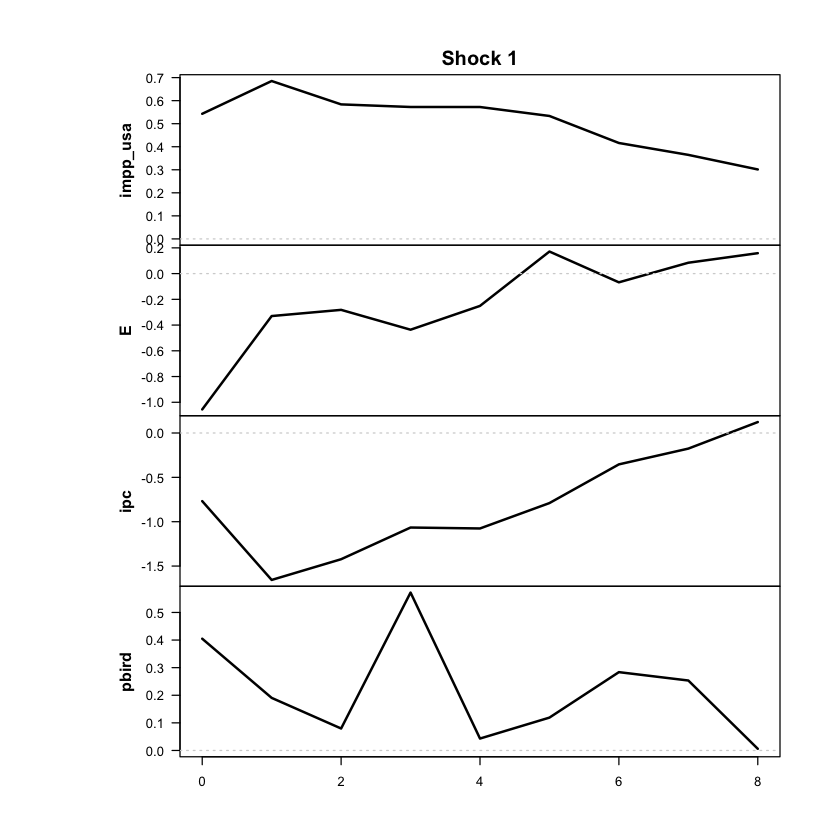

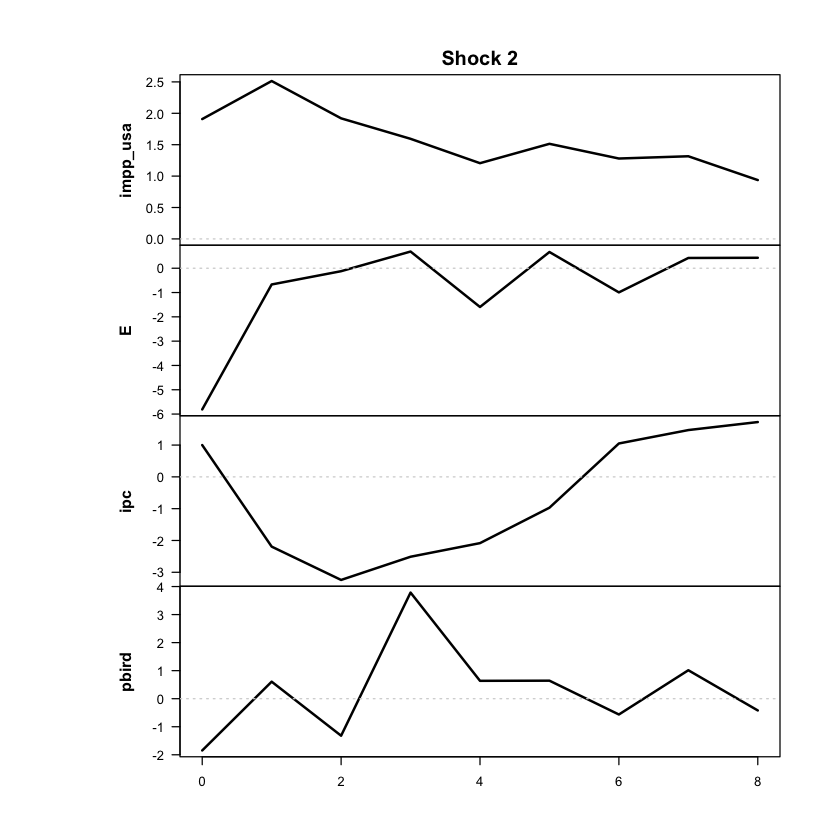

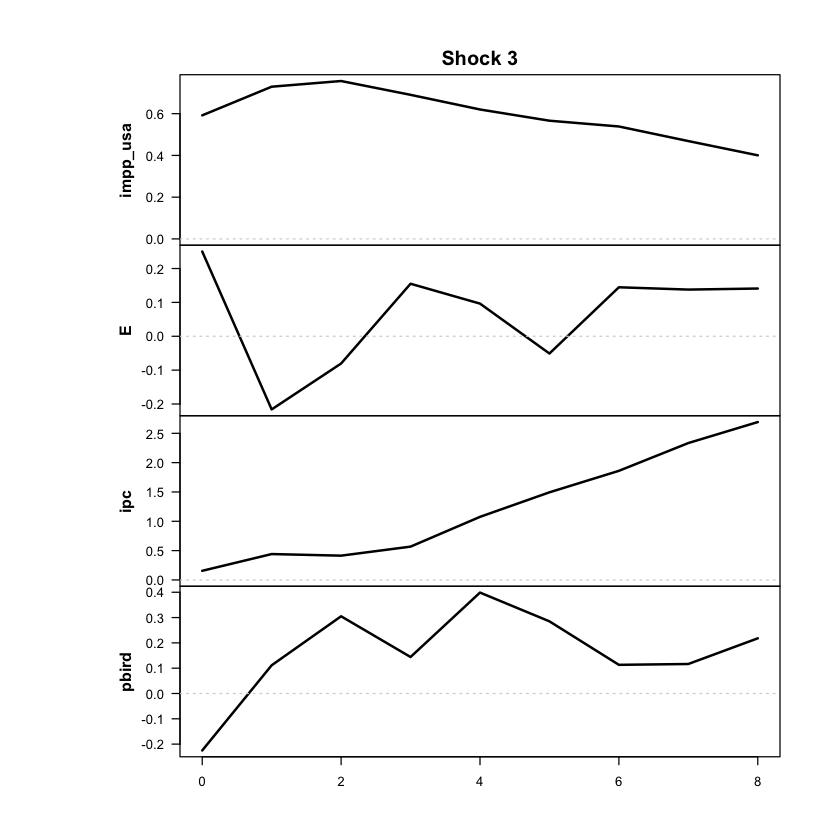

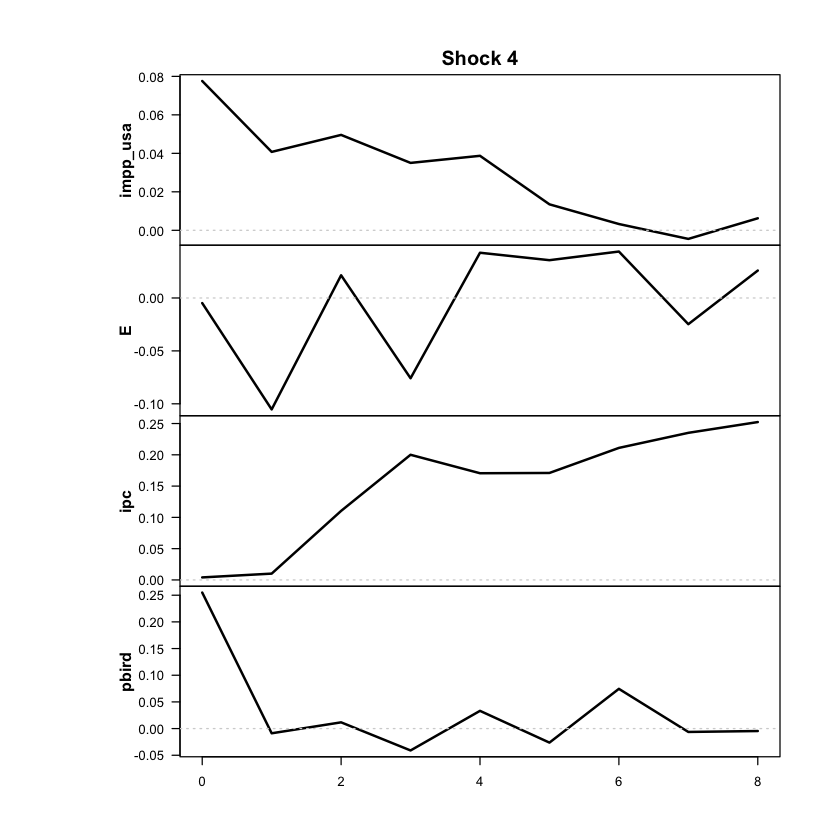

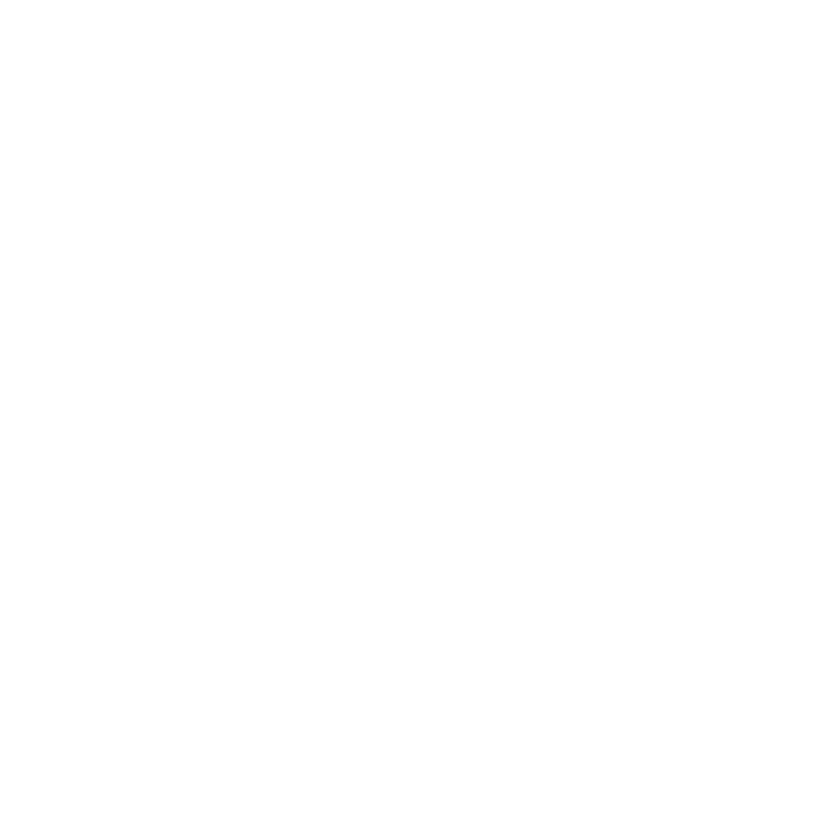

In [105]:
res <- run_vlstar (
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 3,
  n_regimes = 2,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = TRUE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [106]:
ic_vlstar_p3 <- criterios_info(res, "VLSTAR p=3")
print(ic_vlstar_p3)
explorar_optimos(res, n = 20)

      modelo regimenes parametros   loglik    AIC     HQ    BIC
1 VLSTAR p=3         2        126 -1122.62 2497.2 2682.8 2960.5
umbral_trim_pct: umbral en % de inflación trimestral (solo VLSTAR)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma trim_reg_alto trim_transicion
             1 -850.82            36.0  4.05            17              36
             2 -851.36            38.3  3.98            16              34
             3 -851.95            35.6  4.19            17              36
             4 -857.28            35.1  4.14            17              37
             5 -857.30            35.3  3.75            17              41
             6 -857.72            34.6  3.60            17              44
             7 -859.76            33.9  3.43            17              52
             8 -860.57            35.3  3.77            17              41
             9 -862.39     

# TEST de autocorrelación y de heterocedasticidad

Fuente: https://rdrr.io/cran/sstvars/man/Portmanteau_test.html

In [ ]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_sincap <- portmanteau_guardados(df_ERPT_Arg)
port_impp <- port_sincap[port_sincap$commodity == "impp_usa", ]
print(port_impp, row.names = FALSE)